# What do BTCUSDT volatility forecasts predict, and do mirrored barriers reveal direction?

**Study on `btcusdt_v2`** · Binance USDⓈ-M BTCUSDT perpetual · decisions every 10 minutes on `time_1m`, outcomes on a one-second trade tape · walk-forward test November 2025 to October 2026 (47,773 decisions, 360 days) · `EXPLORATORY`

> **Revision (2026-11-08).** This notebook has two parts. **Part I** (sections 1–10) is the original exploratory analysis, kept as run; a few interpretations were reworded and are marked *(revised wording)*. **Part II** (sections 11–17) adds the test the first version left open: whether volatility and mirrored-barrier forecasts improve a directional model when added to its existing features. It also tests whether a forecast-based "surprise" predicts continuation or reversal, rebuilds every forecast input out of sample with purged validation, and corrects the expected-payoff calculation. **Section 17 has the final answer table.** In short: predicted volatility adds nothing to direction; the barrier forecasts give at most one weak, half-placebo-sized gain at 60 minutes; forecast-based surprise adds nothing beyond ordinary normalisation; no combination improves trade selection beyond chance; and correcting the payoff removes a 3–6 bp bias without changing the economic conclusion. Everything remains `EXPLORATORY`.

## Summary of Part I

**Questions.** (1) Which aspects of future movement are predictable, at which horizons, beyond strong simple baselines, and does microstructure add anything? (2) At the same decision time, do attainment forecasts for two mirrored asymmetric barrier configurations (A: +1e / −2e, B: +2e / −1e) carry information about direction? (3) Do any of these forecasts help select trades?

**Short answers.**

1. **Volatility is predictable; everything else is predictable mainly through it.** Forecasts remove about 40% of the error of a "same as the last four hours" forecast for realised variance, at every horizon from 5 to 60 minutes, in every test month. The largest excursion (17–20%), barrier touch (8–9% of log loss, AUC 0.68–0.70) and absolute displacement (6–7%) are progressively less predictable. The order follows how much noise each outcome adds on top of volatility, and a forecast built only from predicted volatility matches the direct models almost exactly. Trendiness is essentially unpredictable. A nonlinear price, volume and calendar model beats the linear HAR baseline by 1–4 points; microstructure shows no consistent gain beyond placebo levels, only a few isolated small ones *(revised wording)*.
2. **The mirrored pair carries a small amount of real direction, but it is the same small reversal signal a direct model finds, and its predictive content is weak *(revised wording)*.** The two attainment forecasts correlate 0.86, and attainment itself is almost fully explained by geometry plus the volatility forecast. Their difference `D = P_A(hit) − P_B(hit)` has an information coefficient of 0.031 at 15 minutes and 0.020 at 60 with the subsequent return: above every time-shift placebo, positive in all four quarters, and about the same as a model trained directly on direction. Read as a drift forecast through Brownian geometry, its scale is five- to eightfold too large *(revised wording)*. One standard deviation of it is worth about 0.5–1 bp.
3. **No selection survives costs.** The side rules improve on a random side by up to 0.9 bps per trade. The best pre-specified gross is +0.81 bps per trade, with an interval from −0.18 to +1.80 (configuration choice at 60 minutes), so every policy breaks even at about 1 bp, against roughly 10 bps for a taker round trip. Attainment filters select larger moves, not better-directed ones.

| Question | Result | Key evidence (test, Nov 2025–Oct 2026) |
|---|---|---|
| Q1. Realised variance | **Predictable, stable** | Skill vs persistence 0.40–0.42 (HAR 0.36–0.39); typical volatility error ×1.34–1.45 vs ×1.47–1.62; positive in 12/12 months |
| Q1. Excursion, touch, displacement | **Partly, through volatility** | Skill 0.17–0.20, 0.08–0.09, 0.06–0.07; touch rate 21–24% in the bottom forecast decile vs 81–82% in the top; a volatility-only forecast matches the direct models within 0.01 |
| Q1. Trendiness (`r²/RV`) | **Essentially no** | Skill 0.01–0.02, rank correlation 0.05–0.07 |
| Q1. Microstructure | **No consistent incremental value** | `GBM-F − GBM-B` within ±0.006 skill points; a few isolated small gains (`rv` 5 min, `eff` 5–15 min); sign varies by month; comparable to placebo refits |
| Q2. Attainment of A and B | **Predictable, mostly geometry plus volatility** | AUC 0.66–0.68; closed-form `G-ρ` gets within 0.01 of the learned models |
| Q2. Direction from the pair | **Small, real, not special** | IC of `D` 0.031 [0.021, 0.043] at 15 min and 0.020 [0.002, 0.036] at 60; direct model 0.028 / 0.018; mostly short-term reversal from price features |
| Q2. Is `D` a direction probability? | **No** | Overlapping events; implied-drift slope 0.12–0.18 shows the geometric scaling is five- to eightfold too large *(revised wording: the slope alone does not give a noise share)* |
| Q3. Trade selection | **No economic value** (confirmed with corrected payoffs in section 16) | Best pre-specified gross +0.81 bps per trade [−0.18, 1.80]; side choice adds up to +0.9 bps over a random side; attainment gate selects size, not direction |

**How far this reaches.** One instrument and venue, one scale definition (trailing four-hour volatility), horizons of 5 to 60 minutes, decisions every 10 minutes at minute closes, frictionless barrier exits apart from stop slippage. All months have been explored by earlier notebooks, so nothing here is confirmatory. The request text was cut off after "Assess"; section 1 states how I read the remainder.

**How to read this notebook.** Section 1 gives the context and section 2 the design, written before any outcome was computed. Sections 3–5 build the data, outcomes, features and models. Section 6 answers question 1, sections 7–8 question 2 (theory first, then data), section 9 question 3, and section 10 gives the final answer. `POST-HOC` marks every analysis added after seeing results.

## 1. What earlier work established, and what this notebook asks

| Source | Finding | What it means here |
|---|---|---|
| `btcusdt_v2_predictive_exploration.ipynb` | Realised volatility is very predictable (R² about 80% on log RV), but microstructure adds nothing over a **nonlinear** price/volume/calendar model. Direction has one real, small, fast signal: top-of-book imbalance, about 0.67 bps per unit, mostly paid within 30 s | A strong nonlinear baseline is required. A high R² on log RV is mostly persistence and says little by itself |
| `btcusdt_v2_metalabeling_*.ipynb` | Meta-models predict **whether** a barrier is hit (AUC about 0.69), not **which** (about 0.50). AUC on a "net > 0" label rewards volatility, not money | Separate attainment from direction explicitly; judge selection by gross per trade against matched controls |
| `btcusdt_v2_delayed_entry_pilot.ipynb` | Apparent directional AUC after a delay was pure barrier geometry; a closed-form Brownian model matched it. Attainment AUC 0.68 | Always compare barrier forecasts with the closed-form geometric answer |
| `docs/DATASET_V2.md`, `LIMITATIONS.md`, `VALIDITY_MAP.md` | Features are as-of `eval_time`, one nanosecond before the decision. Book must be valid (`book_state` 0 or 9). Strict windows can be missing in stress. One retrospective quality incident | Same eligibility rules and incident exclusion as before |

**The three questions.**

1. **What aspect of movement is predictable, and how well?** Realised volatility, absolute displacement, the largest excursion, and touching a ±1e barrier are related but different outcomes. Which are predictable, at 5, 15 and 60 minutes, beyond strong simple baselines, and does microstructure add anything?
2. **Do mirrored asymmetric barriers reveal direction?** Configuration A puts the upper barrier at +1e and the lower at −2e; configuration B mirrors it. Do the two attainment forecasts, their difference, or a better joint representation predict direction, signed return, or which side is more attractive?
3. **Do these forecasts help select trades?** Choosing a side, filtering on attainment, or choosing a configuration, judged by gross return per trade against random controls.

**The request text was cut off** after "Assess". I read the remainder as: assess whether any joint representation carries information beyond the individual forecasts and beyond a directly trained direction model, and then whether it helps trade selection. Question 3 is my reconstruction of the third connected question.

**Status: `EXPLORATORY`.** Every month through October 2026 was explored by earlier notebooks, so no result here is confirmatory. The design in section 2 was written before any outcome was computed. Diagnostics added after seeing results are marked `POST-HOC`.

## 2. Design, fixed before any outcome was computed

### 2.1 Decision times and the movement scale `e`

**Decisions** are taken every 10 minutes on the `time_1m` grid (minute closes at :00, :10, …), from 22 July 2025 to the end of October 2026. A 10-minute spacing keeps about 68,000 decisions; adjacent one-minute rows would add near-duplicates, not information.

**The reference price `P0`** is the last trade strictly before the decision second. Outcomes are resolved on a one-second high/low/last tape built from every trade, over the seconds `[t, t + H)`.

**The movement scale** is

$$e_t(H) = \hat\sigma_t \sqrt{H}, \qquad \hat\sigma_t = \sqrt{\tfrac{1}{240}\textstyle\sum_{k=0}^{239} r_{t-k}^2},$$

the root mean square of the last 240 one-minute log returns (all known at `t`), floored at 0.2 bps per minute, times the square root of the horizon in minutes. Why this choice:

* **It uses only information at `t`** and is fixed at initiation: the barriers of one decision never move.
* **It is deliberately simple and independent of the forecasting models.** If `e` came from a fitted volatility model, the model's errors would be baked into the barrier labels, and "is attainment predictable" would become "is the model's own error predictable". With a trailing estimate, attainment is predictable exactly to the extent that **future volatility differs predictably from the last four hours**. That links question 1 and question 2 directly.
* **Four hours** matches the earlier pilots and balances responsiveness against noise. The scale is a natural unit: under a driftless random walk with constant volatility, a move of `1e` is one standard deviation of the horizon return.

### 2.2 Question 1: targets

For horizons `H` of 5, 15 and 60 minutes, all measured from `P0` on the one-second tape and normalised by `e`:

| Target | Definition | What it measures | Model and loss |
|---|---|---|---|
| `rv` | `log(RV / e²)`, RV = sum of squared one-second log returns over `[t, t+H)` | Total variation, the classic volatility target | Regression, squared error on the log |
| `abs` | `|r_H| / e`, with `r_H` the log return from `P0` to the last price before `t+H` | Net displacement at the deadline | Regression, squared error |
| `exc` | `log(max(up, down) / e)`, the largest excursion from `P0` in either direction | How far the path travels | Regression, squared error on the log |
| `touch` | 1 if `max(up, down) ≥ 1e`, i.e. a symmetric ±1e barrier is touched before `t+H` | Barrier attainment | Binary, log loss |
| `eff` | `r_H² / RV`, the share of total variance that ends as net displacement | Trendiness given volatility; mean 1 for a random walk | Regression, squared error |

These are nested on purpose. Under a random walk with volatility `σ_f`, all of the first four are noisy functions of **one** latent number, the ratio of future to trailing volatility. They differ in how much measurement noise sits on top of it: RV averages thousands of squared returns, the excursion follows the whole path, and the displacement is a single draw. `eff` asks whether anything beyond volatility, such as trending or choppy regimes, is predictable.

### 2.3 Question 1: models and baselines

| Name | Inputs | Purpose |
|---|---|---|
| `NAIVE` | Nothing: the training mean of the normalised target (base rate for `touch`) | "Future volatility equals the last 4 hours, times a constant": pure persistence |
| `HAR` | Linear (ridge or logistic) on log volatility over 15 min, 1 h, 4 h, 24 h, one-second RV over 2 and 15 min, a time-of-day seasonal prior, hour harmonics, weekend | The standard strong simple baseline for volatility |
| `GBM-B` | LightGBM on `HAR` inputs plus past returns, range, close location, drawdown, volume and trade count relative to their 7-day mean, day of week, semivariance asymmetry, recent jump size | Nonlinear price, volume and calendar baseline |
| `GBM-F` | `GBM-B` plus 32 microstructure features: trade flow, queue imbalance, OFI, depth, spread, sweep cost, basis, funding, open interest, liquidations | Does microstructure add incremental value? |
| `PLACEBO` | `GBM-F` refit with the microstructure columns permuted jointly across training rows (2 draws) | Null for "microstructure adds": same flexibility, no information |
| `ORACLE` | The **realised** future `rv` alone (for `abs`, `exc`, `touch`) | Diagnostic benchmark: how much of each target is explained by knowing the realised future one-second RV. *(Revised wording: originally called a "ceiling". It is not a proven upper bound, since a model can use path information that RV does not contain, and one-second RV is itself a noisy measure.)* |

LightGBM settings are fixed and conservative (learning rate 0.03, 15 leaves, at least 200 rows per leaf). The number of rounds is chosen by early stopping on the last 15% of each training window, after a one-day purge, and the model is then refit on the full window. No hyperparameter search.

### 2.4 Question 2: mirrored asymmetric barriers

For `H` of 15 and 60 minutes, at the same `t` and `P0`, with the same `e` and expiry:

| Configuration | Upper barrier | Lower barrier |
|---|---|---|
| **A** | `P0·exp(+1e)` | `P0·exp(−2e)` |
| **B** | `P0·exp(+2e)` | `P0·exp(−1e)` |

Each configuration has three mutually exclusive outcomes: **upper first**, **lower first**, **neither before expiry**. A second where both barriers are touched is ambiguous; it is counted and dropped from three-class labels.

**The outcomes overlap across configurations.** A path that reaches +1e and later −1e, without reaching +2e or −2e, is "upper first" in A and "lower first" in B. So `P_A(hit) − P_B(hit)` is a difference of two overlapping events. It is not a probability of anything, and section 9 derives what it does and does not measure before any model is fitted.

**Models.** For each configuration: a binary LightGBM for "either barrier reached" and a three-class LightGBM for the outcome, on the `B` and `F` feature sets. The yardstick is the closed-form driftless Brownian answer, with volatility taken from the question-1 forecast (`G-ρ`, section 9).

**Directional representations tested** (all out of sample):

| Score | Definition |
|---|---|
| `D_hit` | `P_A(hit) − P_B(hit)`, from the binary models |
| `D_logit` | `logit P_A(hit) − logit P_B(hit)` |
| `S3` | `EV_A + EV_B`, the model-implied expected barrier-exit return summed over both configurations, from the three-class models, with `EV_c = u_c·P_c(upper) − l_c·P_c(lower)`. It is exactly zero for any symmetric (driftless) process |
| `Stage-2` | Logistic regression of "price up at expiry" on all six configuration probabilities, fitted walk-forward on earlier test blocks only |
| `Direct` | A LightGBM trained directly on "price up at expiry", same features |
| `qi_1` | Raw top-of-book queue imbalance, the one known direction signal, no fitting |

**Directional targets.** Sign and size of `r_H`, the barrier-exit return of each configuration (long payoff of A and of B), and which side of a symmetric ±1e barrier is touched first.

### 2.5 Question 3: trade selection

Frictionless barrier-exit returns in bps from `P0`: the take-profit fills at the barrier, the stop fills at the **worst price of the second** it is touched, and an untouched trade exits at the last price before expiry. Four trades exist at each decision: long or short, in configuration A or B. Policies are fixed in advance:

1. **Side choice:** trade every test decision, side from the sign of a score centred on its training median.
2. **Attainment filter:** trade only decisions whose attainment forecast is in the top 30% of its training distribution, with a random side or the `D_hit` side.
3. **Configuration choice:** choose the trade with the largest model-implied expected value among the four, and trade only the top 30%.

Every result is compared with a random side on the same rows (isolates direction) and the same trade choice on random rows (isolates selection). Per-decision averages overlap in time at `H = 60`, so they describe the average signal, not a position-limited portfolio; uncertainty comes from the day-block bootstrap below.

### 2.6 Validation and inference

* **Walk-forward, expanding window**, four quarterly test blocks: Nov 2025–Jan 2026, Feb–Apr, May–Jul, Aug–Oct 2026. Training decisions must have their outcome window end at least 24 hours before the block starts. Training starts on 22 July 2025, after warm-up and at a feed cadence boundary.
* **The October 2025 crash** (9–11 October) is excluded from training. It lies before the first test block.
* **Eligibility, the same for every model and target:** `book_state` 0 or 9, valid trade-flow and OFI windows, a fresh price, complete bars, a finite 4-hour and 24-hour volatility, no trade gap over 120 s inside the 60-minute outcome window, and no quality incident within `[t − 15 min, t + 60 min]`.
* **Uncertainty:** moving-block bootstrap over test **days**, blocks of 5 days, 1,000 draws, the same draws for every model so differences are paired. Decisions overlap at `H = 60`, and resampling whole days keeps that dependence.
* **Placebos:** permuted-microstructure refits for incremental value, and circular time shifts of each directional score (shift by 7 to 56 days) to get a null that preserves the autocorrelation of both score and outcome.

### 2.7 What I expect, written before running

1. `rv` will be the most predictable target, `exc` and `touch` intermediate, `abs` weak, and `eff` essentially unpredictable. `GBM-B` will beat `HAR` a little; microstructure will add little or nothing over `GBM-B`.
2. The attainment forecasts of A and B will be almost perfectly correlated, because both are dominated by volatility. Their difference will carry at most a tiny amount of direction, mostly from queue imbalance at 15 minutes, and nothing at 60 minutes.
3. No selection policy will produce a gross edge distinguishable from zero.

## 3. Setup

**Environment.** Conda environment `disertatie`. Model fits run in forked worker processes; LightGBM runs single-threaded inside each, because concurrent LightGBM threads segfaulted in an earlier notebook.

**What it touches.** It reads `derived/datasets/btcusdt_v2` (`time_1m` only) and `derived/canonical/trades`, and writes nothing except itself. The last cell checks the sources are unchanged. `VBI_CACHE` (optional) caches heavy stages; `VBI_WORKERS` sets the number of workers.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[_v] = "1"
import json, multiprocessing as mp, pickle, platform, resource, sys, time, warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
import lightgbm as lgb
import numba
import scipy
import sklearn
from numba import njit
from scipy import stats
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression, Ridge
from IPython.display import display

T0 = time.time()
SEED = 20261108
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data/cryptohftdata/derived/datasets/btcusdt_v2/manifest.json").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the QuantForge repository.")

ROOT = find_repo_root()
CHDDS = ROOT / "data/cryptohftdata"
DATA = CHDDS / "derived/datasets/btcusdt_v2"
TRADES = CHDDS / "derived/canonical/trades"
sys.path.insert(0, str(CHDDS))
from chdds.dataset import incident_rows

man = json.loads((DATA / "manifest.json").read_text())
CACHE = os.environ.get("VBI_CACHE")
WORKERS = int(os.environ.get("VBI_WORKERS", "12"))

def source_fingerprint():
    files = sorted(DATA.rglob("*.parquet")) + [DATA / "manifest.json"] + sorted(TRADES.glob("*.parquet"))
    return (len(files), sum(f.stat().st_size for f in files), max(f.stat().st_mtime_ns for f in files))
FINGERPRINT_START = source_fingerprint()

def cached(name, fn):
    if CACHE:
        p = Path(CACHE) / f"{name}.pkl"
        if p.exists():
            return pickle.loads(p.read_bytes())
    out = fn()
    if CACHE:
        Path(CACHE).mkdir(parents=True, exist_ok=True)
        p.write_bytes(pickle.dumps(out, protocol=5))
    return out

def pmap(fn, items, workers=None):
    # Fork pool: workers inherit read-only globals. Results keep input order. A worker crash raises instead of hanging.
    items = list(items); out = [None] * len(items)
    with ProcessPoolExecutor(workers or WORKERS, mp_context=mp.get_context("fork")) as ex:
        futs = {ex.submit(fn, it): i for i, it in enumerate(items)}
        for f in as_completed(futs):
            out[futs[f]] = f.result()
    return out

# Chart style: fixed categorical order (validated for colour-vision deficiency), recessive grid, one axis per chart.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", purple="#7a5bd0", red="#e34948", gold="#c99a1e")
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
MODEL_COLORS = {"NAIVE": MUTED, "HAR": C["aqua"], "GBM-B": C["orange"], "GBM-F": C["blue"], "ORACLE": C["purple"]}
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "lines.linewidth": 2.0, "lines.markersize": 7, "legend.frameon": False, "legend.fontsize": 9})
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 200)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | lightgbm {lgb.__version__} | scikit-learn {sklearn.__version__} | numba {numba.__version__} | scipy {scipy.__version__}")
print(f"Dataset {DATA.name}, created {man['created_utc']}, book mode {man['book_provenance']['book_mode']} | workers {WORKERS}")

Python 3.11.13 | pandas 2.3.3 | numpy 2.0.2 | lightgbm 4.6.0 | scikit-learn 1.7.2 | numba 0.64.0 | scipy 1.16.2
Dataset btcusdt_v2, created 2026-11-05T20:01:10Z, book mode rebuilt | workers 12


In [2]:
UTC = "UTC"
TRAIN_START = pd.Timestamp("2025-07-22", tz=UTC)
DATA_END = pd.Timestamp("2026-11-01", tz=UTC)
CRASH_START, CRASH_END = pd.Timestamp("2025-10-09", tz=UTC), pd.Timestamp("2025-10-12", tz=UTC)
BLOCKS = [(pd.Timestamp(a, tz=UTC), pd.Timestamp(b, tz=UTC)) for a, b in
          [("2025-11-01", "2026-02-01"), ("2026-02-01", "2026-05-01"), ("2026-05-01", "2026-08-01"), ("2026-08-01", "2026-11-01")]]
FIRST_TEST, TEST_END = BLOCKS[0][0], BLOCKS[-1][1]
BLOCK_LABELS = ["Nov–Jan", "Feb–Apr", "May–Jul", "Aug–Oct"]

STEP_MIN = 10                     # decision spacing, minutes
HORIZONS = [5, 15, 60]            # question 1
CFG_H = [15, 60]                  # questions 2 and 3
H_MAX = max(HORIZONS)
VOL_WIN = 240                     # minutes in the trailing scale estimate
SIG_FLOOR = 2e-5                  # 0.2 bps per minute
FRESH_MS = 10_000
MAX_GAP_S = 120
EMBARGO_NS = 24 * 3600 * 10**9
CONFIGS = {"A": (1, 2), "B": (2, 1)}   # (upper multiple, lower multiple) of e
RETENTION = 0.30
BOOT_REPS, BOOT_BLOCK_D = 1000, 5
N_PLACEBO = 2
N_SHIFTS = 50
LGB_PARAMS = dict(learning_rate=0.03, num_leaves=15, max_depth=5, min_data_in_leaf=200, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=10.0, max_bin=63, num_threads=1, deterministic=True, force_row_wise=True, verbosity=-1)
MAX_ROUNDS, EARLY_STOP, VAL_FRAC = 2000, 100, 0.15
print(pd.Series(dict(test_blocks=[f"{a.date()}..{b.date()}" for a, b in BLOCKS], step_min=STEP_MIN, horizons=HORIZONS, config_horizons=CFG_H,
                     scale=f"RMS of last {VOL_WIN} one-minute returns x sqrt(H)", configs=CONFIGS, retention=RETENTION)).to_string())

test_blocks        [2025-11-01..2026-02-01, 2026-02-01..2026-05-0...
step_min                                                          10
horizons                                                 [5, 15, 60]
config_horizons                                             [15, 60]
scale                   RMS of last 240 one-minute returns x sqrt(H)
configs                                   {'A': (1, 2), 'B': (2, 1)}
retention                                                        0.3


## 4. Data: the decision grid and the one-second tape

**Decision grid.** `time_1m` rows, one per minute. Every feature is as-of the row's `eval_time`, one nanosecond before the minute close, which is the decision time.

**Tape.** The high, low, and last trade price of every second, from all canonical trades on the availability clock. Seconds without trades stay empty, so a feed gap is visible and never filled.

In [3]:
SEC0 = int(pd.Timestamp("2025-06-28", tz=UTC).timestamp())
N_SEC = int(pd.Timestamp("2026-11-02", tz=UTC).timestamp()) - SEC0

@njit
def tape_add(sec, px, hi, lo, cl):
    for i in range(sec.size):
        s = sec[i]; p = px[i]
        if hi[s] == 0:
            hi[s] = p; lo[s] = p
        else:
            if p > hi[s]: hi[s] = p
            if p < lo[s]: lo[s] = p
        cl[s] = p

def build_tape():
    hi = np.zeros(N_SEC, np.int32); lo = np.zeros(N_SEC, np.int32); cl = np.zeros(N_SEC, np.int32)
    for f in sorted(TRADES.glob("*.parquet")):
        tb = pq.read_table(f, columns=["recv_ns", "price_e2"])
        tape_add(tb["recv_ns"].to_numpy() // 10**9 - SEC0, tb["price_e2"].to_numpy().astype(np.int32), hi, lo, cl)
    return hi, lo, cl

t_ = time.time()
HI, LO, CL = cached("tape", build_tape)
print(f"Tape ready in {time.time() - t_:.0f} s: {N_SEC:,} seconds, {np.mean(HI[int(TRAIN_START.timestamp()) - SEC0:int(DATA_END.timestamp()) - SEC0] > 0):.2%} with at least one trade in the study window.")

COLS = """decision_time_ns t_start_ns eval_time_ns complete feed_complete last_trade_age_ms book_state bar_close bar_range_log
rv_trade_2m_grid1s rv_trade_15m_grid1s close_location_15m drawdown_from_high_15m rebound_from_low_15m bar_notional_usdt notional_2m_usdt notional_15m_usdt trade_count_15m
notional_15m_vs_slot_median_28d hour_of_day_sin hour_of_day_cos day_of_week_sin day_of_week_cos is_weekend
tfi_ratio_30s tfi_ratio_2m tfi_ratio_15m count_imbalance_2m signed_large_flow_15m_usdt large_trade_share_2m mean_trade_size_2m_btc burstiness_fano_2m_cell1s
qi_1 qi_5bps qi_25bps weighted_mid_offset_bps ofi_norm_30s ofi_norm_2m mlofi_norm_l5_30s pressure_net_5bps_2m tw_spread_bps_2m
depth_bid_10bps_btc depth_ask_10bps_btc depth_bid_25bps_btc depth_ask_25bps_btc cost_buy_1000000usdt_atmid_bps cost_sell_1000000usdt_atmid_bps
basis_mark_index_bps basis_mark_index_change_1h_bps funding_rate_asof oi_log_change_known_1h oi_log_change_known_4h turnover_to_oi_15m
log1p_liq_notional_15m log1p_liq_notional_1h liq_signed_notional_1h_usdt liq_imbalance_15m""".split()

def load_grid():
    sid = next(k for k, v in man["bar_sets"].items() if v["name"] == "time_1m")
    return pd.concat([pq.read_table(f, columns=COLS).to_pandas() for f in sorted((DATA / sid).glob("*.parquet"))], ignore_index=True)

G1 = cached("grid", load_grid)
tdec = G1["decision_time_ns"].to_numpy()
assert (np.diff(tdec) == 60 * 10**9).all(), "time_1m must be a gap-free minute grid"
assert ((tdec - G1["eval_time_ns"].to_numpy()) == 1).all()
print(f"time_1m grid: {len(G1):,} minutes from {pd.Timestamp(tdec[0], tz=UTC)} to {pd.Timestamp(tdec[-1], tz=UTC)}, no missing minutes; eval_time is always decision time minus 1 ns.")

Tape ready in 124 s: 42,508,800 seconds, 95.47% with at least one trade in the study window.


time_1m grid: 707,040 minutes from 2025-06-28 00:01:00+00:00 to 2026-11-01 00:00:00+00:00, no missing minutes; eval_time is always decision time minus 1 ns.


### 4.1 Trailing volatility, the scale `e`, and causal features

Every rolling quantity below ends at the decision row and looks backwards only. The one-minute return of row `i` closes at that row's decision time, so it is known. The seasonal prior for horizon `H` averages, over the previous 28 days, the log of the one-minute-bar variance in the `H` minutes that followed the same time of day; the newest value it uses ended about 23 hours before `t`.

In [4]:
def safe_log(x):
    x = np.asarray(x, float)
    return np.log(np.where(x > 0, x, np.nan))

px = G1["bar_close"].where(G1["last_trade_age_ms"] <= FRESH_MS).to_numpy()
lpx = np.log(px)
r1 = np.concatenate([[np.nan], np.diff(lpx)])
r2s = pd.Series(r1 ** 2)
SIGW = {w: np.sqrt(r2s.rolling(w, min_periods=int(.75 * w)).mean()).to_numpy() for w in (15, 60, 240, 1440)}
E_SIG = np.maximum(SIGW[VOL_WIN], SIG_FLOOR)

rpos2, rneg2 = pd.Series(np.clip(r1, 0, None) ** 2), pd.Series(np.clip(r1, None, 0) ** 2)
SEMI = {w: np.log((rpos2.rolling(w, min_periods=int(.75 * w)).sum() + 1e-12) / (rneg2.rolling(w, min_periods=int(.75 * w)).sum() + 1e-12)).to_numpy() for w in (240, 1440)}
JUMP60 = (pd.Series(np.abs(r1) / E_SIG).rolling(60, min_periods=45).max()).to_numpy()

slot = (tdec // (60 * 10**9)) % 1440
PRIOR = {}
for H in HORIZONS:
    fwd = r2s.rolling(H, min_periods=int(.8 * H)).sum().shift(-H)                       # bar variance over (t, t+H]: used only through the lagged slot mean
    lf = pd.Series(safe_log(fwd / H))
    PRIOR[H] = lf.groupby(slot).transform(lambda s: s.shift(1).rolling(28, min_periods=7).mean()).to_numpy()

def rel(x):
    lx = pd.Series(safe_log(x))
    return (lx - lx.shift(1).rolling(7 * 1440, min_periods=1440).mean()).to_numpy()
num = lambda c: G1[c].to_numpy().astype(float)

# Check the seasonal prior is causal: for a row at day d, slot s, the value must equal the mean over days d-28..d-1 at the same slot.
_i = 300_000; _H = 60
_lf = safe_log(r2s.rolling(_H, min_periods=int(.8 * _H)).sum().shift(-_H).to_numpy() / _H)
_past = _lf[_i - 1440 * np.arange(1, 29)]
assert np.isclose(np.nanmean(_past), PRIOR[_H][_i]) and (_i - 1440 + _H) < _i
print(f"Seasonal prior check passed. Median scale e at H = 60: {1e4 * np.nanmedian(E_SIG[tdec >= TRAIN_START.value]) * np.sqrt(60):.1f} bps; at H = 15: {1e4 * np.nanmedian(E_SIG[tdec >= TRAIN_START.value]) * np.sqrt(15):.1f} bps.")

Seasonal prior check passed. Median scale e at H = 60: 35.0 bps; at H = 15: 17.5 bps.


### 4.2 Decisions and the outcome engine

One numba pass per horizon. For each decision it records, on the one-second tape: `P0`; the sum of squared one-second log returns; the return to the last price before expiry; the largest up and down excursions from the highs and lows; the first second each of ±1e and ±2e is touched; the worst price in each touching second; and the longest run of seconds without a trade.

In [5]:
@njit
def outcome_engine(d_sec, e_vec, Hs, hi, lo, cl):
    n = d_sec.size
    p0 = np.full(n, np.nan); rH = np.full(n, np.nan); rv = np.full(n, np.nan); upx = np.full(n, np.nan); dnx = np.full(n, np.nan)
    gap = np.full(n, 10**6, np.int64)
    tu = np.full((n, 2), -1, np.int64); td = np.full((n, 2), -1, np.int64)
    pu = np.full((n, 2), np.nan); pdn = np.full((n, 2), np.nan)
    for i in range(n):
        d = d_sec[i]
        k = d - 1
        while k > d - 600 and hi[k] == 0:
            k -= 1
        if hi[k] == 0:
            continue
        P0 = float(cl[k]); lp0 = np.log(P0); p0[i] = P0
        e = e_vec[i]
        U0 = P0 * np.exp(e); U1 = P0 * np.exp(2 * e); L0 = P0 * np.exp(-e); L1 = P0 * np.exp(-2 * e)
        prev = lp0; acc = 0.0; mx = P0; mn = P0; run = 0; g = d - 1 - k
        for s in range(d, d + Hs):
            if hi[s] == 0:
                run += 1
                if run > g: g = run
                continue
            run = 0
            h = float(hi[s]); l_ = float(lo[s]); c = float(cl[s])
            if h > mx: mx = h
            if l_ < mn: mn = l_
            lc = np.log(c); acc += (lc - prev) ** 2; prev = lc
            if tu[i, 0] < 0 and h >= U0: tu[i, 0] = s - d; pu[i, 0] = h
            if tu[i, 1] < 0 and h >= U1: tu[i, 1] = s - d; pu[i, 1] = h
            if td[i, 0] < 0 and l_ <= L0: td[i, 0] = s - d; pdn[i, 0] = l_
            if td[i, 1] < 0 and l_ <= L1: td[i, 1] = s - d; pdn[i, 1] = l_
        rv[i] = acc; rH[i] = prev - lp0; upx[i] = np.log(mx / P0); dnx[i] = np.log(P0 / mn); gap[i] = g
    return p0, rH, rv, upx, dnx, gap, tu, td, pu, pdn

on_step = (tdec // (60 * 10**9)) % STEP_MIN == 0
in_win = (tdec >= TRAIN_START.value) & (tdec + (H_MAX + 1) * 60 * 10**9 <= DATA_END.value)
I = np.flatnonzero(on_step & in_win)
D_SEC = (tdec[I] // 10**9 - SEC0).astype(np.int64)
t_ = time.time()
OUT = {}
for H in HORIZONS:
    o = outcome_engine(D_SEC, E_SIG[I] * np.sqrt(H), H * 60, HI, LO, CL)
    OUT[H] = dict(zip(["p0", "rH", "rv", "upx", "dnx", "gap", "tu", "td", "pu", "pdn"], o))
print(f"{len(I):,} decisions resolved for {len(HORIZONS)} horizons in {time.time() - t_:.1f} s.")

# Brute-force check on random decisions with plain numpy.
rng_ = np.random.default_rng(1)
for i in rng_.choice(len(I), 300, replace=False):
    for H in (15, 60):
        d = D_SEC[i]; e = E_SIG[I[i]] * np.sqrt(H)
        k = d - 1
        while HI[k] == 0: k -= 1
        P0 = CL[k]; sl = slice(d, d + 60 * H); h, l, c = HI[sl].astype(float), LO[sl].astype(float), CL[sl].astype(float); ok = h > 0
        assert np.isclose(OUT[H]["p0"][i], P0)
        lc = np.log(np.concatenate([[P0], c[ok]]))
        assert np.isclose(OUT[H]["rv"][i], np.sum(np.diff(lc) ** 2)) and np.isclose(OUT[H]["rH"][i], lc[-1] - lc[0])
        for m in (1, 2):
            up = np.flatnonzero(ok & (h >= P0 * np.exp(m * e))); dn = np.flatnonzero(ok & (l <= P0 * np.exp(-m * e)))
            assert OUT[H]["tu"][i, m - 1] == (up[0] if up.size else -1) and OUT[H]["td"][i, m - 1] == (dn[0] if dn.size else -1)
print("Outcome engine matches a brute-force recomputation on 300 random decisions at 15 and 60 minutes.")

67,242 decisions resolved for 3 horizons in 9.6 s.
Outcome engine matches a brute-force recomputation on 300 random decisions at 15 and 60 minutes.


### 4.3 The research panel: features and eligibility

| Set | Columns |
|---|---|
| `HAR` (12) | log volatility over 15 min, 1 h, 4 h, 24 h; log one-second RV over 2 and 15 min; the seasonal prior for the horizon; hour of day (two harmonics); weekend |
| `BASE` adds (17) | volatility-scaled past returns over 15 min, 1 h, 4 h, 24 h; last-minute range; 15-minute close location, drawdown and rebound; notional over 2 and 15 min and trade count relative to their 7-day mean; notional relative to the 28-day same-slot median; day of week; up/down semivariance ratio over 4 h and 24 h; largest one-minute move in the last hour |
| `MICRO` (32) | trade-flow imbalance (30 s, 2 min, 15 min), count imbalance, large-trade flow and share, trade size, burstiness; queue imbalance at three depths, weighted-mid offset, OFI (30 s, 2 min), multi-level OFI, pressure; spread, depth at 10 and 25 bps relative to 7 days, depth imbalance, sweep-cost skew and level; perp–index basis and its 1 h change, funding rate; open-interest change (1 h, 4 h), turnover to open interest; liquidations (15 min, 1 h, signed 1 h, imbalance) |

Features were chosen by economic role and availability, following the earlier notebooks, never by their relationship with an outcome. Message counts are excluded because they measure feed cadence. Liquidity levels are relative to their trailing 7-day mean, because liquidity drifts by a factor of two over the sample.

In [6]:
ti = I
F = {}
F["l_sig15"], F["l_sig60"], F["l_sig240"], F["l_sig1440"] = (safe_log(SIGW[w][ti]) for w in (15, 60, 240, 1440))
F["l_rv2m"], F["l_rv15m"] = safe_log(num("rv_trade_2m_grid1s")[ti] / 2), safe_log(num("rv_trade_15m_grid1s")[ti] / 15)
for H in HORIZONS:
    F[f"prior_{H}"] = PRIOR[H][ti]
hs, hc = num("hour_of_day_sin")[ti], num("hour_of_day_cos")[ti]
F["hour_sin"], F["hour_cos"], F["hour2_sin"], F["hour2_cos"] = hs, hc, 2 * hs * hc, hc ** 2 - hs ** 2
F["is_weekend"] = num("is_weekend")[ti]
sg = E_SIG[ti]
for k in (15, 60, 240, 1440):
    F[f"z_ret_{k}"] = (lpx[ti] - lpx[ti - k]) / (sg * np.sqrt(k))
F["l_range_1m"] = safe_log(num("bar_range_log")[ti] / sg)
F["close_loc_15m"] = num("close_location_15m")[ti]
F["z_dd_15m"], F["z_rb_15m"] = num("drawdown_from_high_15m")[ti] / (sg * np.sqrt(15)), num("rebound_from_low_15m")[ti] / (sg * np.sqrt(15))
F["rel_notional_2m"], F["rel_notional_15m"], F["rel_trades_15m"] = rel(num("notional_2m_usdt"))[ti], rel(num("notional_15m_usdt"))[ti], rel(num("trade_count_15m"))[ti]
F["l_slot_notional_15m"] = safe_log(num("notional_15m_vs_slot_median_28d")[ti])
F["dow_sin"], F["dow_cos"] = num("day_of_week_sin")[ti], num("day_of_week_cos")[ti]
F["semi_asym_240"], F["semi_asym_1440"] = SEMI[240][ti], SEMI[1440][ti]
F["jump_60"] = JUMP60[ti]
# Microstructure
F["tfi_30s"], F["tfi_2m"], F["tfi_15m"] = num("tfi_ratio_30s")[ti], num("tfi_ratio_2m")[ti], num("tfi_ratio_15m")[ti]
F["count_imb_2m"] = num("count_imbalance_2m")[ti]
F["large_flow_15m"] = num("signed_large_flow_15m_usdt")[ti] / num("notional_15m_usdt")[ti]
F["large_share_2m"] = num("large_trade_share_2m")[ti]
F["rel_trade_size_2m"] = rel(num("mean_trade_size_2m_btc"))[ti]
F["l_burst_2m"] = safe_log(num("burstiness_fano_2m_cell1s")[ti])
for c in ("qi_1", "qi_5bps", "qi_25bps"):
    F[c] = num(c)[ti]
F["wmid_offset"] = num("weighted_mid_offset_bps")[ti]
F["ofi_30s"], F["ofi_2m"], F["mlofi_l5_30s"], F["pressure_2m"] = num("ofi_norm_30s")[ti], num("ofi_norm_2m")[ti], num("mlofi_norm_l5_30s")[ti], num("pressure_net_5bps_2m")[ti]
F["rel_spread_2m"] = rel(num("tw_spread_bps_2m"))[ti]
db10, da10 = num("depth_bid_10bps_btc"), num("depth_ask_10bps_btc")
F["rel_depth_10bps"] = rel(db10 + da10)[ti]
F["rel_depth_25bps"] = rel(num("depth_bid_25bps_btc") + num("depth_ask_25bps_btc"))[ti]
F["depth_imb_10bps"] = ((db10 - da10) / (db10 + da10))[ti]
cb, cs = num("cost_buy_1000000usdt_atmid_bps")[ti], num("cost_sell_1000000usdt_atmid_bps")[ti]
F["cost_skew"], F["l_cost_1m"] = (cs - cb) / (cs + cb), safe_log(cs + cb)
F["basis_bps"], F["basis_chg_1h"], F["funding"] = num("basis_mark_index_bps")[ti], num("basis_mark_index_change_1h_bps")[ti], num("funding_rate_asof")[ti] * 1e4
F["oi_chg_1h"], F["oi_chg_4h"], F["l_turnover_oi_15m"] = num("oi_log_change_known_1h")[ti], num("oi_log_change_known_4h")[ti], safe_log(num("turnover_to_oi_15m")[ti])
F["liq_15m"], F["liq_1h"] = num("log1p_liq_notional_15m")[ti], num("log1p_liq_notional_1h")[ti]
_ls = num("liq_signed_notional_1h_usdt")[ti]; F["liq_signed_1h"] = np.sign(_ls) * np.log1p(np.abs(_ls))
F["liq_imb_15m"] = num("liq_imbalance_15m")[ti]

HAR_COLS = ["l_sig15", "l_sig60", "l_sig240", "l_sig1440", "l_rv2m", "l_rv15m", "hour_sin", "hour_cos", "hour2_sin", "hour2_cos", "is_weekend"]   # + prior_H
BASE_EXTRA = ["z_ret_15", "z_ret_60", "z_ret_240", "z_ret_1440", "l_range_1m", "close_loc_15m", "z_dd_15m", "z_rb_15m", "rel_notional_2m", "rel_notional_15m",
              "rel_trades_15m", "l_slot_notional_15m", "dow_sin", "dow_cos", "semi_asym_240", "semi_asym_1440", "jump_60"]
MICRO = ["tfi_30s", "tfi_2m", "tfi_15m", "count_imb_2m", "large_flow_15m", "large_share_2m", "rel_trade_size_2m", "l_burst_2m", "qi_1", "qi_5bps", "qi_25bps",
         "wmid_offset", "ofi_30s", "ofi_2m", "mlofi_l5_30s", "pressure_2m", "rel_spread_2m", "rel_depth_10bps", "rel_depth_25bps", "depth_imb_10bps", "cost_skew",
         "l_cost_1m", "basis_bps", "basis_chg_1h", "funding", "oi_chg_1h", "oi_chg_4h", "l_turnover_oi_15m", "liq_15m", "liq_1h", "liq_signed_1h", "liq_imb_15m"]
FEATS = list(F)
XM = np.column_stack([np.asarray(F[c], float) for c in FEATS])
XM[~np.isfinite(XM)] = np.nan
FPOS = {c: j for j, c in enumerate(FEATS)}
def cols_for(fset, H):
    cols = HAR_COLS + [f"prior_{H}"]
    if fset in ("B", "F"):
        cols = cols + BASE_EXTRA
    if fset == "F":
        cols = cols + MICRO
    return np.array([FPOS[c] for c in cols])
MICRO_IDX = {H: np.flatnonzero(np.isin(cols_for("F", H), [FPOS[c] for c in MICRO])) for H in HORIZONS}

# Panel metadata and eligibility.
TN = tdec[ti]
P = pd.DataFrame({"t_ns": TN, "t": pd.to_datetime(TN, utc=True)})
P["month"] = P["t"].dt.strftime("%Y-%m"); P["day"] = P["t"].dt.floor("D"); P["hour"] = P["t"].dt.hour
bs = G1["book_state"].to_numpy()[ti]
inc = incident_rows(TN - 15 * 60 * 10**9, TN + H_MAX * 60 * 10**9, man["quality_incidents"])
ELIG = (np.isin(bs, [0, 9]) & (G1["complete"].to_numpy()[ti] == 1) & (G1["feed_complete"].to_numpy()[ti] == 1) & np.isfinite(px[ti])
        & np.isfinite(F["tfi_15m"]) & np.isfinite(F["ofi_2m"]) & np.isfinite(SIGW[VOL_WIN][ti]) & np.isfinite(SIGW[1440][ti])
        & np.isfinite(OUT[H_MAX]["p0"]) & (OUT[H_MAX]["gap"] <= MAX_GAP_S) & ~inc)
CRASH = (TN + H_MAX * 60 * 10**9 >= CRASH_START.value) & (TN < CRASH_END.value)
P["elig"], P["crash"], P["book_state"] = ELIG, CRASH, bs
P["block"] = -1
for b, (a_, b_) in enumerate(BLOCKS):
    P.loc[(TN >= a_.value) & (TN < b_.value), "block"] = b
TEST = ELIG & (P["block"].to_numpy() >= 0)
SPLIT = {}
for b, (a_, _) in enumerate(BLOCKS):
    tr = np.flatnonzero(ELIG & ~CRASH & (TN + H_MAX * 60 * 10**9 <= a_.value - EMBARGO_NS))
    te = np.flatnonzero(ELIG & (P["block"].to_numpy() == b))
    SPLIT[b] = (tr, te)
print(f"Panel: {len(P):,} decisions, {ELIG.mean():.1%} eligible; {len(FEATS)} feature columns (HAR {len(HAR_COLS) + 1}, BASE extra {len(BASE_EXTRA)}, MICRO {len(MICRO)}).")
print(f"Ineligible because of a trade gap over {MAX_GAP_S} s in the 60-minute window: {np.mean(OUT[H_MAX]['gap'] > MAX_GAP_S):.2%}; incident rows: {inc.sum()}.")
display(pd.DataFrame({"block": BLOCK_LABELS, "training decisions": [len(SPLIT[b][0]) for b in range(4)], "test decisions": [len(SPLIT[b][1]) for b in range(4)]}).set_index("block").T)

Panel: 67,242 decisions, 92.0% eligible; 63 feature columns (HAR 12, BASE extra 17, MICRO 32).
Ineligible because of a trade gap over 120 s in the 60-minute window: 0.38%; incident rows: 8.


block,Nov–Jan,Feb–Apr,May–Jul,Aug–Oct
training decisions,13550,26279,36898,48560
test decisions,12724,10622,11671,12756


### 4.4 Targets

In [7]:
Y1 = {}
for H in HORIZONS:
    o = OUT[H]; e = E_SIG[ti] * np.sqrt(H)
    rv = np.where(o["rv"] > 0, o["rv"], np.nan)
    exc = np.maximum(o["upx"], o["dnx"])
    Y1[("rv", H)] = np.log(rv / e ** 2)
    Y1[("abs", H)] = np.abs(o["rH"]) / e
    Y1[("exc", H)] = np.log(np.maximum(exc, 1e-3 * e) / e)
    Y1[("touch", H)] = ((o["tu"][:, 0] >= 0) | (o["td"][:, 0] >= 0)).astype(float)
    Y1[("eff", H)] = np.clip(o["rH"] ** 2 / rv, 0, 20)
    for k in Y1:
        if k[1] == H:
            Y1[k][~np.isfinite(o["p0"])] = np.nan
TARGETS = ["rv", "abs", "exc", "touch", "eff"]
TARGET_NAMES = {"rv": "realised variance", "abs": "absolute displacement", "exc": "largest excursion", "touch": "±1e barrier touched", "eff": "displacement share of variance"}
E_BPS = {H: 1e4 * E_SIG[ti] * np.sqrt(H) for H in HORIZONS}
# Consistency: touching ±1e is the same event as the largest excursion reaching 1e.
for H in HORIZONS:
    m = np.isfinite(Y1[("exc", H)])
    assert np.mean((Y1[("exc", H)][m] >= -1e-12) == (Y1[("touch", H)][m] == 1)) > 0.999
pre = ELIG & (TN < FIRST_TEST.value) & ~CRASH
rows = []
for H in HORIZONS:
    o = OUT[H]
    rows.append({"H (min)": H, "median e (bps)": np.median(E_BPS[H][pre]), "median realised vol / e": np.median(np.exp(Y1[("rv", H)][pre] / 2)),
                 "mean |r_H| / e": np.nanmean(Y1[("abs", H)][pre]), "median largest excursion / e": np.median(np.exp(Y1[("exc", H)][pre])),
                 "touch ±1e rate": np.mean(Y1[("touch", H)][pre]), "mean r²/RV": np.nanmean(Y1[("eff", H)][pre]), "sd of log(RV/e²)": np.nanstd(Y1[("rv", H)][pre])})
DESC1 = pd.DataFrame(rows).set_index("H (min)")
print("Training-era decisions only (before November 2025, crash excluded). Random-walk reference values: |r|/e 0.80, r²/RV 1.0, touch ±1 sd about 0.63 for continuous paths.")
display(DESC1.round(3))

Training-era decisions only (before November 2025, crash excluded). Random-walk reference values: |r|/e 0.80, r²/RV 1.0, touch ±1 sd about 0.63 for continuous paths.


,median e (bps),median realised vol / e,mean |r_H| / e,median largest excursion / e,touch ±1e rate,mean r²/RV,sd of log(RV/e²)
H (min),,,,,,,
5,8.643,0.649,0.774,0.932,0.452,1.743,0.990
15,14.970,0.674,0.767,0.977,0.485,1.557,0.830
60,29.939,0.703,0.759,1.004,0.503,1.286,0.787


**Reading the raw material (training era).**

* **The scale is small.** The median `e` is about 9 bps at 5 minutes, 15 bps at 15 minutes and 30 bps at an hour. A 10 bps round trip is a third of `e` at the hour.
* **Realised paths move less than `e` suggests.** The median ratio of one-second realised volatility to `e` is 0.65–0.70, and the ±1e barrier is touched about half the time, against 0.63 for a random walk whose volatility equals `e`. Two known effects explain this. One-second RV understates variance at longer scales, because returns are positively autocorrelated below one minute (the earlier notebook measured one-second variance at 0.67 of the one-minute level). And volatility is right-skewed, so a four-hour root mean square is pulled up by bursts and the *typical* future hour is calmer than `e`.
* **The same effect makes `r²/RV` average 1.3–1.7 instead of 1.** It is a property of the one-second RV estimator, strongest at short horizons, not a sign of trending. What matters for `eff` is whether its variation **across decisions** is predictable.
* **There is a lot to predict.** The log ratio of future to trailing variance has a standard deviation of 0.8–1.0. Volatility changes by a factor of more than two between quiet and active hours.

## 5. Modelling harness

For each walk-forward block, every model is fitted on the block's training decisions and predicts the block's test decisions. LightGBM chooses its number of rounds on the last 15% of training (after a one-day purge) and is then refit on all training rows. Linear models clip and standardise using training quantiles and impute training medians. Fits run in parallel, each on one thread.

In [8]:
def fit_lgb(obj, Xtr, ytr, Xte, num_class=None, mono=None, seed=0, return_train=False):
    n = len(ytr); cut = int(n * (1 - VAL_FRAC)); purge = 144                    # 144 decisions = one day at 10-minute spacing
    fit_i, val_i = np.arange(0, cut - purge), np.arange(cut, n)
    p = dict(LGB_PARAMS, objective=obj, seed=SEED + seed)
    if num_class:
        p["num_class"] = num_class
    if mono is not None:
        p["monotone_constraints"] = mono
    dfit = lgb.Dataset(Xtr[fit_i], ytr[fit_i], params=dict(max_bin=63, verbosity=-1), free_raw_data=False)
    dval = lgb.Dataset(Xtr[val_i], ytr[val_i], reference=dfit)
    m = lgb.train(p, dfit, MAX_ROUNDS, valid_sets=[dval], callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    rounds = max(int(m.best_iteration), 20)
    m2 = lgb.train(p, lgb.Dataset(Xtr, ytr, params=dict(max_bin=63, verbosity=-1)), rounds)
    return m2.predict(Xte), rounds, (m2.predict(Xtr) if return_train else None)

def fit_linear(kind, Xtr, ytr, Xte):
    lo, hi = np.nanquantile(Xtr, [.001, .999], axis=0); med = np.nanmedian(Xtr, axis=0)
    def prep(X):
        Z = np.clip(X, lo, hi); return np.where(np.isnan(Z), med, Z)
    Ztr, Zte = prep(Xtr), prep(Xte); mu, sd = Ztr.mean(0), Ztr.std(0) + 1e-9
    Ztr, Zte = (Ztr - mu) / sd, (Zte - mu) / sd
    if kind == "binary":
        return LogisticRegression(C=1.0, max_iter=3000).fit(Ztr, ytr).predict_proba(Zte)[:, 1]
    return Ridge(alpha=1.0).fit(Ztr, ytr).predict(Zte)

def placebo_X(Xtr, idx, rep, b, H):
    # Permute the microstructure columns jointly across training rows: same marginal distributions and flexibility, no information.
    perm = np.random.default_rng(SEED + 7919 * rep + 31 * b + H).permutation(Xtr.shape[0])
    Xp = Xtr.copy(); Xp[:, idx] = Xtr[perm][:, idx]
    return Xp

def q1_task(task):
    H, tg, b, model, rep = task
    tr, te = SPLIT[b]
    y = Y1[(tg, H)]; tr = tr[np.isfinite(y[tr])]
    obj = "binary" if tg == "touch" else "regression"
    want_tr = (tg == "rv" and model == "GBM-F")
    if model == "ORACLE":
        xo = Y1[("rv", H)]
        tr = tr[np.isfinite(xo[tr])]
        pr, rounds, ptr = fit_lgb(obj, xo[tr][:, None], y[tr], xo[te][:, None], mono=[1])
    elif model == "HAR":
        c = cols_for("HAR", H)
        pr, rounds, ptr = fit_linear(obj, XM[tr][:, c], y[tr], XM[te][:, c]), 0, None
    else:
        fs = {"GBM-B": "B", "GBM-F": "F", "PLACEBO": "F"}[model]
        c = cols_for(fs, H); Xtr = XM[tr][:, c]
        if model == "PLACEBO":
            Xtr = placebo_X(Xtr, MICRO_IDX[H], rep, b, H)
        pr, rounds, ptr = fit_lgb(obj, Xtr, y[tr], XM[te][:, c], return_train=want_tr)
    return dict(task=task, pred=pr, rounds=rounds, tr=tr if want_tr else None, pred_tr=ptr)

Q1_TASKS = []
for H in sorted(HORIZONS, reverse=True):
    for tg in TARGETS:
        for b in range(len(BLOCKS)):
            for model in ["GBM-F", "GBM-B", "HAR"] + (["ORACLE"] if tg in ("abs", "exc", "touch") else []):
                Q1_TASKS.append((H, tg, b, model, -1))
            for rep in range(N_PLACEBO):
                Q1_TASKS.append((H, tg, b, "PLACEBO", rep))
t_ = time.time()
Q1_RES = cached("q1_fits", lambda: pmap(q1_task, Q1_TASKS))
N = len(P)
PRED1, ROUNDS1, RV_TRAIN = {}, {}, {}
for r in Q1_RES:
    H, tg, b, model, rep = r["task"]
    key = (H, tg, model if rep < 0 else f"PLACEBO{rep}")
    PRED1.setdefault(key, np.full(N, np.nan))[SPLIT[b][1]] = r["pred"]
    ROUNDS1[(H, tg, key[2], b)] = r["rounds"]
    if r["pred_tr"] is not None:
        RV_TRAIN[(H, b)] = (r["tr"], r["pred_tr"])
for H in HORIZONS:                                   # NAIVE: training mean of the normalised target (base rate for touch)
    for tg in TARGETS:
        a = np.full(N, np.nan)
        for b in range(len(BLOCKS)):
            tr, te = SPLIT[b]; a[te] = np.nanmean(Y1[(tg, H)][tr])
        PRED1[(H, tg, "NAIVE")] = a
print(f"{len(Q1_TASKS)} question-1 fits in {(time.time() - t_) / 60:.1f} min.")
rd = pd.Series({k: v for k, v in ROUNDS1.items() if k[2] in ("GBM-B", "GBM-F")}).groupby(level=[0, 1, 2]).median().unstack([2])
print("Median boosting rounds chosen by early stopping:"); display(rd.unstack(0))

336 question-1 fits in 5.3 min.
Median boosting rounds chosen by early stopping:


GBM-B                  GBM-F               
           5       15     60      5       15     60
abs     355.5   338.0  193.5   393.0   349.0  366.0
eff      76.0   153.5   76.0   109.0   147.0   80.5
exc     768.5   569.5  292.5   769.5   717.5  438.5
rv     1161.0  1032.5  540.5  1377.5  1127.5  641.0
touch   733.5   552.5  279.0   551.5   456.0  370.5

### 5.1 Evaluation tools

* **Skill** is `1 − loss(model) / loss(NAIVE)` on the same test decisions: the share of the persistence forecast's error that a model removes. Squared error for continuous targets, log loss for `touch`.
* **Gain of `GBM-F` over `GBM-B`** is the difference in skill points, so a positive value means microstructure helped.
* **AUC** (for binary outcomes) is the probability that a randomly chosen decision where the barrier was touched received a higher forecast than a randomly chosen decision where it was not. 0.5 is no discrimination. It is a ranking measure, **not** a percentage of correct predictions, and it says nothing about calibration.
* **ECE** (expected calibration error) is the average absolute gap between forecast and observed frequency across deciles of the forecast.
* **Intervals** are 95% moving-block bootstrap intervals over test days, paired across models.

In [9]:
TEST_DAYS = np.sort(P.loc[TEST, "day"].unique())
DAYI = np.full(N, -1); DAYI[TEST] = np.searchsorted(TEST_DAYS, P.loc[TEST, "day"].to_numpy())
N_DAYS = len(TEST_DAYS)
_r = np.random.default_rng(SEED + 7)
BW = np.zeros((BOOT_REPS, N_DAYS))
for r_ in range(BOOT_REPS):
    for s_ in _r.integers(0, N_DAYS, int(np.ceil(N_DAYS / BOOT_BLOCK_D))):
        BW[r_, (s_ + np.arange(BOOT_BLOCK_D)) % N_DAYS] += 1

def dsum(x, m):
    return np.bincount(DAYI[m], weights=x[m], minlength=N_DAYS)

def boot_ratio(num_, den_, m):
    a, b = dsum(num_, m), dsum(den_, m)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (BW @ a) / (BW @ b)

def ci(x):
    return np.nanquantile(x, .025), np.nanquantile(x, .975)

@njit
def auc_nb(score, y):
    o = np.argsort(score); wp = 0.0; wn = 0.0; acc = 0.0; i = 0; n = o.size
    while i < n:
        j = i; tp = 0.0; tn = 0.0
        while j < n and score[o[j]] == score[o[i]]:
            if y[o[j]] == 1: tp += 1.0
            else: tn += 1.0
            j += 1
        acc += tp * (wn + .5 * tn); wp += tp; wn += tn; i = j
    return acc / (wp * wn) if wp > 0 and wn > 0 else np.nan

def auc(score, y):
    m = np.isfinite(score) & np.isfinite(y)
    return auc_nb(score[m].astype(np.float64), y[m].astype(np.int64))

def logloss(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def ece(p, y, bins=10):
    q = pd.qcut(p, bins, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y, "q": q}).groupby("q")
    return float((g["p"].mean() - g["y"].mean()).abs().mul(g.size()).sum() / len(p))

def loss_of(tg, H, model, m=None):
    y = Y1[(tg, H)]; p = PRED1[(H, tg, model)]
    return logloss(p, y) if tg == "touch" else (p - y) ** 2
print(f"Bootstrap ready: {BOOT_REPS} draws over {N_DAYS} test days ({TEST.sum():,} test decisions).")

Bootstrap ready: 1000 draws over 360 test days (47,773 test decisions).


## 6. Question 1: what is predictable, and how well? `EXPLORATORY`

### 6.1 Skill against persistence, by target and horizon

Every model is scored on the same test decisions. The table gives skill against `NAIVE` with 95% intervals for the main models, the gain from microstructure against the placebo, and the oracle diagnostic benchmark *(revised wording: first called a ceiling)*.

In [10]:
MODELS1 = ["HAR", "GBM-B", "GBM-F", "ORACLE"]
rows = []
for tg in TARGETS:
    for H in HORIZONS:
        y = Y1[(tg, H)]
        m = TEST & np.isfinite(y)
        L0 = loss_of(tg, H, "NAIVE")
        r_ = {"target": tg, "H": H, "n": int(m.sum())}
        for k in MODELS1:
            if (H, tg, k) not in PRED1:
                continue
            L = loss_of(tg, H, k); mm = m & np.isfinite(L)
            r_[f"skill {k}"] = 1 - L[mm].sum() / L0[mm].sum()
            if k in ("GBM-B", "GBM-F"):
                r_[f"{k} lo"], r_[f"{k} hi"] = ci(boot_ratio(L0 - L, L0, mm))
        LB, LF = loss_of(tg, H, "GBM-B"), loss_of(tg, H, "GBM-F")
        g = boot_ratio(LB - LF, L0, m)
        r_["F−B gain"] = (LB[m] - LF[m]).sum() / L0[m].sum(); r_["gain lo"], r_["gain hi"] = ci(g)
        r_["B−HAR gain"] = (loss_of(tg, H, "HAR")[m] - LB[m]).sum() / L0[m].sum()
        r_["placebo gains"] = np.round([(LB[m] - loss_of(tg, H, f"PLACEBO{p}")[m]).sum() / L0[m].sum() for p in range(N_PLACEBO)], 4).tolist()
        rows.append(r_)
SK = pd.DataFrame(rows).set_index(["target", "H"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(SK)

n  skill HAR  skill GBM-B  GBM-B lo  GBM-B hi  skill GBM-F  GBM-F lo  GBM-F hi  F−B gain  gain lo  gain hi  B−HAR gain       placebo gains  skill ORACLE
target H                                                                                                                                                               
rv     5   47773     0.3561       0.3985    0.3775    0.4195       0.4022    0.3822    0.4223    0.0037   0.0004   0.0069      0.0424  [-0.0055, -0.0071]           NaN
       15  47773     0.3879       0.4224    0.4046    0.4404       0.4254    0.4072    0.4434    0.0030  -0.0005   0.0062      0.0345  [-0.0012, -0.0047]           NaN
       60  47773     0.3782       0.4219    0.4014    0.4436       0.4231    0.4028    0.4429    0.0012  -0.0038   0.0061      0.0436  [-0.0001, -0.0008]           NaN
abs    5   47773     0.0505       0.0694    0.0613    0.0776       0.0660    0.0578    0.0741   -0.0034  -0.0062  -0.0006      0.0189   [-0.0024, -0.003]        0.3010
       15  47773     0.0473       0.0594    0.0523    0.0662       0.0578    0.0513    0.0641   -0.0015  -0.0035   0.0004      0.0120   [-0.004, -0.0022]        0.3234
       60  47773     0.0524       0.0630    0.0530    0.0728       0.0577    0.0466    0.0682   -0.0054  -0.0089  -0.0022      0.0106   [-0.0024, -0.001]        0.3817
exc    5   47773     0.1598       0.1953    0.1832    0.2079       0.1958    0.1848    0.2077    0.0004  -0.0027   0.0038      0.0355  [-0.0039, -0.0047]        0.5573
       15  47773     0.1520       0.1749    0.1637    0.1861       0.1752    0.1640    0.1866    0.0003  -0.0021   0.0029      0.0229  [-0.0034, -0.0019]        0.5440
       60  47773     0.1517       0.1828    0.1673    0.1977       0.1794    0.1632    0.1937   -0.0034  -0.0067  -0.0003      0.0311     [0.001, 0.0001]        0.6064
touch  5   47773     0.0769       0.0946    0.0885    0.1009       0.0932    0.0870    0.0995   -0.0013  -0.0029   0.0003      0.0177  [-0.0015, -0.0026]        0.2821
       15  47773     0.0697       0.0814    0.0747    0.0881       0.0826    0.0767    0.0891    0.0012  -0.0006   0.0030      0.0117  [-0.0016, -0.0008]        0.2592
       60  47773     0.0685       0.0859    0.0766    0.0952       0.0843    0.0746    0.0934   -0.0016  -0.0036   0.0004      0.0174  [-0.0013, -0.0017]        0.3099
eff    5   47773     0.0189       0.0162    0.0108    0.0215       0.0189    0.0131    0.0248    0.0027   0.0010   0.0044     -0.0027   [0.0003, -0.0006]           NaN
       15  47773     0.0180       0.0088    0.0022    0.0158       0.0122    0.0063    0.0184    0.0033   0.0015   0.0054     -0.0091    [0.0029, 0.0029]           NaN
       60  47773     0.0128       0.0099    0.0049    0.0148       0.0120    0.0080    0.0164    0.0021  -0.0005   0.0051     -0.0029  [-0.0005, -0.0006]           NaN

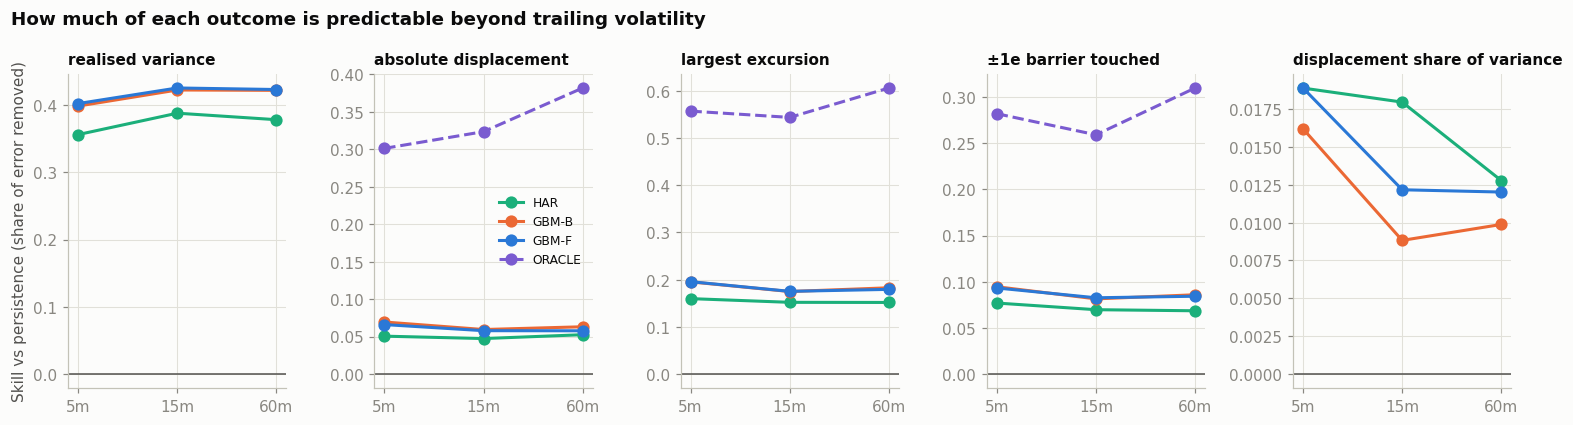

In [11]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(14, 3.9), sharey=False)
for ax, tg in zip(axes, TARGETS):
    for k_, k in enumerate(MODELS1):
        if f"skill {k}" not in SK or SK.loc[tg, f"skill {k}"].isna().all():
            continue
        v = SK.loc[tg, f"skill {k}"]
        ax.plot(range(len(HORIZONS)), v.values, marker="o", color=MODEL_COLORS[k], label=k, ls="--" if k == "ORACLE" else "-")
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(range(len(HORIZONS))); ax.set_xticklabels([f"{h}m" for h in HORIZONS]); ax.set_title(TARGET_NAMES[tg], fontsize=10)
axes[0].set_ylabel("Skill vs persistence (share of error removed)")
axes[1].legend(fontsize=8, loc="center right")
fig.suptitle("How much of each outcome is predictable beyond trailing volatility", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); plt.show()

**What is predictable, and how well.**

* **Volatility is the predictable quantity.** `GBM-B` removes about 40% of the persistence forecast's squared error on log realised variance (0.40 to 0.42 at all three horizons, intervals about ±0.02). The `HAR` linear baseline removes 36–39%, so the nonlinear baseline adds 3.5–4.4 points.
* **The other magnitude targets are predictable only partly, in a clear order:** largest excursion 0.17–0.20, barrier touch 0.08–0.09 (log-loss skill), absolute displacement 0.06–0.07. Trendiness (`eff`) is close to unpredictable: 0.01–0.02.
* **The order is consistent with measurement noise, as section 2.2 anticipated.** The `ORACLE` row is a diagnostic benchmark: a model given the realised future one-second RV reaches 0.54–0.61 for the excursion, 0.26–0.31 for the touch, and 0.30–0.38 for displacement. Even knowing realised volatility leaves most of the displacement unexplained, because a single return is one noisy draw. The forecasting models reach roughly a third of the benchmark for excursion and touch, and a fifth for displacement. *(Revised wording: this was first called a "ceiling". It is not a proven upper bound. A model can use path information that RV does not contain, as section 6.4 shows for the excursion, and one-second RV is itself a noisy measure of volatility.)*
* **Horizon matters little.** Skill is roughly flat from 5 to 60 minutes for every target.
* **Microstructure shows no consistent incremental benefit.** The `GBM-F` minus `GBM-B` gain is within ±0.006 skill points everywhere. There are **isolated small gains** with intervals above zero: `rv` at 5 minutes (+0.004 [+0.000, +0.007]) and `eff` at 5 and 15 minutes (+0.003). They do not recur at other horizons or targets, and their sign changes from month to month (section 6.5). *(Revised wording: first written as "adds nothing useful".)* It is significantly **negative** for displacement at 5 and 60 minutes and excursion at 60 minutes. The placebo gains (−0.007 to +0.003) show the size of changes that extra noise columns alone produce, and the real gains sit in that range.

### 6.2 What the skill means in practical units

Skill is abstract. The next table translates the best non-oracle forecast (`GBM-B` or `GBM-F`, whichever is better on that row) into the units a trader would use: the average realised outcome in the lowest and highest forecast decile, the ratio between them, and the rank correlation between forecast and outcome. For `rv`, it also gives the R² on raw log realised variance (the number usually quoted, which includes persistence) and the typical multiplicative error of the volatility forecast.

In [12]:
rows = []
for tg in TARGETS:
    for H in HORIZONS:
        y = Y1[(tg, H)]; m = TEST & np.isfinite(y)
        best = "GBM-F" if SK.loc[(tg, H), "skill GBM-F"] >= SK.loc[(tg, H), "skill GBM-B"] else "GBM-B"
        p = PRED1[(H, tg, best)]
        if tg == "rv":
            nat = 1e4 * np.sqrt(np.exp(y)) * E_SIG[ti] * np.sqrt(H) / np.sqrt(H)      # realised vol, bps per sqrt(minute)
            unit = "vol (bps/√min)"
        elif tg == "abs":
            nat, unit = y * E_BPS[H], "|r| (bps)"
        elif tg == "exc":
            nat, unit = np.exp(y) * E_BPS[H], "excursion (bps)"
        elif tg == "touch":
            nat, unit = 100 * y, "touch rate (%)"
        else:
            nat, unit = y, "r²/RV"
        q = pd.qcut(p[m], 10, labels=False, duplicates="drop")
        g = pd.Series(nat[m]).groupby(q).mean()
        r_ = {"target": tg, "H": H, "model": best, "unit": unit, "bottom decile": g.iloc[0], "top decile": g.iloc[-1], "top / bottom": g.iloc[-1] / g.iloc[0],
              "Spearman": stats.spearmanr(p[m], y[m])[0]}
        if tg == "rv":
            lraw = y + 2 * np.log(E_SIG[ti] * np.sqrt(H))
            praw = p + 2 * np.log(E_SIG[ti] * np.sqrt(H))
            r_["R² raw log RV"] = 1 - np.mean((lraw[m] - praw[m]) ** 2) / np.var(lraw[m])
            r_["vol error factor"] = np.exp(np.sqrt(np.mean((y[m] - p[m]) ** 2)) / 2)
            r_["vol error factor NAIVE"] = np.exp(np.sqrt(np.mean((y[m] - PRED1[(H, tg, "NAIVE")][m]) ** 2)) / 2)
        if tg == "touch":
            r_["AUC"] = auc(p[m], y[m]); r_["AUC HAR"] = auc(PRED1[(H, tg, "HAR")][m], y[m]); r_["AUC ORACLE"] = auc(PRED1[(H, tg, "ORACLE")][m], y[m])
            r_["ECE"] = ece(p[m], y[m]); r_["ECE NAIVE"] = abs(PRED1[(H, tg, "NAIVE")][m].mean() - y[m].mean())
        rows.append(r_)
PRAC = pd.DataFrame(rows).set_index(["target", "H"])
display(PRAC.round(3))

model             unit  bottom decile  top decile  top / bottom  Spearman  R² raw log RV  vol error factor  vol error factor NAIVE    AUC  AUC HAR  AUC ORACLE    ECE  ECE NAIVE
target H                                                                                                                                                                                   
rv     5   GBM-F   vol (bps/√min)          2.446       7.920         3.238     0.625          0.748             1.450                   1.617    NaN      NaN         NaN    NaN        NaN
       15  GBM-F   vol (bps/√min)          3.230       7.432         2.301     0.641          0.783             1.362                   1.503    NaN      NaN         NaN    NaN        NaN
       60  GBM-F   vol (bps/√min)          3.925       6.894         1.756     0.637          0.771             1.341                   1.472    NaN      NaN         NaN    NaN        NaN
abs    5   GBM-B        |r| (bps)          7.493      14.127         1.885     0.225            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       15  GBM-B        |r| (bps)         14.235      21.795         1.531     0.204            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       60  GBM-B        |r| (bps)         29.811      44.810         1.503     0.214            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
exc    5   GBM-F  excursion (bps)          7.912      23.745         3.001     0.416            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       15  GBM-F  excursion (bps)         20.156      38.198         1.895     0.394            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       60  GBM-B  excursion (bps)         47.136      72.965         1.548     0.405            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
touch  5   GBM-B   touch rate (%)         20.741      82.252         3.966     0.337            NaN               NaN                     NaN  0.695    0.680       0.835  0.011      0.003
       15  GBM-F   touch rate (%)         24.341      80.933         3.325     0.319            NaN               NaN                     NaN  0.684    0.673       0.824  0.014      0.004
       60  GBM-B   touch rate (%)         23.252      82.252         3.537     0.329            NaN               NaN                     NaN  0.690    0.673       0.852  0.016      0.001
eff    5   GBM-F            r²/RV          1.107       1.649         1.490     0.070            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       15  GBM-F            r²/RV          1.019       1.436         1.409     0.054            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN
       60  GBM-F            r²/RV          0.851       1.161         1.364     0.045            NaN               NaN                     NaN    NaN      NaN         NaN    NaN        NaN

**In practical terms.**

* **Volatility.** The forecast's typical multiplicative error in volatility is 1.34–1.45, against 1.47–1.62 for persistence. The realised volatility in the top forecast decile is 1.8 to 3.2 times that of the bottom decile. The R² on raw log RV is 0.75–0.78, close to the earlier notebook's 0.79–0.81. That number is high mostly because volatility persists; the skill against persistence (about 0.4) is the informative part.
* **Barrier touch.** Decisions in the bottom forecast decile touch ±1e 21–24% of the time; in the top decile, 81–82%. The AUC is 0.68–0.70. An AUC of 0.69 means that, if one decision that touched and one that did not are picked at random, the forecast ranks the touching one higher 69% of the time. It does **not** mean 69% of forecasts are correct. The linear `HAR` baseline already gets 0.67–0.68. The realised-RV diagnostic benchmark gets 0.82–0.85.
* **Displacement and excursion.** The top decile's average absolute move is 1.5–1.9 times the bottom decile's (for example 30 against 45 bps at 60 minutes), with a rank correlation of only 0.20–0.23. The largest excursion ranks better (about 0.40).
* **Trendiness** has a rank correlation of 0.05–0.07: real but negligible.

### 6.3 Calibration of the barrier-touch forecast

Reliability in deciles of the forecast, on all test decisions. A calibrated forecast lies on the diagonal.

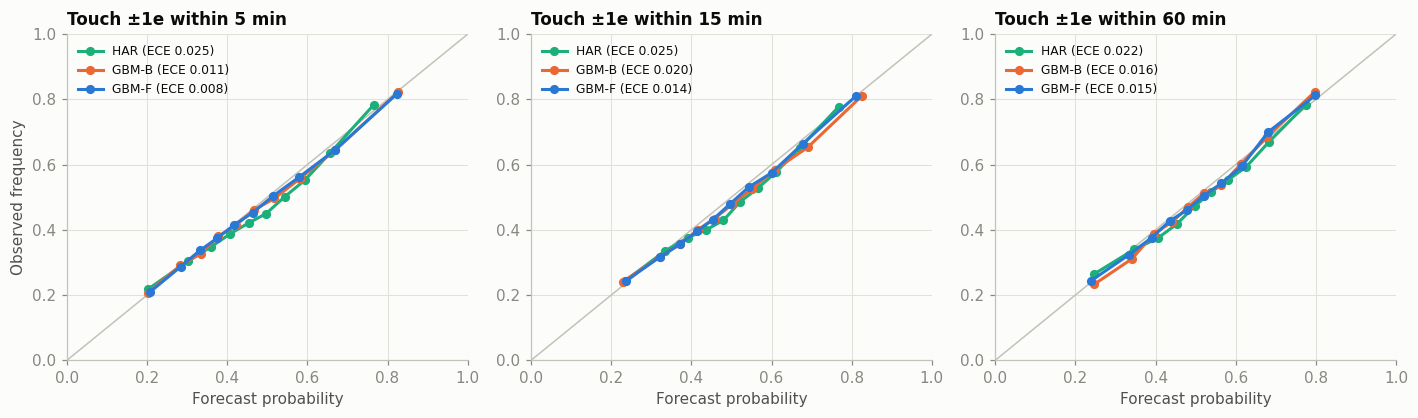

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, H in zip(axes, HORIZONS):
    y = Y1[("touch", H)]; m = TEST & np.isfinite(y)
    ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
    for k in ("HAR", "GBM-B", "GBM-F"):
        p = PRED1[(H, "touch", k)][m]
        q = pd.qcut(p, 10, labels=False, duplicates="drop")
        g = pd.DataFrame({"p": p, "y": y[m], "q": q}).groupby("q").mean()
        ax.plot(g["p"], g["y"], marker="o", ms=5, color=MODEL_COLORS[k], label=f"{k} (ECE {ece(p, y[m]):.3f})")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("Forecast probability"); ax.set_title(f"Touch ±1e within {H} min")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Observed frequency")
fig.tight_layout(); plt.show()

**Calibration.** All three models stay close to the diagonal from about 20% to 80%. The gradient-boosted models have an ECE of 0.008–0.020; the linear `HAR` is slightly worse (0.022–0.025), with a mild S-shape at 5 minutes. Persistence has an even smaller ECE (0.001–0.004) only because it predicts the same base rate for every decision; it is calibrated on average and useless for ranking.

### 6.4 Is magnitude predictable beyond volatility?

If displacement, excursion and touching are predictable **only because volatility is**, then a forecast built from the volatility forecast alone should match the direct model. For blocks 2–4, a one-dimensional monotone mapping from the out-of-sample `GBM-F` volatility forecast to each target is fitted on the earlier blocks' out-of-sample forecasts (walk-forward), then applied to the current block. The direct `GBM-F` model of the same target is scored on the same decisions.

In [14]:
def vol_implied(tg, H):
    out = np.full(N, np.nan); xv = PRED1[(H, "rv", "GBM-F")]; y = Y1[(tg, H)]
    for b in range(1, len(BLOCKS)):
        trm = TEST & (P["block"].to_numpy() < b) & np.isfinite(y) & np.isfinite(xv)
        te = SPLIT[b][1]
        obj = "binary" if tg == "touch" else "regression"
        prm = dict(LGB_PARAMS, objective=obj, num_leaves=7, min_data_in_leaf=500, monotone_constraints=[1] if tg != "eff" else [0], seed=SEED)
        mdl = lgb.train(prm, lgb.Dataset(xv[trm][:, None], y[trm], params=dict(max_bin=63, verbosity=-1)), 200)
        out[te] = mdl.predict(xv[te][:, None])
    return out
rows = []
for tg in ("abs", "exc", "touch", "eff"):
    for H in HORIZONS:
        PRED1[(H, tg, "VOL-IMPLIED")] = vol_implied(tg, H)
        y = Y1[(tg, H)]; m = TEST & (P["block"].to_numpy() >= 1) & np.isfinite(y)
        L0 = loss_of(tg, H, "NAIVE"); Lv, Lf = loss_of(tg, H, "VOL-IMPLIED"), loss_of(tg, H, "GBM-F")
        d = boot_ratio(Lv - Lf, L0, m)
        rows.append({"target": tg, "H": H, "skill vol-implied": 1 - Lv[m].sum() / L0[m].sum(), "skill direct GBM-F": 1 - Lf[m].sum() / L0[m].sum(),
                     "direct − vol-implied": (Lv[m] - Lf[m]).sum() / L0[m].sum(), "lo": ci(d)[0], "hi": ci(d)[1],
                     "skill ORACLE": (1 - loss_of(tg, H, "ORACLE")[m].sum() / L0[m].sum()) if (H, tg, "ORACLE") in PRED1 else np.nan})
VI = pd.DataFrame(rows).set_index(["target", "H"])
print("Blocks 2–4 (February to October 2026):"); display(VI.round(4))

Blocks 2–4 (February to October 2026):


skill vol-implied  skill direct GBM-F  direct − vol-implied      lo      hi  skill ORACLE
target H                                                                                            
abs    5              0.0675              0.0661               -0.0014 -0.0061  0.0032        0.3003
       15             0.0556              0.0586                0.0029 -0.0012  0.0071        0.3282
       60             0.0714              0.0593               -0.0120 -0.0208 -0.0037        0.4052
exc    5              0.1912              0.2010                0.0098  0.0018  0.0182        0.5579
       15             0.1704              0.1771                0.0066  0.0027  0.0109        0.5381
       60             0.1870              0.1921                0.0051  0.0004  0.0103        0.6033
touch  5              0.0955              0.0940               -0.0015 -0.0041  0.0013        0.2800
       15             0.0818              0.0842                0.0024  0.0001  0.0047        0.2529
       60             0.0928              0.0956                0.0028 -0.0006  0.0064        0.3114
eff    5              0.0143              0.0180                0.0038 -0.0012  0.0090           NaN
       15             0.0104              0.0130                0.0027 -0.0042  0.0096           NaN
       60             0.0062              0.0127                0.0065 -0.0006  0.0133           NaN

**Magnitude is predictable almost entirely through volatility.**

* **Touch:** a forecast built only from the volatility forecast reaches 0.082–0.096 skill; the direct model adds 0.002–0.003 at most. Attainment of a barrier set in units of trailing volatility is, in practice, a volatility forecast.
* **Displacement:** the volatility-only route is as good as the direct model, and better at 60 minutes (by 0.012). The direct model overfits noise in a single return.
* **Excursion:** the direct model adds a small, consistent 0.005–0.010, with intervals above zero. Some information about the path's reach is not captured by total variance, for example the clustering of large one-second moves.
* **Trendiness:** nothing to speak of in either route.

### 6.5 Stability across months and market conditions

Skill of `GBM-B` against persistence, and the microstructure gain of `GBM-F` over `GBM-B`, by month, for the three targets that matter most for barriers. Then the same by market condition: trailing 24-hour volatility tercile (cut points from the training era), US session (13:00–21:00 UTC) or not, weekend, and book provenance (`book_state` 9 is a certified rebuild, 0 is anchored to snapshots).

2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09  2026-10
rv    15 skill B     0.434    0.413    0.422    0.504    0.424    0.391    0.401    0.473    0.422    0.362    0.412    0.438
         gain F−B    0.003    0.009   -0.011    0.004    0.005    0.016    0.015    0.005   -0.000   -0.001   -0.005    0.009
      60 skill B     0.358    0.370    0.415    0.453    0.412    0.392    0.446    0.428    0.465    0.370    0.481    0.467
         gain F−B   -0.018    0.015   -0.011    0.011   -0.013    0.018    0.009    0.012   -0.010    0.005   -0.009    0.006
exc   15 skill B     0.134    0.167    0.198    0.171    0.126    0.159    0.193    0.159    0.189    0.170    0.210    0.197
         gain F−B   -0.004    0.007   -0.003    0.002   -0.003   -0.005    0.002    0.002    0.012    0.000   -0.004   -0.004
      60 skill B     0.098    0.135    0.208    0.171    0.143    0.167    0.224    0.165    0.217    0.181    0.247    0.214
         gain F−B   -0.025    0.000   -0.003    0.002   -0.006   -0.004    0.006   -0.004    0.002   -0.000   -0.007   -0.004
touch 15 skill B     0.067    0.065    0.088    0.080    0.051    0.086    0.083    0.067    0.090    0.086    0.110    0.102
         gain F−B    0.000    0.014    0.000    0.000    0.000   -0.005   -0.001    0.001    0.004   -0.001    0.000   -0.003
      60 skill B     0.042    0.039    0.082    0.075    0.077    0.088    0.111    0.082    0.113    0.084    0.129    0.111
         gain F−B   -0.011    0.006    0.001   -0.003   -0.005   -0.008    0.001    0.000    0.000    0.003   -0.002   -0.003

Months with positive microstructure gain: {'rv 15m': '8/12', 'rv 60m': '7/12', 'exc 15m': '6/12', 'exc 60m': '4/12', 'touch 15m': '8/12', 'touch 60m': '6/12'}


,test decisions,rv 15m skill B,rv 15m gain F−B,rv 60m skill B,rv 60m gain F−B,touch 15m skill B,touch 15m gain F−B,touch 60m skill B,touch 60m gain F−B
condition,,,,,,,,,
low vol,9574,0.311,0.001,0.334,-0.004,0.077,-0.001,0.074,0.001
mid vol,10100,0.421,0.007,0.437,0.006,0.088,0.003,0.100,-0.001
high vol,28099,0.478,0.002,0.454,0.002,0.081,0.001,0.085,-0.003
US session,15388,0.544,-0.003,0.556,-0.003,0.124,0.000,0.142,-0.004
other hours,32385,0.345,0.007,0.323,0.004,0.061,0.002,0.059,-0.001
weekday,33545,0.494,0.002,0.483,0.001,0.089,0.000,0.099,-0.002
weekend,14228,0.290,0.005,0.288,0.002,0.064,0.003,0.056,-0.001
book rebuilt (9),21351,0.433,0.002,0.403,-0.002,0.070,0.003,0.064,-0.003
book anchored (0),26422,0.414,0.004,0.437,0.004,0.091,-0.000,0.104,-0.001


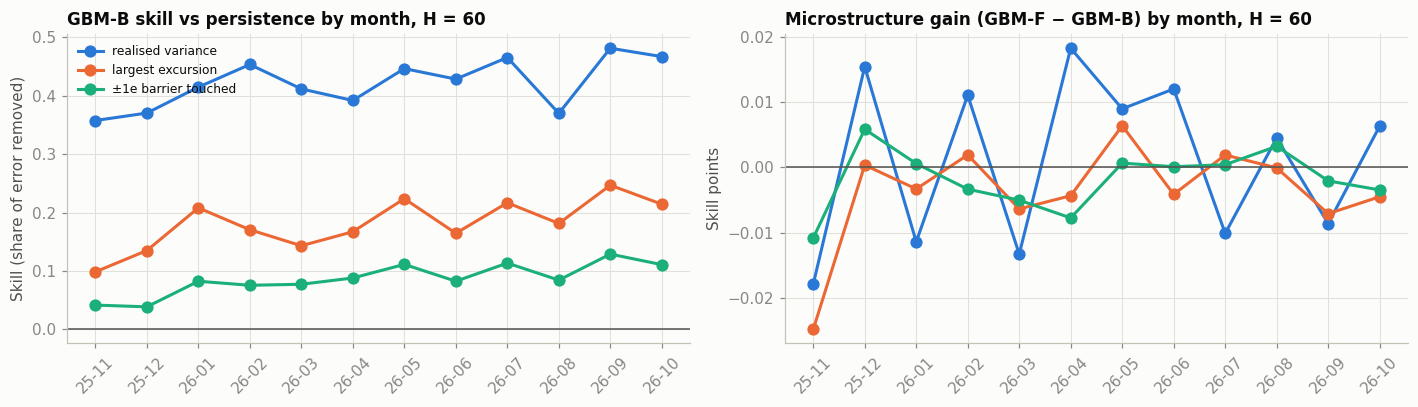

In [15]:
def skill_in(tg, H, model, m):
    L0 = loss_of(tg, H, "NAIVE"); L = loss_of(tg, H, model); mm = m & np.isfinite(L) & np.isfinite(L0)
    return 1 - L[mm].sum() / L0[mm].sum()
def gain_in(tg, H, m):
    L0 = loss_of(tg, H, "NAIVE"); mm = m & np.isfinite(Y1[(tg, H)])
    return (loss_of(tg, H, "GBM-B")[mm] - loss_of(tg, H, "GBM-F")[mm]).sum() / L0[mm].sum()
months = sorted(P.loc[TEST, "month"].unique())
MON = {}
for tg in ("rv", "exc", "touch"):
    for H in (15, 60):
        MON[(tg, H, "skill B")] = [skill_in(tg, H, "GBM-B", TEST & (P["month"].to_numpy() == mo)) for mo in months]
        MON[(tg, H, "gain F−B")] = [gain_in(tg, H, TEST & (P["month"].to_numpy() == mo)) for mo in months]
MON = pd.DataFrame(MON, index=months)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(MON.T)
print("Months with positive microstructure gain:", {f"{k[0]} {k[1]}m": f"{(MON[k] > 0).sum()}/{len(months)}" for k in MON if k[2] == "gain F−B"})

vq = np.quantile(SIGW[1440][ti][pre], [1 / 3, 2 / 3])
s24 = SIGW[1440][ti]
COND = {"low vol": s24 < vq[0], "mid vol": (s24 >= vq[0]) & (s24 < vq[1]), "high vol": s24 >= vq[1],
        "US session": (P["hour"].to_numpy() >= 13) & (P["hour"].to_numpy() < 21), "other hours": ~((P["hour"].to_numpy() >= 13) & (P["hour"].to_numpy() < 21)),
        "weekday": F["is_weekend"] == 0, "weekend": F["is_weekend"] == 1, "book rebuilt (9)": bs == 9, "book anchored (0)": bs == 0}
rows = []
for cn, cm in COND.items():
    r_ = {"condition": cn, "test decisions": int((TEST & cm).sum())}
    for tg in ("rv", "touch"):
        for H in (15, 60):
            r_[f"{tg} {H}m skill B"] = skill_in(tg, H, "GBM-B", TEST & cm); r_[f"{tg} {H}m gain F−B"] = gain_in(tg, H, TEST & cm)
    rows.append(r_)
CONDT = pd.DataFrame(rows).set_index("condition")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(CONDT)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (tg, col) in (("rv", C["blue"]), ("exc", C["orange"]), ("touch", C["aqua"])):
    axes[0].plot(range(len(months)), MON[(tg, 60, "skill B")], marker="o", color=col, label=TARGET_NAMES[tg])
    axes[1].plot(range(len(months)), MON[(tg, 60, "gain F−B")], marker="o", color=col, label=TARGET_NAMES[tg])
for ax in axes:
    ax.set_xticks(range(len(months))); ax.set_xticklabels([m[2:] for m in months], rotation=45); ax.axhline(0, color=INK2, lw=1)
axes[0].set_title("GBM-B skill vs persistence by month, H = 60"); axes[1].set_title("Microstructure gain (GBM-F − GBM-B) by month, H = 60")
axes[0].legend(fontsize=8); axes[0].set_ylabel("Skill (share of error removed)"); axes[1].set_ylabel("Skill points")
fig.tight_layout(); plt.show()

**Stability.**

* **By month, volatility skill never fails.** `GBM-B` skill on `rv` ranges from 0.36 to 0.50 across all 12 test months at both horizons, the excursion from 0.10 to 0.25, and the touch from 0.04 to 0.13. The first months are a little weaker at 60 minutes, when training covered only three months.
* **The microstructure gain changes sign from month to month**, positive in 4 to 8 of 12 months depending on the target. That is what a zero effect looks like.
* **By condition**, skill is much higher in the US session (0.54–0.56 on `rv` against 0.32–0.35 outside it) and on weekdays, and lower on weekends and in low-volatility regimes. Volatility is more forecastable when the daily cycle and activity bursts dominate. Book provenance makes no difference, and the microstructure gain stays within ±0.007 in every condition.

## 7. Question 2, part 1: what mirrored barriers can and cannot measure

Before fitting anything, it helps to know what the two configurations would look like if price were a driftless random walk, and how much a drift would change them.

**Symmetry.** Configuration B is configuration A reflected through `P0`. If returns are symmetric (no drift and equal upside and downside volatility), then exactly:

* `P_A(hit) = P_B(hit)`, so the difference is zero;
* `P_A(upper first) = P_B(lower first)` and `P_A(lower first) = P_B(upper first)`.

So **any** systematic difference between the two configurations measures an asymmetry: a drift, or a difference between upside and downside volatility or jump risk. Volatility itself, which dominates each forecast, cancels in the difference. That is why the difference is the natural candidate for direction, and also why it will be small: it isolates the part of the forecasts that the earlier notebooks found hardest to predict.

**Overlap.** The two "either barrier" events are not exclusive and not nested. The table below lists the joint outcomes in terms of the four first-touch times `τ(+1e)`, `τ(+2e)`, `τ(−1e)`, `τ(−2e)`.

| Path | Config A (+1e / −2e) | Config B (+2e / −1e) |
|---|---|---|
| Touches +1e, never −1e | upper (if `τ(+1e)` comes first) | upper if it reaches +2e, else neither |
| Touches −1e, never +1e | lower if it reaches −2e, else neither | lower |
| Touches +1e and then −1e | upper | lower |
| Touches −1e and then +1e | lower if −2e comes before +1e, else upper | lower |
| Touches neither | neither | neither |

A path that rises to +1e and falls back to −1e "hits" in both configurations. So `P_A(hit) − P_B(hit)` mixes paths that went up with paths that went both ways. It is not `P(up) − P(down)`.

**The closed form.** For driftless Brownian motion between a barrier `u` above and `l` below the start, with `s = σ_f √H` in units of `e`, the probability of leaving through the top before expiry is a standard series (the same one validated in the delayed-entry pilot). Writing `ρ = σ_f / σ̂`, the ratio of future volatility to the trailing estimate, everything depends on `ρ` alone.

In [16]:
def geo3(u, l, s, n_terms=100):
    # Driftless BM from 0, barriers at +u and -l, s = sigma*sqrt(T) (all in units of e). Returns P(upper first), P(lower first), P(neither).
    u, l, s = np.broadcast_arrays(np.asarray(u, float), np.asarray(l, float), np.asarray(s, float))
    W = u + l
    n = np.arange(1, n_terms + 1)[:, None]
    dec = np.exp(-(n ** 2) * np.pi ** 2 * s.ravel() ** 2 / (2 * W.ravel() ** 2))
    def top(x):
        x, Wr = x.ravel(), W.ravel()
        return np.clip(x / Wr + (2 * (-1.0) ** n / (n * np.pi) * np.sin(n * np.pi * x / Wr) * dec).sum(0), 0, 1)
    pu, pl = top(l), top(u)
    pn = np.clip(1 - pu - pl, 0, 1)
    return np.column_stack([pu, pl, pn]).reshape(*u.shape, 3)

@njit
def sim_cfg(mu, rho, nsteps, npaths, seed):
    # Brownian motion with drift mu (in e per horizon) and volatility rho (in e per sqrt(horizon)). For A (+1/-2) and B (+2/-1):
    # [P(upper first), P(lower first), P(neither), E(exit return)], plus E(r_H) and P(r_H > 0).
    np.random.seed(seed)
    dt = 1.0 / nsteps; sd = rho * np.sqrt(dt); dr = mu * dt
    out = np.zeros((2, 4)); er = 0.0; up = 0.0
    for p in range(npaths):
        x = 0.0; tU1 = -1; tU2 = -1; tL1 = -1; tL2 = -1
        for k in range(nsteps):
            x += dr + sd * np.random.standard_normal()
            if tU1 < 0 and x >= 1.0: tU1 = k
            if tU2 < 0 and x >= 2.0: tU2 = k
            if tL1 < 0 and x <= -1.0: tL1 = k
            if tL2 < 0 and x <= -2.0: tL2 = k
        er += x
        if x > 0: up += 1.0
        for c in range(2):
            tu = tU1 if c == 0 else tU2; tl = tL2 if c == 0 else tL1
            u = 1.0 if c == 0 else 2.0; l = 2.0 if c == 0 else 1.0
            if tu >= 0 and (tl < 0 or tu < tl):
                out[c, 0] += 1; out[c, 3] += u
            elif tl >= 0:
                out[c, 1] += 1; out[c, 3] -= l
            else:
                out[c, 2] += 1; out[c, 3] += x
    return out / npaths, er / npaths, up / npaths

# 1. Check the closed form against simulation, no drift.
for rho in (0.7, 1.0, 1.5):
    mc, _, _ = sim_cfg(0.0, rho, 2000, 40_000, 11)
    an = np.vstack([geo3(1, 2, rho), geo3(2, 1, rho)])
    assert np.abs(mc[:, :3] - an).max() < 0.02, (rho, mc, an)
print("Closed form matches a 40,000-path simulation within 0.02 at rho = 0.7, 1.0, 1.5 (the residual is the discrete-step bias of the simulation).")

# 2. Symmetric geometry as a function of rho.
GEO = pd.DataFrame([{"ρ = future / trailing vol": r, "P_A(hit) = P_B(hit)": 1 - geo3(1, 2, r)[2], "P_A(upper) = P_B(lower)": geo3(1, 2, r)[0],
                     "P_A(lower) = P_B(upper)": geo3(1, 2, r)[1], "P(touch ±1e)": None} for r in (0.5, 0.75, 1.0, 1.25, 1.5, 2.0)]).set_index("ρ = future / trailing vol")
GEO["P(touch ±1e)"] = [1 - geo3(1, 1, r)[2] for r in GEO.index]
display(GEO.round(3))

# 3. How much drift does a given difference imply?
t_ = time.time()
MUS = [-0.3, -0.2, -0.1, -0.05, 0.0, 0.05, 0.1, 0.2, 0.3]
rows = []
for rho in (0.75, 1.0, 1.5):
    for mu in MUS:
        o, er, upp = sim_cfg(mu, rho, 1000, 40_000, 100 + int(rho * 100))      # common random numbers across mu for each rho
        rows.append({"ρ": rho, "drift μ (e per horizon)": mu, "P_A(hit)": 1 - o[0, 2], "P_B(hit)": 1 - o[1, 2], "D = P_A − P_B": o[1, 2] - o[0, 2],
                     "P_A(upper) − P_B(lower)": o[0, 0] - o[1, 1], "E[exit A]": o[0, 3], "E[exit B]": o[1, 3], "P(r_H > 0)": upp})
DRIFT = pd.DataFrame(rows).set_index(["ρ", "drift μ (e per horizon)"])
display(DRIFT.round(4))
K_SLOPE = {rho: (DRIFT.loc[(rho, 0.1), "D = P_A − P_B"] - DRIFT.loc[(rho, -0.1), "D = P_A − P_B"]) / 0.2 for rho in (0.75, 1.0, 1.5)}
print(f"Simulation {time.time() - t_:.0f} s. Slope dD/dμ near zero drift: " + ", ".join(f"ρ = {k}: {v:.3f}" for k, v in K_SLOPE.items()))
print(f"At H = 60 with the median e of {np.median(E_BPS[60][pre]):.1f} bps, a drift of 1 bp over the hour is μ = {1 / np.median(E_BPS[60][pre]):.3f} e and moves D by about {K_SLOPE[1.0] / np.median(E_BPS[60][pre]):.4f}.")

Closed form matches a 40,000-path simulation within 0.02 at rho = 0.7, 1.0, 1.5 (the residual is the discrete-step bias of the simulation).


,P_A(hit) = P_B(hit),P_A(upper) = P_B(lower),P_A(lower) = P_B(upper),P(touch ±1e)
ρ = future / trailing vol,,,,
0.50,0.046,0.046,0.000,0.091
0.75,0.190,0.182,0.008,0.365
1.00,0.363,0.317,0.045,0.629
1.25,0.532,0.424,0.108,0.815
1.50,0.679,0.504,0.175,0.921
2.00,0.877,0.605,0.272,0.991


P_A(hit)  P_B(hit)  D = P_A − P_B  P_A(upper) − P_B(lower)  E[exit A]  E[exit B]  P(r_H > 0)
ρ    drift μ (e per horizon)                                                                                              
0.75 -0.30                      0.1163    0.2892        -0.1729                  -0.1902    -0.2870    -0.2625      0.3449
     -0.20                      0.1337    0.2483        -0.1146                  -0.1254    -0.1900    -0.1764      0.3955
     -0.10                      0.1562    0.2126        -0.0564                  -0.0615    -0.0943    -0.0878      0.4475
     -0.05                      0.1689    0.1954        -0.0265                  -0.0291    -0.0470    -0.0421      0.4733
      0.00                      0.1820    0.1804         0.0016                   0.0009    -0.0009     0.0040      0.4983
      0.05                      0.1980    0.1669         0.0311                   0.0334     0.0454     0.0506      0.5263
      0.10                      0.2154    0.1536         0.0617                   0.0663     0.0908     0.0978      0.5528
      0.20                      0.2517    0.1319         0.1198                   0.1294     0.1792     0.1933      0.6071
      0.30                      0.2903    0.1152         0.1751                   0.1921     0.2639     0.2907      0.6560
1.00 -0.30                      0.3037    0.4277        -0.1239                  -0.1809    -0.2669    -0.2321      0.3809
     -0.20                      0.3164    0.4004        -0.0839                  -0.1221    -0.1797    -0.1565      0.4192
     -0.10                      0.3331    0.3752        -0.0420                  -0.0616    -0.0936    -0.0765      0.4584
     -0.05                      0.3426    0.3626        -0.0200                  -0.0307    -0.0515    -0.0355      0.4785
      0.00                      0.3531    0.3514         0.0017                  -0.0001    -0.0092     0.0055      0.4987
      0.05                      0.3647    0.3413         0.0234                   0.0300     0.0324     0.0472      0.5178
      0.10                      0.3767    0.3324         0.0443                   0.0604     0.0731     0.0898      0.5377
      0.20                      0.4027    0.3151         0.0876                   0.1220     0.1526     0.1759      0.5764
      0.30                      0.4315    0.3016         0.1300                   0.1836     0.2297     0.2637      0.6162
1.50 -0.30                      0.6449    0.6889        -0.0440                  -0.1388    -0.2137    -0.1780      0.4181
     -0.20                      0.6484    0.6789        -0.0304                  -0.0952    -0.1474    -0.1192      0.4442
     -0.10                      0.6533    0.6704        -0.0171                  -0.0503    -0.0813    -0.0593      0.4703
     -0.05                      0.6560    0.6668        -0.0108                  -0.0290    -0.0485    -0.0292      0.4832
      0.00                      0.6592    0.6630        -0.0038                  -0.0060    -0.0167     0.0037      0.4965
      0.05                      0.6635    0.6600         0.0035                   0.0166     0.0161     0.0348      0.5098
      0.10                      0.6665    0.6566         0.0099                   0.0394     0.0478     0.0675      0.5235
      0.20                      0.6766    0.6519         0.0246                   0.0842     0.1091     0.1315      0.5496
      0.30                      0.6856    0.6464         0.0392                   0.1290     0.1669     0.1985      0.5762

Simulation 85 s. Slope dD/dμ near zero drift: ρ = 0.75: 0.590, ρ = 1.0: 0.432, ρ = 1.5: 0.135
At H = 60 with the median e of 29.9 bps, a drift of 1 bp over the hour is μ = 0.033 e and moves D by about 0.0144.


**What the mirrored pair can measure.**

* **Under a driftless walk the two configurations are exact mirror images.** At `ρ = 1`, both reach a barrier 36.3% of the time; the near barrier is reached first 31.7% of the time and the far one 4.5%. Their difference is zero at every `ρ`, so it removes volatility, which drives most of each forecast.
* **A drift does move the difference.** At `ρ = 1`, `D` changes by 0.43 per unit of drift measured in `e` per horizon. Near saturation (`ρ = 1.5`) both configurations are almost always hit, and the slope falls to 0.14.
* **The realistic size is tiny.** At 60 minutes, with `e` around 30 bps, a drift of **1 bp per hour** corresponds to `D ≈ 0.014`. The strongest known direction signal in this market, queue imbalance, is worth about 0.7 bps and pays out within 30 seconds. So a correctly sized difference forecast should vary by about ±0.01, and anything much larger has to be mostly noise.
* **Barrier-exit returns pass on most of a drift**: `E[exit]` is about 0.65 to 0.9 times μ, depending on `ρ`, for both configurations. If a drift were predictable, the barrier trades would capture most of it. The difficulty lies in predicting the drift, not in the payoff.
* **The difference is not a direction probability.** `P(r_H > 0)` changes by about 0.02 per 0.05 e of drift, while `D` changes by about the same amount. Their ratio depends on `ρ`. Treating `D` as "the probability of going up minus 0.5" would be wrong by a factor that changes with volatility.

## 8. Question 2, part 2: the configurations in data

### 8.1 Labels and unconditional symmetry

Three-class labels per configuration, the frictionless barrier-exit return `X` in units of `e`, and the stop-slipped long and short payoffs used in question 3. Then the observed frequencies on training-era and test decisions, against the driftless geometry at `ρ = 1`.

In [17]:
LAB, XF, XL, XS = {}, {}, {}, {}
for H in CFG_H:
    o = OUT[H]; e = E_SIG[ti] * np.sqrt(H); p0 = o["p0"]
    for c, (um, lm) in CONFIGS.items():
        tU, tL = o["tu"][:, um - 1], o["td"][:, lm - 1]
        lab = np.full(N, 2)
        lab[(tU >= 0) & ((tL < 0) | (tU < tL))] = 0
        lab[(tL >= 0) & ((tU < 0) | (tL < tU))] = 1
        lab[(tU >= 0) & (tU == tL)] = 3
        r_e = o["rH"] / e
        LAB[(H, c)] = lab
        XF[(H, c)] = np.select([lab == 0, lab == 1, lab == 2], [um, -lm, r_e], np.nan)
        stop_long = np.log(o["pdn"][:, lm - 1] / p0) / e                        # worst price in the second the lower barrier is touched
        stop_short = -np.log(o["pu"][:, um - 1] / p0) / e
        XL[(H, c)] = np.select([lab == 0, lab == 1, lab == 2, lab == 3], [um, stop_long, r_e, stop_long], np.nan)
        XS[(H, c)] = np.select([lab == 0, lab == 1, lab == 2, lab == 3], [stop_short, lm, -r_e, stop_short], np.nan)
UP = {H: np.where(OUT[H]["rH"] > 0, 1.0, np.where(OUT[H]["rH"] < 0, 0.0, np.nan)) for H in CFG_H}
RE = {H: OUT[H]["rH"] / (E_SIG[ti] * np.sqrt(H)) for H in CFG_H}
SYMF = {H: np.where((OUT[H]["tu"][:, 0] >= 0) & ((OUT[H]["td"][:, 0] < 0) | (OUT[H]["tu"][:, 0] < OUT[H]["td"][:, 0])), 1.0,
                    np.where((OUT[H]["td"][:, 0] >= 0) & ((OUT[H]["tu"][:, 0] < 0) | (OUT[H]["td"][:, 0] < OUT[H]["tu"][:, 0])), 0.0, np.nan)) for H in CFG_H}

g1 = geo3(1, 2, 1.0)
rows = []
for H in CFG_H:
    for per, msk in (("training era", pre), ("test", TEST)):
        la, lb = LAB[(H, "A")][msk], LAB[(H, "B")][msk]
        rows.append({"H": H, "period": per, "decisions": int(msk.sum()), "ambiguous (A, B)": f"{(la == 3).sum()}, {(lb == 3).sum()}",
                     "P_A(hit)": np.mean(la != 2), "P_B(hit)": np.mean(lb != 2), "P_A(upper)": np.mean(la == 0), "P_B(lower)": np.mean(lb == 1),
                     "P_A(lower)": np.mean(la == 1), "P_B(upper)": np.mean(lb == 0), "both hit": np.mean((la != 2) & (lb != 2)),
                     "mean X_A (e)": np.nanmean(XF[(H, "A")][msk]), "mean X_B (e)": np.nanmean(XF[(H, "B")][msk]), "mean r_H (bps)": 1e4 * np.nanmean(OUT[H]["rH"][msk]),
                     "share up": np.nanmean(UP[H][msk])})
    rows.append({"H": H, "period": "geometry, ρ = 1", "P_A(hit)": 1 - g1[2], "P_B(hit)": 1 - g1[2], "P_A(upper)": g1[0], "P_B(lower)": g1[0], "P_A(lower)": g1[1], "P_B(upper)": g1[1]})
SYM = pd.DataFrame(rows).set_index(["H", "period"])
display(SYM.round(3))
for H in CFG_H:
    m = TEST
    d = (LAB[(H, "A")] != 2).astype(float) - (LAB[(H, "B")] != 2).astype(float)
    bd = boot_ratio(d, np.ones(N), m)
    print(f"H = {H}: realised P_A(hit) − P_B(hit) on test = {d[m].mean():+.4f} [{ci(bd)[0]:+.4f}, {ci(bd)[1]:+.4f}]")

decisions ambiguous (A, B)  P_A(hit)  P_B(hit)  P_A(upper)  P_B(lower)  P_A(lower)  P_B(upper)  both hit  mean X_A (e)  mean X_B (e)  mean r_H (bps)  share up
H  period                                                                                                                                                                         
15 training era       13684.0             0, 0     0.303     0.306       0.247       0.254       0.056       0.052     0.124        -0.020        -0.001          -0.094     0.494
   test               47773.0             0, 0     0.306     0.302       0.249       0.247       0.057       0.055     0.128        -0.007         0.006          -0.106     0.498
   geometry, ρ = 1        NaN              NaN     0.363     0.363       0.317       0.317       0.045       0.045       NaN           NaN           NaN             NaN       NaN
60 training era       13684.0             0, 0     0.318     0.326       0.257       0.267       0.062       0.058     0.141        -0.007        -0.008           0.090     0.501
   test               47773.0             0, 0     0.322     0.326       0.255       0.264       0.067       0.062     0.150        -0.012        -0.003          -0.396     0.500
   geometry, ρ = 1        NaN              NaN     0.363     0.363       0.317       0.317       0.045       0.045       NaN           NaN           NaN             NaN       NaN

H = 15: realised P_A(hit) − P_B(hit) on test = +0.0037 [-0.0021, +0.0098]
H = 60: realised P_A(hit) − P_B(hit) on test = -0.0041 [-0.0132, +0.0052]


**The data are almost exactly symmetric.**

* **Unconditionally, A and B behave like mirror images.** On test decisions, `P_A(hit)` and `P_B(hit)` differ by +0.004 [−0.002, +0.010] at 15 minutes and −0.004 [−0.013, +0.005] at 60. `P_A(upper)` and `P_B(lower)` differ by at most 0.009. Mean barrier-exit returns are within ±0.02 e of zero. There is no stable upside/downside asymmetry for a model to learn on average.
* **Hit rates are below the `ρ = 1` geometry** (30–33% against 36%), for the reason given in section 4.4: the typical future hour is calmer than the trailing root mean square.
* **The overlap is large.** 12–15% of decisions hit a barrier in both configurations, so over 40% of A's hits are also B's hits. These are the paths that touch both +1e and −1e.
* **No second-level ambiguity** occurs: no single second touched both barriers of a configuration.

### 8.2 Fitting the configuration models

For each horizon and block: binary "either barrier" models for A and B on the `B` and `F` feature sets, three-class outcome models for A and B on `F`, a direct direction model (`r_H > 0`) on `B` and `F`, a direct regression of `r_H / e` (clipped at ±4) on `F`, and placebo refits of the `F` attainment and direction models with microstructure columns permuted (the same permutation for A and B, so the placebo difference is a fair null).

The geometric yardstick `G-ρ` uses the question-1 `GBM-F` volatility forecast: `ρ̂ = c · exp(forecast / 2)`, with one constant `c` per block chosen on training decisions to match attainment. It gives identical attainment probabilities for A and B by construction.

In [18]:
def q2_task(task):
    H, b, tname, fset, rep = task
    tr, te = SPLIT[b]
    c = cols_for(fset, H)
    if tname.startswith("hit"):
        y = (LAB[(H, tname[3])] != 2).astype(float); obj, ncls = "binary", None
    elif tname.startswith("mc"):
        y = LAB[(H, tname[2])].astype(float); y[y == 3] = np.nan; obj, ncls = "multiclass", 3
    elif tname == "dir":
        y = UP[H]; obj, ncls = "binary", None
    else:
        y = np.clip(RE[H], -4, 4); obj, ncls = "regression", None
    tr = tr[np.isfinite(y[tr])]
    Xtr = XM[tr][:, c]
    if rep >= 0:
        Xtr = placebo_X(Xtr, MICRO_IDX[H], rep, b, H)
    pr, rounds, ptr = fit_lgb(obj, Xtr, y[tr], XM[te][:, c], num_class=ncls, return_train=True)
    return dict(task=task, pred=pr, pred_tr=ptr, tr=tr, rounds=rounds)

Q2_TASKS = []
for H in sorted(CFG_H, reverse=True):
    for b in range(len(BLOCKS)):
        for tname, fset in [("mcA", "F"), ("mcB", "F"), ("hitA", "B"), ("hitA", "F"), ("hitB", "B"), ("hitB", "F"), ("dir", "B"), ("dir", "F"), ("reg", "F")]:
            Q2_TASKS.append((H, b, tname, fset, -1))
        for rep in range(N_PLACEBO):
            for tname in ("hitA", "hitB", "dir"):
                Q2_TASKS.append((H, b, tname, "F", rep))
t_ = time.time()
Q2_RES = cached("q2_fits", lambda: pmap(q2_task, Q2_TASKS))
PRED2, TRP2 = {}, {}
for r in Q2_RES:
    H, b, tname, fset, rep = r["task"]
    key = (H, f"{tname}_{fset}" + ("" if rep < 0 else f"_p{rep}"))
    shape = (N, 3) if tname.startswith("mc") else (N,)
    PRED2.setdefault(key, np.full(shape, np.nan))[SPLIT[b][1]] = r["pred"]
    TRP2[(key, b)] = (r["tr"], r["pred_tr"])
print(f"{len(Q2_TASKS)} question-2 fits in {(time.time() - t_) / 60:.1f} min.")

# G-rho: closed-form attainment with the question-1 volatility forecast, one calibration constant per block.
CGRID = np.linspace(0.6, 2.2, 81)
GRHO, CBEST = {}, {}
for H in CFG_H:
    out3 = {c: np.full((N, 3), np.nan) for c in CONFIGS}
    for b in range(len(BLOCKS)):
        trv, ptr = RV_TRAIN[(H, b)]
        ya = (LAB[(H, "A")][trv] != 2).astype(float); yb = (LAB[(H, "B")][trv] != 2).astype(float)
        s_tr = np.exp(ptr / 2)
        ll = []
        for cc in CGRID:
            ph = 1 - geo3(1, 2, cc * s_tr)[..., 2]
            ll.append(logloss(ph, ya).mean() + logloss(ph, yb).mean())
        cb = CGRID[int(np.argmin(ll))]; CBEST[(H, b)] = cb
        te = SPLIT[b][1]; s_te = cb * np.exp(PRED1[(H, "rv", "GBM-F")][te] / 2)
        for c, (um, lm) in CONFIGS.items():
            out3[c][te] = geo3(um, lm, s_te)
    for c in CONFIGS:
        GRHO[(H, c)] = out3[c]
print("Calibration constant c by horizon and block:", {f"H{k[0]} b{k[1]}": round(v, 3) for k, v in CBEST.items()})

120 question-2 fits in 2.3 min.


Calibration constant c by horizon and block: {'H15 b0': np.float64(1.28), 'H15 b1': np.float64(1.24), 'H15 b2': np.float64(1.2), 'H15 b3': np.float64(1.18), 'H60 b0': np.float64(1.24), 'H60 b1': np.float64(1.2), 'H60 b2': np.float64(1.18), 'H60 b3': np.float64(1.16)}


### 8.3 How well is attainment of each configuration predicted?

Log loss and Brier skill against a constant training base rate, AUC, and calibration. `G-ρ` is geometry plus the volatility forecast. Then the key structural fact: how strongly the two configurations' forecasts move together.

log loss  skill vs constant      lo      hi  Brier skill     AUC     ECE
H  config model                                                                              
15 A      constant     0.6156             0.0000  0.0000  0.0000       0.0000  0.4987  0.0021
          G-ρ          0.5780             0.0612  0.0529  0.0692       0.0776  0.6687  0.0340
          HIT-B        0.5732             0.0690  0.0635  0.0753       0.0862  0.6690  0.0078
          HIT-F        0.5742             0.0673  0.0618  0.0733       0.0843  0.6671  0.0071
          3-class F    0.5743             0.0672  0.0619  0.0733       0.0840  0.6675  0.0079
   B      constant     0.6125             0.0000  0.0000  0.0000       0.0000  0.4995  0.0024
          G-ρ          0.5812             0.0511  0.0431  0.0600       0.0649  0.6632  0.0364
          HIT-B        0.5750             0.0612  0.0554  0.0670       0.0760  0.6623  0.0129
          HIT-F        0.5751             0.0611  0.0552  0.0670       0.0757  0.6628  0.0096
          3-class F    0.5747             0.0617  0.0559  0.0673       0.0767  0.6629  0.0074
60 A      constant     0.6286             0.0000  0.0000  0.0000       0.0000  0.5052  0.0038
          G-ρ          0.5851             0.0692  0.0591  0.0801       0.0873  0.6803  0.0190
          HIT-B        0.5849             0.0695  0.0614  0.0774       0.0869  0.6730  0.0063
          HIT-F        0.5865             0.0670  0.0588  0.0751       0.0839  0.6707  0.0050
          3-class F    0.5857             0.0681  0.0600  0.0763       0.0851  0.6719  0.0079
   B      constant     0.6316             0.0000  0.0000  0.0000       0.0000  0.4972  0.0064
          G-ρ          0.5897             0.0663  0.0556  0.0767       0.0852  0.6736  0.0226
          HIT-B        0.5858             0.0725  0.0637  0.0806       0.0917  0.6749  0.0086
          HIT-F        0.5859             0.0723  0.0649  0.0797       0.0917  0.6762  0.0107
          3-class F    0.5865             0.0714  0.0638  0.0789       0.0905  0.6754  0.0105

corr(P_A, P_B)  sd of mean (P_A+P_B)/2  sd of D = P_A − P_B  mean D  share of D > 0  realised mean P_A − P_B
H  features                                                                                                              
15 B                 0.8689                  0.1328               0.0704  0.0001          0.4972                   0.0037
   F                 0.8616                  0.1302               0.0710  0.0005          0.5006                   0.0037
60 B                 0.8608                  0.1297               0.0711 -0.0050          0.4679                  -0.0041
   F                 0.8662                  0.1287               0.0690 -0.0027          0.4764                  -0.0041

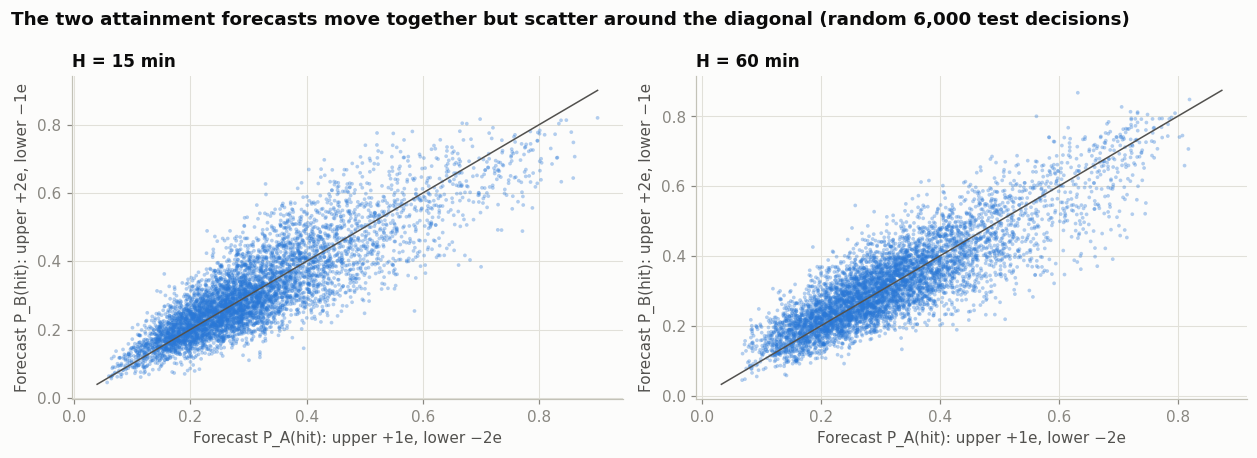

In [19]:
def brier(p, y):
    return (p - y) ** 2
rows = []
for H in CFG_H:
    for c in CONFIGS:
        y = (LAB[(H, c)] != 2).astype(float); m = TEST.copy()
        base = np.full(N, np.nan)
        for b in range(len(BLOCKS)):
            base[SPLIT[b][1]] = y[SPLIT[b][0]].mean()
        cands = {"constant": base, "G-ρ": 1 - GRHO[(H, c)][:, 2], "HIT-B": PRED2[(H, f"hit{c}_B")], "HIT-F": PRED2[(H, f"hit{c}_F")],
                 "3-class F": 1 - PRED2[(H, f"mc{c}_F")][:, 2]}
        L0 = logloss(base, y)
        for k, p in cands.items():
            L = logloss(p, y); d = boot_ratio(L0 - L, L0, m)
            rows.append({"H": H, "config": c, "model": k, "log loss": L[m].mean(), "skill vs constant": 1 - L[m].sum() / L0[m].sum(), "lo": ci(d)[0], "hi": ci(d)[1],
                         "Brier skill": 1 - brier(p, y)[m].sum() / brier(base, y)[m].sum(), "AUC": auc(p[m], y[m]), "ECE": ece(p[m], y[m])})
ATT = pd.DataFrame(rows).set_index(["H", "config", "model"])
display(ATT.round(4))
rows = []
for H in CFG_H:
    for fs in ("B", "F"):
        pa, pb = PRED2[(H, f"hitA_{fs}")][TEST], PRED2[(H, f"hitB_{fs}")][TEST]
        D = pa - pb; S = (pa + pb) / 2
        rows.append({"H": H, "features": fs, "corr(P_A, P_B)": np.corrcoef(pa, pb)[0, 1], "sd of mean (P_A+P_B)/2": S.std(), "sd of D = P_A − P_B": D.std(),
                     "mean D": D.mean(), "share of D > 0": np.mean(D > 0), "realised mean P_A − P_B": np.mean((LAB[(H, "A")] != 2)[TEST]) - np.mean((LAB[(H, "B")] != 2)[TEST])})
JOINT = pd.DataFrame(rows).set_index(["H", "features"])
display(JOINT.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
rng_p = np.random.default_rng(3)
for ax, H in zip(axes, CFG_H):
    pa, pb = PRED2[(H, "hitA_F")][TEST], PRED2[(H, "hitB_F")][TEST]
    k = rng_p.choice(pa.size, min(6000, pa.size), replace=False)
    ax.scatter(pa[k], pb[k], s=6, alpha=.35, color=C["blue"], edgecolor="none")
    lo_, hi_ = min(pa.min(), pb.min()), max(pa.max(), pb.max())
    ax.plot([lo_, hi_], [lo_, hi_], color=INK2, lw=1)
    ax.set_xlabel("Forecast P_A(hit): upper +1e, lower −2e"); ax.set_ylabel("Forecast P_B(hit): upper +2e, lower −1e")
    ax.set_title(f"H = {H} min")
fig.suptitle("The two attainment forecasts move together but scatter around the diagonal (random 6,000 test decisions)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); plt.show()

**Attainment is predicted well, and it is mostly geometry plus volatility.**

* **Each configuration's attainment is predictable:** about 6–7% of the constant's log loss is removed, with AUC 0.66–0.68 and ECE under 0.013.
* **Geometry plus the volatility forecast (`G-ρ`) gets most of the way.** It reaches 0.051–0.069 skill against 0.061–0.073 for the learned models, and at 60 minutes for configuration A the two are equal. The learned models win mostly on calibration (ECE 0.005–0.013 against 0.019–0.036), because a Brownian model does not get the shape of real price paths exactly right. Microstructure (`HIT-F` against `HIT-B`) adds nothing.
* **The two forecasts are strongly but not perfectly correlated** (0.86–0.87). Their difference `D` has a standard deviation of about 0.07, half that of their average. By section 7, a `D` of that size would correspond to drifts of about ±5 bps per hour, far more than any known signal. Section 8.7 measures how much of it is real.
* **The models lean bearish at 60 minutes** (47.6% of `D` positive), in line with the training-era drift, while the realised test difference is −0.004 with an interval around zero.

### 8.4 Three-class outcomes: does anything beat geometry plus volatility?

Log loss of the three-class forecast (upper first, lower first, neither) for each configuration, against the training class frequencies and against `G-ρ`. Then the part of the three-class forecast that is **directional**: among decisions where a barrier was reached, how well does the model rank "upper first"?

In [20]:
rows = []
for H in CFG_H:
    for c in CONFIGS:
        lab = LAB[(H, c)]; m = TEST & (lab != 3)
        base = np.full((N, 3), np.nan)
        for b in range(len(BLOCKS)):
            tr = SPLIT[b][0]; base[SPLIT[b][1]] = np.bincount(lab[tr][lab[tr] != 3], minlength=3) / np.sum(lab[tr] != 3)
        def ll3(Pm):
            Pm = np.clip(Pm, 1e-6, 1); Pm = Pm / Pm.sum(1, keepdims=True)
            return -np.log(Pm[np.arange(N), np.where(lab == 3, 0, lab)])
        L0 = ll3(base)
        hitm = m & (lab != 2)
        for k, Pm in (("class frequencies", base), ("G-ρ", np.clip(GRHO[(H, c)], 1e-6, 1)), ("3-class F", PRED2[(H, f"mc{c}_F")])):
            L = ll3(Pm); d = boot_ratio(L0 - L, L0, m)
            pdir = Pm[:, 0] / (Pm[:, 0] + Pm[:, 1])
            rows.append({"H": H, "config": c, "model": k, "log loss": L[m].mean(), "skill vs frequencies": 1 - L[m].sum() / L0[m].sum(), "lo": ci(d)[0], "hi": ci(d)[1],
                         "AUC upper-first | hit": auc(pdir[hitm], (lab[hitm] == 0).astype(float))})
MC3 = pd.DataFrame(rows).set_index(["H", "config", "model"])
display(MC3.round(4))

log loss  skill vs frequencies      lo      hi  AUC upper-first | hit
H  config model                                                                                   
15 A      class frequencies    0.7624                0.0000  0.0000  0.0000                 0.4945
          G-ρ                  0.7315                0.0404  0.0347  0.0465                 0.5866
          3-class F            0.7190                0.0569  0.0524  0.0618                 0.5924
   B      class frequencies    0.7558                0.0000  0.0000  0.0000                 0.5152
          G-ρ                  0.7324                0.0310  0.0242  0.0382                 0.5757
          3-class F            0.7157                0.0531  0.0482  0.0581                 0.6007
60 A      class frequencies    0.7939                0.0000  0.0000  0.0000                 0.4907
          G-ρ                  0.7597                0.0430  0.0325  0.0534                 0.5777
          3-class F            0.7500                0.0553  0.0480  0.0620                 0.5757
   B      class frequencies    0.7902                0.0000  0.0000  0.0000                 0.5018
          G-ρ                  0.7534                0.0465  0.0385  0.0553                 0.5872
          3-class F            0.7439                0.0586  0.0518  0.0650                 0.5900

**Three-class outcomes repeat the delayed-entry lesson.** The learned three-class models beat `G-ρ` by 1–2 skill points on every configuration and horizon. Given that a barrier is hit, "upper first" has an AUC of 0.58–0.60, but `G-ρ` alone, which has no directional input at all, gets 0.58–0.59. That apparent directional skill comes from volatility. When volatility is higher, the far barrier becomes reachable, so in A "lower first" becomes more likely relative to "upper first". The learned models add at most 0.025 AUC over geometry on this ranking.

### 8.5 Do the paired forecasts predict direction?

Each score is evaluated against four directional outcomes on all test decisions:

* **IC with `r_H/e`**: the correlation between the score (converted to normal scores of its rank) and the signed return in units of `e` (clipped at ±4), computed without demeaning within days. 95% interval from the day-block bootstrap.
* **AUC up**: ranking of "price higher at expiry".
* **bps per sd**: the average signed return, in bps, per one standard deviation of the score.
* **IC with `X_A`, `X_B`**: the same correlation with each configuration's barrier-exit return, which is the long payoff of that configuration, i.e. the relative attractiveness of long against short.
* **AUC sym-first**: among decisions that touch ±1e, ranking of "+1e first".

`Stage-2` exists only for blocks 2–4, so every score is also shown on blocks 2–4 for a fair comparison. The two `placebo` rows refit the `F` models with the microstructure columns permuted, so whatever direction they keep comes from the price, volume and calendar features.

In [21]:
def normal_scores(x, m):
    out = np.full(N, np.nan); r = stats.rankdata(x[m]); out[m] = stats.norm.ppf((r - .5) / r.size); return out

def ic_parts(score, target, m):
    mm = m & np.isfinite(score) & np.isfinite(target)
    s = normal_scores(score, mm); y = np.clip(target, -4, 4)
    y = y / np.sqrt(np.mean(y[mm] ** 2))
    return s, y, mm

def ic_with_ci(score, target, m, boot=True):
    s, y, mm = ic_parts(score, target, m)
    ic = np.sum(s[mm] * y[mm]) / np.sqrt(np.sum(s[mm] ** 2) * np.sum(y[mm] ** 2))
    if not boot:
        return ic, np.nan, np.nan
    a, b_, c_ = dsum(s * y, mm), dsum(s ** 2, mm), dsum(y ** 2, mm)
    bs_ = (BW @ a) / np.sqrt((BW @ b_) * (BW @ c_))
    return (ic, *ci(bs_))

# Build the scores.
SCORES = {}
for H in CFG_H:
    SC = {}
    for fs in ("F", "B"):
        pa, pb = PRED2[(H, f"hitA_{fs}")], PRED2[(H, f"hitB_{fs}")]
        SC[f"D_hit ({fs})"] = pa - pb
    pa, pb = np.clip(PRED2[(H, "hitA_F")], 1e-4, 1 - 1e-4), np.clip(PRED2[(H, "hitB_F")], 1e-4, 1 - 1e-4)
    SC["D_logit (F)"] = logit(pa) - logit(pb)
    MA, MB = PRED2[(H, "mcA_F")], PRED2[(H, "mcB_F")]
    SC["S3 (F)"] = (1 * MA[:, 0] - 2 * MA[:, 1]) + (2 * MB[:, 0] - 1 * MB[:, 1])
    # Stage-2: walk-forward logistic regression on the six configuration probabilities, trained on earlier test blocks.
    Z = np.column_stack([logit(np.clip(v, 1e-4, 1 - 1e-4)) for v in (pa, pb, MA[:, 0], MA[:, 1], MB[:, 0], MB[:, 1])])
    st2 = np.full(N, np.nan)
    for b in range(1, len(BLOCKS)):
        trm = TEST & (P["block"].to_numpy() < b) & np.isfinite(UP[H]); te = SPLIT[b][1]
        mu_, sd_ = Z[trm].mean(0), Z[trm].std(0) + 1e-9
        st2[te] = LogisticRegression(C=1.0, max_iter=2000).fit((Z[trm] - mu_) / sd_, UP[H][trm]).predict_proba((Z[te] - mu_) / sd_)[:, 1]
    SC["Stage-2 (F)"] = st2
    SC["Direct up (F)"], SC["Direct up (B)"], SC["Direct reg (F)"] = PRED2[(H, "dir_F")], PRED2[(H, "dir_B")], PRED2[(H, "reg_F")]
    SC["qi_1 (raw)"] = F["qi_1"]
    for rep in range(N_PLACEBO):
        SC[f"D_hit placebo {rep}"] = PRED2[(H, f"hitA_F_p{rep}")] - PRED2[(H, f"hitB_F_p{rep}")]
        SC[f"Direct up placebo {rep}"] = PRED2[(H, f"dir_F_p{rep}")]
    SCORES[H] = SC

LATER = TEST & (P["block"].to_numpy() >= 1)
rows = []
for H in CFG_H:
    for k, s in SCORES[H].items():
        for per, m in (("all blocks", TEST), ("blocks 2–4", LATER)):
            if per == "all blocks" and k.startswith("Stage-2"):
                continue
            mm = m & np.isfinite(s)
            ic, lo, hi = ic_with_ci(s, RE[H], mm)
            sn, _, _ = ic_parts(s, RE[H], mm)
            rbps = 1e4 * OUT[H]["rH"]
            slope = np.sum(sn[mm] * rbps[mm]) / np.sum(sn[mm] ** 2)
            hm = mm & np.isfinite(SYMF[H])
            rows.append({"H": H, "score": k, "period": per, "IC r_H/e": ic, "lo": lo, "hi": hi, "AUC up": auc(s[mm], UP[H][mm]), "bps per sd": slope,
                         "IC X_A": ic_with_ci(s, XF[(H, "A")], mm, boot=False)[0], "IC X_B": ic_with_ci(s, XF[(H, "B")], mm, boot=False)[0],
                         "AUC sym-first": auc(s[hm], SYMF[H][hm])})
DIRT = pd.DataFrame(rows).set_index(["H", "period", "score"]).sort_index(level=[0, 1], sort_remaining=False)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(DIRT)

IC r_H/e      lo     hi  AUC up  bps per sd  IC X_A  IC X_B  AUC sym-first
H  period     score                                                                                          
15 all blocks D_hit (F)              0.0309  0.0205 0.0431  0.5260      0.4851  0.0244  0.0304         0.5113
              D_hit (B)              0.0236  0.0129 0.0358  0.5229      0.3569  0.0158  0.0239         0.5041
              D_logit (F)            0.0310  0.0205 0.0429  0.5259      0.5090  0.0247  0.0304         0.5111
              S3 (F)                 0.0219  0.0099 0.0342  0.5010      0.3663  0.0195  0.0267         0.5224
              Direct up (F)          0.0283  0.0176 0.0392  0.5327      0.4653  0.0195  0.0229         0.4950
              Direct up (B)          0.0272  0.0167 0.0380  0.5312      0.4605  0.0131  0.0189         0.4891
              Direct reg (F)         0.0282  0.0182 0.0381  0.5203      0.4768  0.0184  0.0240         0.5045
              qi_1 (raw)             0.0190  0.0105 0.0285  0.5099      0.3714  0.0252  0.0259         0.5259
              D_hit placebo 0        0.0218  0.0120 0.0324  0.5203      0.3553  0.0135  0.0212         0.5012
              Direct up placebo 0    0.0247  0.0148 0.0350  0.5301      0.4223  0.0117  0.0156         0.4863
              D_hit placebo 1        0.0235  0.0125 0.0351  0.5228      0.3665  0.0151  0.0223         0.5017
              Direct up placebo 1    0.0271  0.0171 0.0374  0.5290      0.4531  0.0126  0.0190         0.4890
   blocks 2–4 D_hit (F)              0.0327  0.0191 0.0466  0.5276      0.5365  0.0274  0.0304         0.5100
              D_hit (B)              0.0219  0.0074 0.0363  0.5237      0.3334  0.0156  0.0200         0.5013
              D_logit (F)            0.0334  0.0200 0.0472  0.5277      0.5689  0.0282  0.0314         0.5101
              S3 (F)                 0.0187  0.0049 0.0328  0.4997      0.3125  0.0191  0.0244         0.5229
              Stage-2 (F)            0.0236  0.0118 0.0368  0.5281      0.3572  0.0167  0.0213         0.4973
              Direct up (F)          0.0256  0.0131 0.0389  0.5329      0.4354  0.0176  0.0192         0.4895
              Direct up (B)          0.0241  0.0115 0.0377  0.5318      0.4419  0.0120  0.0151         0.4845
              Direct reg (F)         0.0187  0.0050 0.0314  0.5160      0.2849  0.0105  0.0110         0.4948
              qi_1 (raw)             0.0195  0.0084 0.0316  0.5103      0.3686  0.0247  0.0235         0.5241
              D_hit placebo 0        0.0203  0.0091 0.0323  0.5208      0.3287  0.0106  0.0164         0.4962
              Direct up placebo 0    0.0224  0.0107 0.0350  0.5301      0.4137  0.0104  0.0128         0.4812
              D_hit placebo 1        0.0227  0.0100 0.0372  0.5236      0.3587  0.0162  0.0192         0.5004
              Direct up placebo 1    0.0259  0.0132 0.0391  0.5294      0.4646  0.0129  0.0171         0.4864
60 all blocks D_hit (F)              0.0202  0.0023 0.0362  0.5190      0.9829  0.0218  0.0212         0.5092
              D_hit (B)              0.0151 -0.0027 0.0318  0.5180      0.7260  0.0159  0.0183         0.5052
              D_logit (F)            0.0180  0.0012 0.0326  0.5180      0.9086  0.0199  0.0198         0.5092
              S3 (F)                 0.0222  0.0001 0.0428  0.4972      0.9477  0.0200  0.0277         0.5286
              Direct up (F)          0.0184 -0.0008 0.0394  0.5261      0.5943  0.0155  0.0108         0.4861
              Direct up (B)          0.0167 -0.0020 0.0352  0.5239      0.7786  0.0117  0.0091         0.4856
              Direct reg (F)         0.0120 -0.0068 0.0322  0.5106      0.6561  0.0048  0.0089         0.5011
              qi_1 (raw)             0.0119  0.0040 0.0203  0.5081      0.5190  0.0137  0.0135         0.5134
              D_hit placebo 0        0.0189  0.0000 0.0360  0.5160      0.8368  0.0154  0.0217         0.5046
              Direct up placebo 0    0.0183 -0.0012 0.0377  0.5238      0.6

**The pair does carry a little direction. It is the same small signal as a direct model, and it is mostly short-term reversal.**

* **`D_hit` predicts the sign and size of the next move, weakly but measurably.** The IC with `r_H/e` is 0.031 [0.021, 0.043] at 15 minutes and 0.020 [0.002, 0.036] at 60. The AUC for "price up" is 0.52–0.53. In money, one standard deviation of `D_hit` is worth about 0.5 bps at 15 minutes and 1.0 bp at 60, around 3% of `e`.
* **A model trained directly on direction does no better.** `Direct up (F)` has IC 0.028 and 0.018. On blocks 2–4, `D_hit` is slightly ahead at 60 minutes (0.021 against 0.009), but the intervals overlap heavily. Taking the logit difference (`D_logit`) or learning a combination of all six probabilities (`Stage-2`) adds nothing.
* **Most of the signal is not microstructure.** Refitting with the microstructure columns permuted keeps an IC of 0.022–0.024 at 15 minutes and 0.018–0.019 at 60. `D_hit (B)`, with no microstructure at all, has 0.024 and 0.015. Raw queue imbalance alone gives 0.019 and 0.012.
* **"Relative attractiveness of long against short"** in each configuration (the IC with `X_A` and `X_B`) is the same signal at the same size, 0.02–0.03. There is no configuration in which the pair reveals more.
* **`S3`**, the three-class expected-value sum, has a similar IC but an AUC for "up" of only 0.50. It ranks the larger moves in the right direction, but not the sign of small ones.

### 8.6 Null distributions, stability, and what drives the difference

1. **Circular-shift placebo.** Each score is shifted against the outcomes by 7 to 56 days within the test period. This keeps the score's own autocorrelation and the outcome's, and destroys only their alignment. A real signal should sit in the upper tail.
2. **Per-block IC** of the main scores.
3. **Score deciles**: mean signed return in bps by decile of `D_hit (F)`, `Direct up (F)` and `qi_1`.
4. **What `D_hit` encodes**: its rank correlation with each input feature.
5. `POST-HOC` **Overlap with the direct model**: the IC of `D_hit` after removing its linear dependence on `Direct up`, and the reverse. Added after seeing that the two scores had similar ICs.

IC  null mean  null 95th pct  null max  percentile of real
H  score                                                                                           
15 D_hit (F)                         0.0309     0.0011         0.0118    0.0128               100.0
   D_logit (F)                       0.0310     0.0009         0.0111    0.0126               100.0
   S3 (F)                            0.0219    -0.0001         0.0100    0.0146               100.0
   Direct up (F)                     0.0283     0.0009         0.0096    0.0153               100.0
   Direct reg (F)                    0.0282    -0.0001         0.0071    0.0089               100.0
   qi_1 (raw)                        0.0190     0.0002         0.0079    0.0117               100.0
   D_hit placebo 0 (permuted micro)  0.0218        NaN            NaN       NaN                 NaN
   D_hit placebo 1 (permuted micro)  0.0235        NaN            NaN       NaN                 NaN
60 D_hit (F)                         0.0202     0.0000         0.0122    0.0149               100.0
   D_logit (F)                       0.0180    -0.0003         0.0111    0.0179               100.0
   S3 (F)                            0.0222    -0.0009         0.0171    0.0217               100.0
   Direct up (F)                     0.0184     0.0000         0.0120    0.0184               100.0
   Direct reg (F)                    0.0120    -0.0002         0.0151    0.0160                88.0
   qi_1 (raw)                        0.0119     0.0007         0.0068    0.0115               100.0
   D_hit placebo 0 (permuted micro)  0.0189        NaN            NaN       NaN                 NaN
   D_hit placebo 1 (permuted micro)  0.0181        NaN            NaN       NaN                 NaN

Nov–Jan  Feb–Apr  May–Jul  Aug–Oct
H  score                                            
15 D_hit (F)       0.0243   0.0253   0.0193   0.0562
   S3 (F)          0.0250   0.0092   0.0167   0.0267
   Direct up (F)   0.0407   0.0301   0.0140   0.0347
   qi_1 (raw)      0.0181   0.0211   0.0036   0.0337
60 D_hit (F)       0.0154   0.0124   0.0322   0.0233
   S3 (F)          0.0254   0.0346   0.0266  -0.0035
   Direct up (F)   0.0500   0.0096   0.0039   0.0121
   qi_1 (raw)      0.0046   0.0215   0.0014   0.0218

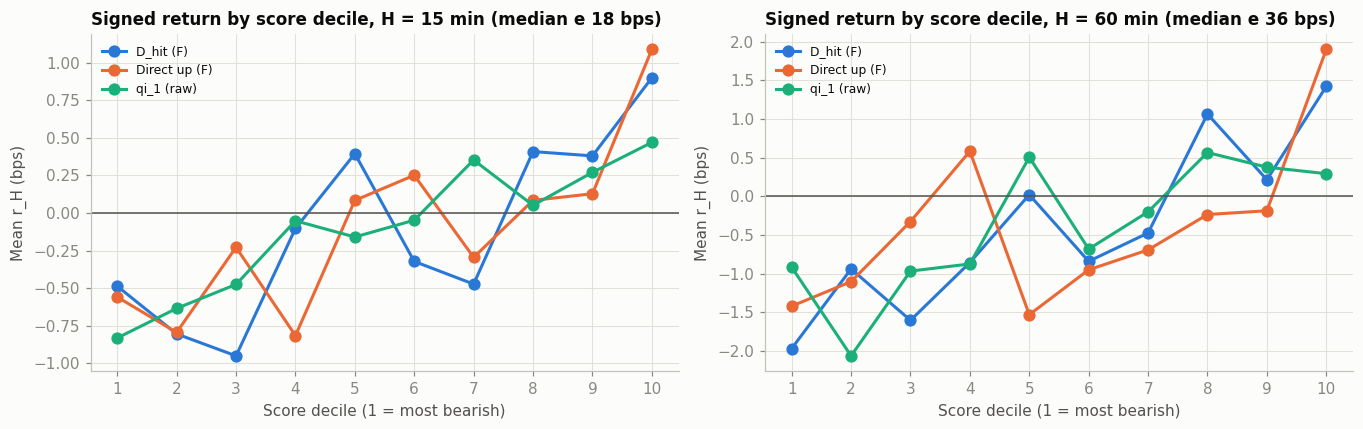

POST-HOC: does one score carry direction beyond another?


corr of scores  IC alone  IC of residual      lo      hi
H  score         controlling for                                                          
15 D_hit (F)     Direct up (F)            0.4632    0.0309          0.0201  0.0095  0.0318
   Direct up (F) D_hit (F)                0.4632    0.0283          0.0158  0.0056  0.0256
   D_hit (F)     qi_1 (raw)               0.1860    0.0309          0.0278  0.0176  0.0400
60 D_hit (F)     Direct up (F)            0.3643    0.0202          0.0144 -0.0022  0.0294
   Direct up (F) D_hit (F)                0.3643    0.0184          0.0118 -0.0070  0.0316
   D_hit (F)     qi_1 (raw)               0.0204    0.0202          0.0199  0.0021  0.0360

Rank correlation of each score with its strongest input features (test decisions):


,"D_hit, H = 15","Direct up, H = 15","D_hit, H = 60","Direct up, H = 60"
z_ret_15,-0.318,-0.640,-0.175,-0.327
z_ret_60,-0.242,-0.550,-0.170,-0.353
close_loc_15m,-0.283,-0.545,-0.171,-0.295
liq_imb_15m,-0.204,-0.513,-0.121,-0.290
z_rb_15m,-0.266,-0.505,-0.147,-0.260
tfi_15m,-0.210,-0.479,-0.118,-0.234
large_flow_15m,-0.197,-0.450,-0.110,-0.230
z_dd_15m,-0.251,-0.439,-0.158,-0.255
z_ret_1440,-0.030,-0.265,-0.086,-0.421
z_ret_240,-0.195,-0.416,-0.120,-0.348


In [22]:
order = np.argsort(TN)
def shifted_ic(s, H, k_days):
    # Shift the score along the sorted test decisions by about k days (144 decisions per day), wrapping inside the test period.
    idx = np.flatnonzero(TEST[order]); rows_ = order[idx]
    sh = np.full(N, np.nan); sh[rows_] = np.roll(s[rows_], 144 * k_days)
    return ic_with_ci(sh, RE[H], TEST, boot=False)[0]
MAIN = ["D_hit (F)", "D_logit (F)", "S3 (F)", "Direct up (F)", "Direct reg (F)", "qi_1 (raw)"]
rows = []
for H in CFG_H:
    for k in MAIN:
        s = SCORES[H][k]; real = ic_with_ci(s, RE[H], TEST, boot=False)[0]
        null = np.array([shifted_ic(s, H, kd) for kd in range(7, 7 + N_SHIFTS)])
        rows.append({"H": H, "score": k, "IC": real, "null mean": null.mean(), "null 95th pct": np.quantile(null, .95), "null max": null.max(), "percentile of real": np.mean(null < real) * 100})
    for rep in range(N_PLACEBO):
        rows.append({"H": H, "score": f"D_hit placebo {rep} (permuted micro)", "IC": ic_with_ci(SCORES[H][f"D_hit placebo {rep}"], RE[H], TEST, boot=False)[0]})
NULLT = pd.DataFrame(rows).set_index(["H", "score"])
display(NULLT.round(4))

rows = []
for H in CFG_H:
    for k in ("D_hit (F)", "S3 (F)", "Direct up (F)", "qi_1 (raw)"):
        r_ = {"H": H, "score": k}
        for b in range(len(BLOCKS)):
            r_[BLOCK_LABELS[b]] = ic_with_ci(SCORES[H][k], RE[H], TEST & (P["block"].to_numpy() == b), boot=False)[0]
        rows.append(r_)
BLK = pd.DataFrame(rows).set_index(["H", "score"]); display(BLK.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
for ax, H in zip(axes, CFG_H):
    for k, col in (("D_hit (F)", C["blue"]), ("Direct up (F)", C["orange"]), ("qi_1 (raw)", C["aqua"])):
        s = SCORES[H][k]; m = TEST & np.isfinite(s)
        q = pd.qcut(stats.rankdata(s[m]), 10, labels=False)
        g = pd.Series(1e4 * OUT[H]["rH"][m]).groupby(q).mean()
        ax.plot(g.index + 1, g.values, marker="o", color=col, label=k)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(1, 11)); ax.set_xlabel("Score decile (1 = most bearish)"); ax.set_ylabel("Mean r_H (bps)")
    ax.set_title(f"Signed return by score decile, H = {H} min (median e {np.median(E_BPS[H][TEST]):.0f} bps)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

rows = {}
for H in CFG_H:
    s = SCORES[H]["D_hit (F)"]; m = TEST & np.isfinite(s)
    rows[f"D_hit, H = {H}"] = {c: stats.spearmanr(s[m], XM[m, FPOS[c]], nan_policy="omit")[0] for c in FEATS}
    s = SCORES[H]["Direct up (F)"]
    rows[f"Direct up, H = {H}"] = {c: stats.spearmanr(s[m], XM[m, FPOS[c]], nan_policy="omit")[0] for c in FEATS}
DRV = pd.DataFrame(rows)
rows2 = []
for H in CFG_H:
    for a_, b_ in (("D_hit (F)", "Direct up (F)"), ("Direct up (F)", "D_hit (F)"), ("D_hit (F)", "qi_1 (raw)")):
        m = TEST & np.isfinite(SCORES[H][a_]) & np.isfinite(SCORES[H][b_])
        sa, sb = normal_scores(SCORES[H][a_], m), normal_scores(SCORES[H][b_], m)
        resid = sa - (np.sum(sa[m] * sb[m]) / np.sum(sb[m] ** 2)) * sb
        rows2.append({"H": H, "score": a_, "controlling for": b_, "corr of scores": np.corrcoef(sa[m], sb[m])[0, 1],
                      "IC alone": ic_with_ci(sa, RE[H], m, boot=False)[0], **dict(zip(["IC of residual", "lo", "hi"], ic_with_ci(resid, RE[H], m)))})
PARTIAL = pd.DataFrame(rows2).set_index(["H", "score", "controlling for"])
print("POST-HOC: does one score carry direction beyond another?"); display(PARTIAL.round(4))
top = DRV.abs().max(axis=1).sort_values(ascending=False).index[:12]
print("Rank correlation of each score with its strongest input features (test decisions):"); display(DRV.loc[top].round(3))

**The signal is real, stable, and tiny.**

* **It is not an artefact of persistence.** Every main score's IC lies above all 50 circular-shift placebos (null maxima 0.009–0.022), except the direct regression at 60 minutes.
* **It holds in every block.** `D_hit` has a positive IC in all four quarters at both horizons (0.012 to 0.056). So does the direct model.
* **What it encodes:** `D_hit` correlates negatively with the past 15-minute and 1-hour returns (−0.32 and −0.24 at 15 minutes), the 15-minute close location, rebound and drawdown, 15-minute trade-flow imbalance and liquidation imbalance, and positively with deep-book imbalance (`qi_25bps`). It is a **short-term reversal** signal: after a rise, the lower barrier becomes slightly "easier". The direct model uses the same features about twice as strongly (−0.64 on the past 15-minute return).
* **The deciles are noisy but rise overall.** For `D_hit`, the mean return goes from about −0.5 to −1 bp in the lowest deciles to +0.9 bp in the highest at 15 minutes, and from about −2 to +1.4 bps at 60 minutes, with several reversals between neighbouring deciles.
* `POST-HOC` **The two scores are only partly the same signal.** `D_hit` and `Direct up` correlate 0.46 at 15 minutes and 0.36 at 60. After removing `Direct up`, `D_hit` keeps an IC of 0.020 [0.010, 0.032] at 15 minutes and 0.014 [−0.002, 0.029] at 60. The reverse is about the same size. This suggests the barrier pair may be a second, partly independent noisy estimate of the same small reversal-and-imbalance effect. A positive residual association is a reason to **test** a combined model, not evidence that one would predict better; section 14 runs that test. Removing `qi_1` barely changes `D_hit`'s IC, so its content is not mainly queue imbalance. *(Revised wording.)*

### 8.7 Taking the difference at face value: implied drift

Section 7 gives the drift that a difference `D` would imply under Brownian motion: `μ ≈ (D − D_median) / k`, with `k` the slope `dD/dμ` at `ρ = 1`. If the forecasts' asymmetry were a correctly sized drift forecast, regressing the realised `r_H/e` on the implied `μ` would give a slope of 1. A slope of zero means the asymmetry is noise.

In [23]:
rows = []
for H in CFG_H:
    s = SCORES[H]["D_hit (F)"]
    med = np.full(N, np.nan)
    for b in range(len(BLOCKS)):
        (tra, pa_tr), (trb, pb_tr) = TRP2[((H, "hitA_F"), b)], TRP2[((H, "hitB_F"), b)]
        assert np.array_equal(tra, trb)
        med[SPLIT[b][1]] = np.median(pa_tr - pb_tr)
    mu_hat = (s - med) / K_SLOPE[1.0]
    m = TEST & np.isfinite(mu_hat) & np.isfinite(RE[H])
    y = np.clip(RE[H], -6, 6)
    sl = np.sum(mu_hat[m] * y[m]) / np.sum(mu_hat[m] ** 2)
    bsl = (BW @ dsum(mu_hat * y, m)) / (BW @ dsum(mu_hat ** 2, m))
    rows.append({"H": H, "sd of implied drift (bps per horizon)": np.std(mu_hat[m] * E_BPS[H][m]), "mean implied drift (bps)": np.mean(mu_hat[m] * E_BPS[H][m]),
                 "slope of realised on implied": sl, "lo": ci(bsl)[0], "hi": ci(bsl)[1]})
IMPL = pd.DataFrame(rows).set_index("H"); display(IMPL.round(3))

,sd of implied drift (bps per horizon),mean implied drift (bps),slope of realised on implied,lo,hi
H,,,,,
15,3.769,-0.055,0.180,0.108,0.262
60,8.210,0.224,0.123,0.005,0.233


**Read as a drift forecast through Brownian geometry, the difference is much too large in scale.** Converted through the section 7 geometry, `D_hit` implies drifts with a standard deviation of 3.8 bps per 15 minutes and 8.2 bps per hour. The realised return moves only 0.18 [0.11, 0.26] and 0.12 [0.005, 0.23] bps per implied bp.

*(Revised wording.)* A calibration slope of 0.12–0.18 says that the geometric scaling overstates the predictive content five- to eightfold. **On its own it does not establish what share of `D`'s variance is noise.** The same slope would arise if `D` were mostly signal but the Brownian mapping `k` were the wrong scale for real paths, or if the signal were nonlinear. What the data do show directly is a weak ranking: an IC of 0.02–0.03, which is a few tenths of a percent of the variance of `r_H/e`. Section 16.4 repeats the slope with out-of-sample centring.

## 9. Question 3: do the forecasts help select trades? `EXPLORATORY`

Payoffs are in bps from `P0`: the take-profit fills at its barrier, the stop at the worst price of the second in which it is touched, and an untouched trade exits at the last price before expiry. No fees or latency; break-even cost equals gross per trade.

The four trades at each decision:

| Trade | Target | Stop | Under a driftless walk |
|---|---|---|---|
| Long A | +1e | −2e | Wins often, wins small |
| Short A | −2e | +1e | Wins rarely, wins large |
| Long B | +2e | −1e | Wins rarely, wins large |
| Short B | −1e | +2e | Wins often, wins small |

Without drift, every one of them has an expected frictionless payoff of zero, whatever its win rate. The stop slippage makes each slightly negative.

**Validity note (added in the revision).** The policies in this section centre scores and set thresholds using **in-sample** predictions on the training decisions, and evaluate November 2025 to October 2026. Section 16 re-runs the affected rules with out-of-sample forecasts and thresholds on February–October 2026 and supersedes these numbers where they differ.

In [24]:
def payoff(H, c, side):
    return 1e4 * (XL[(H, c)] if side > 0 else XS[(H, c)]) * E_SIG[ti] * np.sqrt(H)

def tr_summary(g, m, label, ref=None, **extra):
    gm = g[m]; mf = m & np.isfinite(g)
    bt = boot_ratio(np.nan_to_num(g), np.ones(N), mf)
    out = {"policy": label, **extra, "trades": int(np.isfinite(gm).sum()), "share of decisions": m.sum() / TEST.sum(), "gross / trade": np.nanmean(gm),
           "lo": ci(bt)[0], "hi": ci(bt)[1], "win rate": np.nanmean(gm > 0), "mean |gross|": np.nanmean(np.abs(gm))}
    if ref is not None:                                  # paired difference against a reference payoff on the same decisions
        d = np.nan_to_num(g - ref); bd = boot_ratio(d, np.ones(N), mf)
        out["vs random side"] = np.nanmean((g - ref)[mf]); out["vs lo"], out["vs hi"] = ci(bd)
    return out

def train_median(H, key, b):
    tr_, ptr = TRP2[((H, key), b)]
    return np.median(ptr)

def score_median(H, k):
    # Centre each score on its training-period median (in-sample for model scores); stage-2 on the earlier test blocks; qi_1 on the training decisions.
    med = np.full(N, np.nan)
    for b in range(len(BLOCKS)):
        te = SPLIT[b][1]
        if k.startswith("D_hit (F)"):
            med[te] = np.median(TRP2[((H, "hitA_F"), b)][1] - TRP2[((H, "hitB_F"), b)][1])
        elif k == "S3 (F)":
            A_, B_ = TRP2[((H, "mcA_F"), b)][1], TRP2[((H, "mcB_F"), b)][1]
            med[te] = np.median((A_[:, 0] - 2 * A_[:, 1]) + (2 * B_[:, 0] - B_[:, 1]))
        elif k == "Direct up (F)":
            med[te] = train_median(H, "dir_F", b)
        elif k == "Stage-2 (F)":
            med[te] = np.nanmedian(SCORES[H][k][TEST & (P["block"].to_numpy() < b)]) if b > 0 else np.nan
        elif k == "qi_1 (raw)":
            med[te] = np.nanmedian(F["qi_1"][SPLIT[b][0]])
    return med

rows = []
for H in CFG_H:
    for c in CONFIGS:
        L_, S_ = payoff(H, c, +1), payoff(H, c, -1)
        rows.append(tr_summary(0.5 * (L_ + S_), TEST, "random side (expectation)", H=H, config=c))
        rows.append(tr_summary(L_, TEST, "always long", H=H, config=c))
        rows.append(tr_summary(S_, TEST, "always short", H=H, config=c))
        for k in ("D_hit (F)", "S3 (F)", "Stage-2 (F)", "Direct up (F)", "qi_1 (raw)"):
            s = SCORES[H][k] - score_median(H, k)
            g = np.where(s > 0, L_, np.where(s < 0, S_, np.nan))
            rows.append(tr_summary(g, TEST & np.isfinite(s), f"side from {k}", ref=0.5 * (L_ + S_), H=H, config=c, **{"long share": np.mean(s[TEST & np.isfinite(s)] > 0)}))
SIDE = pd.DataFrame(rows).set_index(["H", "config", "policy"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(SIDE)

trades  share of decisions  gross / trade     lo     hi  win rate  mean |gross|  long share  vs random side  vs lo  vs hi
H  config policy                                                                                                                                              
15 A      random side (expectation)   47773               1.000         -0.232 -0.246 -0.216     0.000         0.232         NaN             NaN    NaN    NaN
          always long                 47773               1.000         -0.241 -0.477 -0.026     0.519        14.306         NaN             NaN    NaN    NaN
          always short                47773               1.000         -0.222 -0.445  0.025     0.480        14.520         NaN             NaN    NaN    NaN
          side from D_hit (F)         47773               1.000         -0.035 -0.202  0.136     0.515        14.441       0.502           0.197  0.029  0.365
          side from S3 (F)            47773               1.000         -0.065 -0.255  0.123     0.497        14.406       0.459           0.167 -0.020  0.356
          side from Stage-2 (F)       24427               0.511          0.065 -0.196  0.344     0.522        12.377       0.503           0.272  0.014  0.561
          side from Direct up (F)     47773               1.000         -0.048 -0.224  0.153     0.519        14.469       0.503           0.184  0.012  0.376
          side from qi_1 (raw)        47773               1.000          0.121 -0.055  0.306     0.508        14.412       0.498           0.352  0.170  0.536
   B      random side (expectation)   47773               1.000         -0.238 -0.255 -0.220     0.000         0.238         NaN             NaN    NaN    NaN
          always long                 47773               1.000         -0.363 -0.599 -0.137     0.475        14.475         NaN             NaN    NaN    NaN
          always short                47773               1.000         -0.113 -0.333  0.118     0.524        14.252         NaN             NaN    NaN    NaN
          side from D_hit (F)         47773               1.000          0.034 -0.128  0.205     0.515        14.386       0.502           0.272  0.106  0.447
          side from S3 (F)            47773               1.000          0.005 -0.185  0.188     0.506        14.325       0.459           0.243  0.051  0.432
          side from Stage-2 (F)       24427               0.511         -0.002 -0.200  0.202     0.512        12.374       0.503           0.213  0.012  0.421
          side from Direct up (F)     47773               1.000         -0.000 -0.159  0.172     0.518        14.419       0.503           0.238  0.082  0.413
          side from qi_1 (raw)        47773               1.000          0.150 -0.010  0.321     0.510        14.351       0.498           0.388  0.224  0.561
60 A      random side (expectation)   47773               1.000         -0.345 -0.373 -0.319     0.000         0.345         NaN             NaN    NaN    NaN
          always long                 47773               1.000         -0.684 -1.552  0.009     0.523        28.409         NaN             NaN    NaN    NaN
          always short                47773               1.000         -0.007 -0.688  0.838     0.477        28.736         NaN             NaN    NaN    NaN
          side from D_hit (F)         47773               1.000          0.549 -0.080  1.132     0.510        28.578       0.515           0.895  0.255  1.500
          side from S3 (F)            47773               1.000          0.285 -0.262  0.840     0.493        28.562       0.437           0.630  0.085  1.189
          side from Stage-2 (F)       24427               0.511          0.298 -0.587  1.090     0.513        24.560       0.510           0.623 -0.262  1.415
          side from Direct up (F)     47773               1.000         -0.368 -1.009  0.228     0.511        28.637       0.493          -0.023 -0.665  0.590
          side from qi_1 (raw)        47773               1.00

**Side choice: a real but sub-basis-point improvement, never enough to pay costs.**

* **The baseline is slightly negative.** A random side loses 0.23 bps per trade at 15 minutes and 0.35 at 60, which is exactly the stop slippage (stops fill at the worst price of the touching second). Always long lost 0.2–0.8 bps, because BTC drifted down over the test year (mean `r_60` about −0.4 bps).
* **Paired against a random side on the same decisions, most scores help a little.** At 15 minutes, `D_hit` adds +0.20 and +0.27 bps (A and B), the direct model +0.18 and +0.24, and raw `qi_1` the most, +0.35 and +0.39, all with intervals above zero. At 60 minutes, `D_hit` adds +0.90 [0.26, 1.50] and +0.71 [0.14, 1.28] bps.
* **IC does not translate directly into money.** At 60 minutes, the direct model has an IC of 0.018 and adds nothing when traded (−0.02 and −0.07 bps against a random side). Likely reasons: most of its ranking power sits in the extreme deciles while the sign rule trades every decision, and its IC is concentrated in the first block (0.050, against 0.004–0.012 later). `D_hit`, with a similar overall IC, does add value. The same IC can give different trading results.
* **In absolute terms nothing is positive with confidence.** The best side rule grosses +0.55 bps per trade (`D_hit`, configuration A, 60 minutes, [−0.08, 1.13]). The break-even round-trip cost equals the gross, so every rule here, and every policy in section 9.1, breaks even at about 1 bp or less. A 10 bps taker round trip is ten times that, and even a 2–4 bps maker round trip is out of reach.
* **Win rates are uninformative, as expected.** They stay between 48% and 52% for every rule. The high-win-rate geometry of long A or short B would raise them without changing the expected payoff, which is why gross per trade is the measure here.

### 9.1 Attainment filter and configuration choice

**Attainment filter.** Trade only decisions whose `HIT-F` forecast for the configuration is at or above the 70th percentile of its training-period values. The realised share traded is reported, since in-sample forecasts are a little more spread out than out-of-sample ones.

**Configuration choice.** For each decision, the three-class `F` models give an implied expected payoff for each of the four trades, `EV(long c) = u·P_c(upper) − l·P_c(lower)` and `EV(short c) = −EV(long c)`. The policy takes the trade with the largest `EV`, if that `EV` is in the top 30% of its training values. Two controls isolate the two choices it makes: the **same rows with a random side**, and the **same trade type on randomly chosen rows** (200 draws).

`POST-HOC` **correction.** The pre-specified `EV` leaves out the payoff of the "neither" outcome. That term is not zero. Under a driftless walk, long A has `P(upper) − 2·P(lower) ≈ +0.23` at `ρ = 1`, and the untouched paths end below `P0` on average, which exactly offsets it. So the pre-specified `EV` is biased toward the two high-win-rate trades, long A and short B. I keep the policy as specified and add a **geometry-relative diagnostic**: each trade's `EV` minus the same quantity under `G-ρ`, the driftless geometry with the same volatility forecast. That difference is zero for a driftless process, so it measures only the model's departure from symmetric geometry. *(Revised wording: this was first called a "corrected version". It is not a corrected expected value, because it does not estimate the timeout payoff. Section 16 computes the full expected value.)*

In [25]:
rng_c = np.random.default_rng(SEED + 99)
rows, CTRL = [], {}
for H in CFG_H:
    for c in CONFIGS:
        L_, S_ = payoff(H, c, +1), payoff(H, c, -1)
        ph = PRED2[(H, f"hit{c}_F")]
        thr = np.full(N, np.nan)
        for b in range(len(BLOCKS)):
            thr[SPLIT[b][1]] = np.quantile(TRP2[((H, f"hit{c}_F"), b)][1], 1 - RETENTION)
        gate = TEST & (ph >= thr)
        y_hit = (LAB[(H, c)] != 2)
        s = SCORES[H]["D_hit (F)"] - score_median(H, "D_hit (F)")
        rows.append(tr_summary(0.5 * (L_ + S_), gate, "attainment gate, random side", H=H, config=c, **{"hit rate": y_hit[gate].mean()}))
        rows.append(tr_summary(0.5 * (L_ + S_), TEST & ~gate, "below gate, random side", H=H, config=c, **{"hit rate": y_hit[TEST & ~gate].mean()}))
        rows.append(tr_summary(np.where(s > 0, L_, S_), gate, "attainment gate, side from D_hit", ref=0.5 * (L_ + S_), H=H, config=c, **{"hit rate": y_hit[gate].mean()}))
        rows.append(tr_summary(np.abs(L_), gate, "  |payoff| above gate (size of the move only)", H=H, config=c))
    # Configuration choice among the four trades.
    MA, MB = PRED2[(H, "mcA_F")], PRED2[(H, "mcB_F")]
    EV = np.column_stack([MA[:, 0] - 2 * MA[:, 1], -(MA[:, 0] - 2 * MA[:, 1]), 2 * MB[:, 0] - MB[:, 1], -(2 * MB[:, 0] - MB[:, 1])])
    PAY = np.column_stack([payoff(H, "A", 1), payoff(H, "A", -1), payoff(H, "B", 1), payoff(H, "B", -1)])
    best = np.nanargmax(np.where(np.isfinite(EV), EV, -np.inf), axis=1); bev = EV[np.arange(N), best]
    thr = np.full(N, np.nan)
    for b in range(len(BLOCKS)):
        A_, B_ = TRP2[((H, "mcA_F"), b)][1], TRP2[((H, "mcB_F"), b)][1]
        evtr = np.column_stack([A_[:, 0] - 2 * A_[:, 1], -(A_[:, 0] - 2 * A_[:, 1]), 2 * B_[:, 0] - B_[:, 1], -(2 * B_[:, 0] - B_[:, 1])]).max(1)
        thr[SPLIT[b][1]] = np.quantile(evtr, 1 - RETENTION)
    sel = TEST & (bev >= thr)
    g = PAY[np.arange(N), best]
    other = PAY[np.arange(N), best ^ 1]                                     # same configuration, opposite side
    rows.append(tr_summary(g, sel, "configuration choice by implied EV", ref=0.5 * (g + other), H=H, config="best of 4", **{"trade mix (LA, SA, LB, SB)": np.bincount(best[sel], minlength=4).tolist()}))
    rows.append(tr_summary(0.5 * (g + other), sel, "  same rows, random side", H=H, config="best of 4"))
    idx_sel = np.flatnonzero(sel); pool = np.flatnonzero(TEST)
    draws = []
    for _ in range(200):
        rr = rng_c.choice(pool, idx_sel.size, replace=False)
        draws.append(np.nanmean(PAY[rr, best[idx_sel]]))
    CTRL[H] = np.array(draws)
    rows.append({"policy": "  same trade types, random rows (200 draws)", "H": H, "config": "best of 4", "gross / trade": CTRL[H].mean(), "lo": np.quantile(CTRL[H], .025), "hi": np.quantile(CTRL[H], .975),
                 "percentile of policy": np.mean(CTRL[H] < np.nanmean(g[sel])) * 100})
    # POST-HOC: the same choice, with each implied EV measured against the driftless geometry (G-rho) instead of against zero.
    def ev4(MA_, MB_):
        return np.column_stack([MA_[:, 0] - 2 * MA_[:, 1], -(MA_[:, 0] - 2 * MA_[:, 1]), 2 * MB_[:, 0] - MB_[:, 1], -(2 * MB_[:, 0] - MB_[:, 1])])
    EVX = ev4(MA, MB) - ev4(GRHO[(H, "A")], GRHO[(H, "B")])
    bestx = np.nanargmax(np.where(np.isfinite(EVX), EVX, -np.inf), axis=1); bevx = EVX[np.arange(N), bestx]
    thrx = np.full(N, np.nan)
    for b in range(len(BLOCKS)):
        trm, A_ = TRP2[((H, "mcA_F"), b)]; B_ = TRP2[((H, "mcB_F"), b)][1]
        trv, ptr = RV_TRAIN[(H, b)]
        srv = np.full(N, np.nan); srv[trv] = CBEST[(H, b)] * np.exp(ptr / 2)
        sx = srv[trm]; ok = np.isfinite(sx)
        evx_tr = (ev4(A_[ok], B_[ok]) - ev4(geo3(1, 2, sx[ok]), geo3(2, 1, sx[ok]))).max(1)
        thrx[SPLIT[b][1]] = np.quantile(evx_tr, 1 - RETENTION)
    selx = TEST & (bevx >= thrx)
    gx = PAY[np.arange(N), bestx]; otherx = PAY[np.arange(N), bestx ^ 1]
    rows.append(tr_summary(gx, selx, "POST-HOC: choice by EV in excess of geometry", ref=0.5 * (gx + otherx), H=H, config="best of 4",
                           **{"trade mix (LA, SA, LB, SB)": np.bincount(bestx[selx], minlength=4).tolist()}))
    idx_sel = np.flatnonzero(selx); draws = []
    for _ in range(200):
        rr = rng_c.choice(pool, idx_sel.size, replace=False)
        draws.append(np.nanmean(PAY[rr, bestx[idx_sel]]))
    draws = np.array(draws)
    rows.append({"policy": "  POST-HOC: same trade types, random rows (200 draws)", "H": H, "config": "best of 4", "gross / trade": draws.mean(), "lo": np.quantile(draws, .025),
                 "hi": np.quantile(draws, .975), "percentile of policy": np.mean(draws < np.nanmean(gx[selx])) * 100})
SEL = pd.DataFrame(rows).set_index(["H", "config", "policy"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(SEL)

hit rate    trades  share of decisions  gross / trade     lo     hi  win rate  mean |gross|  vs random side  vs lo  vs hi trade mix (LA, SA, LB, SB)  \
H  config    policy                                                                                                                                                                                                     
15 A         attainment gate, random side                           0.457 15566.000               0.326         -0.349 -0.371 -0.324     0.000         0.349             NaN    NaN    NaN                        NaN   
             below gate, random side                                0.232 32207.000               0.674         -0.175 -0.189 -0.161     0.000         0.175             NaN    NaN    NaN                        NaN   
             attainment gate, side from D_hit                       0.457 15566.000               0.326         -0.141 -0.504  0.225     0.524        16.584           0.208 -0.147  0.578                        NaN   
               |payoff| above gate (size of the move only)            NaN 15566.000               0.326         16.430 15.106 17.810     0.999        16.430             NaN    NaN    NaN                        NaN   
   B         attainment gate, random side                           0.451 15261.000               0.319         -0.364 -0.392 -0.337     0.000         0.364             NaN    NaN    NaN                        NaN   
             below gate, random side                                0.232 32512.000               0.681         -0.179 -0.193 -0.164     0.000         0.179             NaN    NaN    NaN                        NaN   
             attainment gate, side from D_hit                       0.451 15261.000               0.319         -0.005 -0.376  0.376     0.526        16.807           0.360 -0.007  0.730                        NaN   
               |payoff| above gate (size of the move only)            NaN 15261.000               0.319         16.939 15.580 18.409     1.000        16.939             NaN    NaN    NaN                        NaN   
   best of 4 configuration choice by implied EV                       NaN 15135.000               0.317          0.301 -0.125  0.718     0.545        16.292           0.640  0.201  1.061      [4699, 41, 11, 10384]   
               same rows, random side                                 NaN 15135.000               0.317         -0.340 -0.365 -0.315     0.000         0.340             NaN    NaN    NaN                        NaN   
               same trade types, random rows (200 draws)              NaN       NaN                 NaN         -0.153 -0.487  0.151       NaN           NaN             NaN    NaN    NaN                        NaN   
             POST-HOC: choice by EV in excess of geometry             NaN 15547.000               0.325         -0.052 -0.403  0.304     0.489        15.778           0.238 -0.109  0.589    [489, 8399, 4739, 1920]   
               POST-HOC: same trade types, random rows (200 ...       NaN       NaN                 NaN         -0.254 -0.550  0.079       NaN           NaN             NaN    NaN    NaN                        NaN   
60 A         attainment gate, random side                           0.476 15712.000               0.329         -0.494 -0.538 -0.452     0.000         0.494             NaN    NaN    NaN                        NaN   
             below gate, random side                                0.247 32061.000               0.671         -0.273 -0.298 -0.249     0.000         0.273             NaN    NaN    NaN                        NaN   
             attainment gate, side from D_hit                       0.476 15712.000               0.329          0.597 -0.310  1.521     0.521        30.057           1.091  0.177  2.007                        NaN   
               |payoff| above gate (size of the move only)            NaN 15712.000               0.329         29.907 27.547 32.345     1.000        29.907   

**Attainment selects the size of the move, not its direction. The configuration choice works only through the same small directional signal.**

* **The attainment gate does what it should for attainment.** Decisions above it reach a barrier 46–50% of the time, against 23–25% below, and their absolute payoff is 16–31 bps. With a random side, the gross becomes **more** negative above the gate (−0.35 to −0.51 bps), because stop slippage grows with the size of the move. Attainment forecasts select bigger moves, and bigger moves are not more predictable in direction: the `D_hit` side inside the gate adds +0.2 to +1.1 bps against a random side, with intervals that mostly include zero, no better than without the gate.
* **The pre-specified configuration choice confirms the bias described above.** It picks long A or short B in 99% of cases, the two trades whose omitted "neither" term makes their `EV` look positive. Its gross of +0.30 and +0.81 bps (intervals including zero) comes from choosing the side within that pair, worth +0.64 and +1.30 bps against a random side. That is the same directional signal as `D_hit`, not a configuration effect.
* **The `POST-HOC` geometry-relative diagnostic flips the mix** toward short A and long B, the 2:1 trades. *(Revised wording: first called "corrected". It does not estimate the timeout payoff, so it is not a corrected expected value; see section 16.)* Measured against `G-ρ`, the learned models give far barriers more probability than Brownian geometry does, which reflects fatter tails. Its gross is −0.05 bps at 15 minutes and +1.08 [−0.01, 2.20] bps at 60, +1.48 [0.40, 2.59] bps against a random side. Within this test sample it beats all 200 random-row draws at 60 minutes (89% at 15). It was added after seeing results and does not reach 2.2 bps even at the upper end of its interval, so it is a hypothesis, not a finding.

### 9.2 Stability of the side choice by block

In [26]:
rows = []
for H in CFG_H:
    for k in ("D_hit (F)", "Direct up (F)", "qi_1 (raw)"):
        s = SCORES[H][k] - score_median(H, k)
        r_ = {"H": H, "side from": k}
        for b in range(len(BLOCKS)):
            mb = TEST & (P["block"].to_numpy() == b) & np.isfinite(s)
            vals = [np.nanmean(np.where(s > 0, payoff(H, c, 1), payoff(H, c, -1))[mb]) for c in CONFIGS]
            r_[BLOCK_LABELS[b]] = np.mean(vals)
        r_["always long, mean of blocks"] = np.mean([np.nanmean(payoff(H, "A", 1)[TEST & (P["block"].to_numpy() == b)]) for b in range(4)])
        rows.append(r_)
STAB3 = pd.DataFrame(rows).set_index(["H", "side from"])
print("Gross bps per trade, average of configurations A and B, by test block:"); display(STAB3.round(2))

Gross bps per trade, average of configurations A and B, by test block:


Nov–Jan  Feb–Apr  May–Jul  Aug–Oct  always long, mean of blocks
H  side from                                                                     
15 D_hit (F)         0.10    -0.13    -0.01     0.02                        -0.23
   Direct up (F)     0.09     0.01    -0.15    -0.05                        -0.23
   qi_1 (raw)        0.20     0.21    -0.12     0.24                        -0.23
60 D_hit (F)        -0.04     0.87     0.64     0.43                        -0.69
   Direct up (F)    -0.08    -0.86    -0.27    -0.42                        -0.69
   qi_1 (raw)       -0.09     0.05    -0.32     0.28                        -0.69

**By block,** the `D_hit` side earns between −0.04 and +0.87 bps at 60 minutes, positive in three of four quarters, and about zero at 15 minutes. Raw `qi_1` is positive in three of four quarters at 15 minutes (about +0.2 bps). The direct model is negative in all four quarters at 60 minutes. None of these is large enough to matter after costs, and the ranking between scores is not stable enough to choose one with confidence.

## 10. Final answer of Part I (exploratory; superseded where section 17 says so)

### Direct answers

| Question | Answer |
|---|---|
| **What is predictable?** | **Volatility.** Realised variance is forecast with about 40% less error than persistence, at every horizon from 5 to 60 minutes and in every month. Excursion, barrier touch and displacement are predictable in that decreasing order, almost entirely **through** volatility: a forecast built only from the volatility forecast matches the direct models within 0.01 skill points, except for a small 0.005–0.010 extra on the excursion |
| **How well, in practice?** | The volatility forecast's typical multiplicative error is about ×1.35–1.45. The ±1e touch rate ranges from about 22% in the lowest forecast decile to 82% in the highest, an AUC of 0.68–0.70. The realised-RV diagnostic benchmark reaches an AUC of 0.82–0.85 *(revised wording: first called a perfect-forecast ceiling)* |
| **Better than strong simple baselines?** | The nonlinear price, volume and calendar model beats linear HAR by 1–4 skill points on every magnitude target. **Microstructure shows no consistent incremental benefit**, only isolated small gains comparable to placebo refits *(revised wording)* |
| **Do mirrored barriers reveal direction?** | **A little, and not uniquely.** The attainment difference `D` has an IC of 0.02–0.03 with the next return, real by every null tested and stable across quarters. It is about the same as a direct direction model, partly independent of it, and driven mainly by short-term reversal in price features. Its geometric drift scaling is five- to eightfold too large *(revised wording)*. Section 14 tests whether it adds to the direct model |
| **Is `D` a directional probability?** | **No.** The events overlap (40% of A's hits are also B's), the mapping from drift to `D` depends on volatility, and the drift-to-`D` scaling implied by geometry is far too large for the predictive content found *(revised wording: first stated as most of `D` being noise from independent forecast errors, which the slope alone does not show)* |
| **Does it help select trades?** | **Not economically.** Side rules improve on a random side by up to 0.9 bps per trade. The best pre-specified gross is +0.81 bps [−0.18, 1.80], and the post-hoc variant +1.08, both below any realistic cost. Attainment filters pick bigger moves, not better-directed ones |

### What I expected and what happened

* **As expected:** volatility dominates, the nonlinear baseline beats HAR, microstructure adds no consistent benefit, the barrier forecasts are largely geometry plus volatility, and no selection survives costs.
* **Different from expected:** I expected the two attainment forecasts to correlate above 0.95 and their difference to carry direction only through queue imbalance at 15 minutes. Instead they correlate 0.86, and the difference carries a little direction at **both** horizons, mostly from price-based reversal, not from queue imbalance. I also did not anticipate that the pre-specified expected-value rule would be biased by the omitted "neither" payoff.

### What this does not show

* **It does not show that direction is unpredictable.** A real but tiny reversal-and-imbalance effect exists, worth about 0.5–1 bp per standard deviation of the score at these horizons. It is too small for these costs, not absent.
* **It does not show that attainment forecasts are useless.** They are good volatility forecasts and could size positions or set barrier widths. They are not direction forecasts.
* **It does not test other scales.** With `e` taken from a volatility *forecast* rather than trailing volatility, attainment would be much less predictable by construction, since its predictable part is the volatility change. The question-1 results already show that this part is a volatility forecast.

### Limitations

* **Exploratory.** Every month through October 2026 has been used in earlier notebooks. A confirmatory test would need data after 31 October 2026.
* **Payoffs are frictionless apart from stop slippage.** There is no latency, fee, funding or market impact. The delayed-entry pilot measured about 1 bp of execution drag at one-second latency, which would remove the best gross found here.
* **Overlapping decisions.** At 60 minutes, consecutive decisions share five sixths of their window. The day-block bootstrap accounts for this in the intervals, but per-decision averages are not a position-limited portfolio.
* **One-second RV understates horizon variance** (about 0.67 of the one-minute level), so `G-ρ` needs a calibration constant (1.16–1.28), and `r²/RV` averages above 1. Neither affects the comparisons between models.
* **In-sample thresholds.** Trading thresholds and score centring use in-sample training predictions, which are a little more spread than out-of-sample ones; realised trading shares are reported.

### Process record

* The design in section 2, including the metrics, models, policies and expectations, was written before any outcome was computed.
* **Code fix during development:** the first run stopped on a missing oracle entry for `eff` (no oracle exists for that target by design). This changed no number.
* **`POST-HOC` additions after seeing results:** the paired "vs random side" intervals in section 9, the geometry-relative configuration diagnostic (section 9.1; first called 'corrected', relabelled in the revision), and the partial-IC comparison of `D_hit` with the direct model (section 8.6). Pre-specified results are reported unchanged next to them.
* **Reproducibility:** fixed seeds, deterministic single-thread LightGBM, a brute-force check of the outcome engine, closed-form geometry checked against simulation, and a source fingerprint checked in the last cell.

---

# Part II. Revision: corrections and the missing tests

**Added on 2026-11-08, after Part I had been run and read.** Part I (sections 1–10) is kept as it was run. Its code and numbers are unchanged; only the wording of some interpretations was tightened, and each such change is marked *(revised wording)*. Everything in Part II is **new** and is labelled as one of two kinds:

* **`CORRECTION`**: a Part I analysis re-done with a fix (validation, centring, thresholds, or the expected-payoff formula). Where it disagrees with Part I, Part II supersedes Part I.
* **`NEW TEST`**: a question Part I did not answer.

**Status.** Every month used here was explored before, including by Part I. All results remain **`EXPLORATORY`**. The design below was written before any Part II outcome was computed.

## 11. What Part II fixes and adds

| # | Issue in Part I | Kind | Where |
|---|---|---|---|
| 1 | The main open question, whether forecasts **improve a directional model when added to its existing features**, was not tested. The `Stage-2` logistic used configuration probabilities alone | `NEW TEST` | Section 14 |
| 2 | No test of whether a move's size **relative to a forecast made before the move** predicts continuation or reversal | `NEW TEST` | Section 15 |
| 3 | Forecast inputs and decision rules were not all out of sample. Score centring, attainment and configuration thresholds, the `G-ρ` constant and the implied-drift centring used **in-sample** training predictions. `Stage-2` and the volatility-implied mapping trained on earlier test blocks with **no purge** at block boundaries | `CORRECTION` | Sections 12–13, 16 |
| 4 | The configuration-choice expected value omitted the **timeout** ("neither") payoff and the stop slippage. The `POST-HOC` geometry-relative version is a diagnostic, not a corrected expected value | `CORRECTION` | Section 16 |
| 5 | Several interpretations overstated what the numbers show (noise share, microstructure, partial IC, the oracle) | `CORRECTION` (wording) | Part I text, marked |

**Evaluation window for all of Part II: February to October 2026** (test blocks 2–4, about 35,000 decisions). The first test block, November 2025 to January 2026, is used only as second-stage training data. Without it, the second stage would have only two months of out-of-sample first-stage forecasts to learn from.

## 12. `CORRECTION` Validation audit of Part I

### 12.1 Where Part I used information it should not have

| Part I component | What it used | Problem | Consequence | Fix in Part II |
|---|---|---|---|---|
| Question-1 and question-2 models (sections 5, 8.2) | Quarterly walk-forward, training outcomes end ≥ 24 h before each block | None found | Test predictions are out of sample | Kept |
| `Stage-2` (8.5) | Logistic fitted on **all** test rows of earlier blocks | Outcome windows of the last rows before a block end inside it; no purge | Small label overlap at each boundary | Quantified and refitted with a purge below |
| Volatility-implied mapping (6.4) | Same construction | Same | Same | Same |
| Score centring (9) | Median of **in-sample** training predictions | In-sample predictions are more spread and can be shifted | Side assignment and long share can be biased | Out-of-sample first stage; centring on out-of-sample training predictions (13, 16) |
| Attainment gate and configuration thresholds (9.1) | Quantiles of **in-sample** training predictions | Same | Realised retention differs from 30% | Same |
| `G-ρ` constant `c` (8.2) | Fitted on **in-sample** volatility predictions | In-sample forecasts are too sharp, so `c` is too small | `G-ρ` is mildly miscalibrated | Fitted on out-of-sample forecasts (16) |
| Implied-drift centring (8.7) | Median of in-sample `D` | Same as centring | Slope estimate shifts | Recomputed with out-of-sample inputs (16) |
| Configuration expected value (9.1) | `u·P(upper) − l·P(lower)` | Omits the timeout payoff and stop slippage | Biased toward long A and short B | Full three-outcome expected value (16) |

### 12.2 How large is the boundary overlap in `Stage-2` and the volatility-implied mapping?

For each evaluation block, the table counts training rows whose outcome window ends **inside** the block (true label overlap) and rows inside the 24-hour embargo used everywhere else. The two mappings are then refitted without those rows.

In [27]:
T2 = time.time()
rows = []
for H in CFG_H:
    for b in range(1, len(BLOCKS)):
        start = BLOCKS[b][0].value
        trm = TEST & (P["block"].to_numpy() < b) & np.isfinite(UP[H])
        rows.append({"H": H, "evaluation block": BLOCK_LABELS[b], "training rows": int(trm.sum()),
                     "outcome ends inside the block": int((trm & (TN + H * 60 * 10**9 > start)).sum()),
                     "inside the 24 h embargo": int((trm & (TN + H_MAX * 60 * 10**9 > start - EMBARGO_NS)).sum())})
OVL = pd.DataFrame(rows).set_index(["H", "evaluation block"]); display(OVL)

def stage2_scores(H, purge):
    pa, pb = np.clip(PRED2[(H, "hitA_F")], 1e-4, 1 - 1e-4), np.clip(PRED2[(H, "hitB_F")], 1e-4, 1 - 1e-4)
    MA, MB = PRED2[(H, "mcA_F")], PRED2[(H, "mcB_F")]
    Z = np.column_stack([logit(np.clip(v, 1e-4, 1 - 1e-4)) for v in (pa, pb, MA[:, 0], MA[:, 1], MB[:, 0], MB[:, 1])])
    out = np.full(N, np.nan)
    for b in range(1, len(BLOCKS)):
        trm = TEST & (P["block"].to_numpy() < b) & np.isfinite(UP[H])
        if purge:
            trm &= TN + H_MAX * 60 * 10**9 <= BLOCKS[b][0].value - EMBARGO_NS
        te = SPLIT[b][1]; mu_, sd_ = Z[trm].mean(0), Z[trm].std(0) + 1e-9
        out[te] = LogisticRegression(C=1.0, max_iter=2000).fit((Z[trm] - mu_) / sd_, UP[H][trm]).predict_proba((Z[te] - mu_) / sd_)[:, 1]
    return out

def vol_implied_p(tg, H, purge):
    out = np.full(N, np.nan); xv = PRED1[(H, "rv", "GBM-F")]; y = Y1[(tg, H)]
    for b in range(1, len(BLOCKS)):
        trm = TEST & (P["block"].to_numpy() < b) & np.isfinite(y) & np.isfinite(xv)
        if purge:
            trm &= TN + H_MAX * 60 * 10**9 <= BLOCKS[b][0].value - EMBARGO_NS
        te = SPLIT[b][1]; obj = "binary" if tg == "touch" else "regression"
        prm = dict(LGB_PARAMS, objective=obj, num_leaves=7, min_data_in_leaf=500, monotone_constraints=[1] if tg != "eff" else [0], seed=SEED)
        out[te] = lgb.train(prm, lgb.Dataset(xv[trm][:, None], y[trm], params=dict(max_bin=63, verbosity=-1)), 200).predict(xv[te][:, None])
    return out

rows = []
for H in CFG_H:
    a0, a1 = SCORES[H]["Stage-2 (F)"], stage2_scores(H, purge=True)
    rows.append({"mapping": "Stage-2", "H": H, "target": "r_H / e (IC)", "Part I": ic_with_ci(a0, RE[H], LATER, boot=False)[0],
                 "purged": ic_with_ci(a1, RE[H], LATER, boot=False)[0], "max |prediction change|": np.nanmax(np.abs(a0 - a1)[LATER])})
for tg in ("touch", "exc", "abs"):
    for H in HORIZONS:
        p0_, p1_ = PRED1[(H, tg, "VOL-IMPLIED")], vol_implied_p(tg, H, purge=True)
        y = Y1[(tg, H)]; m = LATER & np.isfinite(y); L0 = loss_of(tg, H, "NAIVE")
        lf = (lambda p: logloss(p, y)) if tg == "touch" else (lambda p: (p - y) ** 2)
        rows.append({"mapping": "volatility-implied", "H": H, "target": f"{tg} (skill)", "Part I": 1 - lf(p0_)[m].sum() / L0[m].sum(),
                     "purged": 1 - lf(p1_)[m].sum() / L0[m].sum(), "max |prediction change|": np.nanmax(np.abs(p0_ - p1_)[m])})
AUD = pd.DataFrame(rows).set_index(["mapping", "H", "target"]); display(AUD.round(4))

training rows  outcome ends inside the block  inside the 24 h embargo
H  evaluation block                                                                       
15 Feb–Apr                   12719                              1                      129
   May–Jul                   23336                              1                      131
   Aug–Oct                   34997                              1                      141
60 Feb–Apr                   12722                              5                      129
   May–Jul                   23343                              5                      132
   Aug–Oct                   35010                              5                      141

Part I  purged  max |prediction change|
mapping            H  target                                                
Stage-2            15 r_H / e (IC)   0.0236  0.0236                   0.0063
                   60 r_H / e (IC)   0.0182  0.0184                   0.0067
volatility-implied 5  touch (skill)  0.0955  0.0955                   0.0944
                   15 touch (skill)  0.0818  0.0817                   0.0934
                   60 touch (skill)  0.0928  0.0928                   0.0704
                   5  exc (skill)    0.1912  0.1913                   0.1873
                   15 exc (skill)    0.1704  0.1703                   0.1561
                   60 exc (skill)    0.1870  0.1872                   0.1244
                   5  abs (skill)    0.0675  0.0673                   0.2559
                   15 abs (skill)    0.0556  0.0556                   0.1793
                   60 abs (skill)    0.0714  0.0714                   0.1080

**The boundary overlap was real but negligible.** At each block boundary, one training decision (15 minutes) or five (60 minutes) had an outcome window ending inside the evaluation block, and about 130–140 fell inside the 24-hour embargo used everywhere else. Refitting both mappings without those rows changes the `Stage-2` IC by at most 0.0002 and the volatility-implied skills by at most 0.0002. Individual predictions move, by up to 0.26 for the absolute-displacement mapping, because a refitted tree ensemble places its splits differently. The aggregate scores do not change, so the Part I conclusions that rest on these two mappings stand.

The in-sample uses listed in 12.1 cannot be fixed by a purge, because the forecasts themselves were fitted on the training rows. They are replaced in sections 13–16.

## 13. `CORRECTION` Out-of-sample first-stage forecasts for every row

A second-stage model must be trained on forecast features of the same quality as it will see at test time. A forecast fitted on a row, or on data overlapping that row's outcome, is too accurate on training rows, and the second stage then learns to over-trust it.

**Design: monthly forward chaining.** For every month from September 2025 to October 2026, each first-stage model is refitted on all eligible decisions whose **60-minute outcome window ends at least 24 hours before the month starts** (crash excluded), and it predicts every decision of that month. Every first-stage forecast used anywhere in Part II, for second-stage training rows and test rows alike, is therefore out of sample, and was made by a model that saw only data finished at least a day earlier. The code asserts this purge for every fit.

**First-stage models** (all LightGBM on the `F` feature set, same settings and early stopping as Part I):

| Model | Target | Used for |
|---|---|---|
| `rv` at 15 and 60 min | `log(RV / e²)` | Predicted volatility (`V`); surprise denominator (section 15); `G-ρ` |
| `hitA`, `hitB` at 15 and 60 min | Either barrier reached, configuration A or B | Mirrored-barrier features (`M`); attainment gate |
| `mcA`, `mcB` at 15 and 60 min | Upper first, lower first, neither | Expected payoff (section 16) |
| `nA`, `nB` at 15 and 60 min | `r_H / e` **given neither barrier was reached** | Timeout payoff (section 16) |

In [28]:
from pandas.tseries.offsets import MonthBegin
EVAL_B = [1, 2, 3]
MONTH_STARTS = pd.date_range("2025-09-01", "2026-10-01", freq="MS", tz=UTC)
FS_SPECS = [("rv", 15), ("rv", 60)] + [(f"{k}{c}", H) for H in CFG_H for k in ("hit", "mc", "n") for c in CONFIGS]

def fs_target(name, H):
    if name == "rv":
        return Y1[("rv", H)], "regression", None
    c = name[-1]
    if name.startswith("hit"):
        return (LAB[(H, c)] != 2).astype(float), "binary", None
    if name.startswith("mc"):
        y = LAB[(H, c)].astype(float); y[y == 3] = np.nan
        return y, "multiclass", 3
    return np.where(LAB[(H, c)] == 2, RE[H], np.nan), "regression", None

def fs_task(task):
    name, H, mi = task
    ms = MONTH_STARTS[mi]; me = ms + MonthBegin(1)
    y, obj, ncls = fs_target(name, H)
    tr = np.flatnonzero(ELIG & ~CRASH & (TN + H_MAX * 60 * 10**9 <= ms.value - EMBARGO_NS) & np.isfinite(y))
    te = np.flatnonzero((TN >= ms.value) & (TN < me.value))
    c = cols_for("F", H)
    pr, rounds, _ = fit_lgb(obj, XM[tr][:, c], y[tr], XM[te][:, c], num_class=ncls)
    return dict(task=task, pred=pr, te=te, last_outcome_end=int(TN[tr].max() + H_MAX * 60 * 10**9), month_start=ms.value, n_train=tr.size)

FS_TASKS = [(n, H, mi) for mi in reversed(range(len(MONTH_STARTS))) for (n, H) in FS_SPECS]
t_ = time.time()
FS_RES = cached("fs_chain", lambda: pmap(fs_task, FS_TASKS))
FS = {}
for r in FS_RES:
    n, H, mi = r["task"]
    assert r["last_outcome_end"] <= r["month_start"] - EMBARGO_NS, "first-stage purge violated"
    FS.setdefault((n, H), np.full((N, 3) if n.startswith("mc") else N, np.nan))[r["te"]] = r["pred"]
FS_OK = TN >= MONTH_STARTS[0].value
print(f"{len(FS_TASKS)} first-stage fits ({len(FS_SPECS)} models x {len(MONTH_STARTS)} months) in {(time.time() - t_) / 60:.1f} min. "
      f"Purge verified for every fit. Smallest training set: {min(r['n_train'] for r in FS_RES):,} rows (September 2025, 'neither' models).")

# Quality check against the quarterly Part I models, on February-October 2026.
E2 = ELIG & np.isin(P["block"].to_numpy(), EVAL_B)
rows = []
for H in CFG_H:
    y = Y1[("rv", H)]; m = E2 & np.isfinite(y); L0 = (PRED1[(H, "rv", "NAIVE")] - y) ** 2
    rows.append({"forecast": f"rv {H}m, skill vs persistence", "Part I quarterly": 1 - ((PRED1[(H, "rv", "GBM-F")] - y) ** 2)[m].sum() / L0[m].sum(),
                 "monthly chained": 1 - ((FS[("rv", H)] - y) ** 2)[m].sum() / L0[m].sum()})
    for c in CONFIGS:
        yh = (LAB[(H, c)] != 2).astype(float)
        rows.append({"forecast": f"hit{c} {H}m, AUC", "Part I quarterly": auc(PRED2[(H, f"hit{c}_F")][E2], yh[E2]), "monthly chained": auc(FS[(f"hit{c}", H)][E2], yh[E2])})
FSQ = pd.DataFrame(rows).set_index("forecast"); display(FSQ.round(4))

196 first-stage fits (14 models x 14 months) in 4.9 min. Purge verified for every fit. Smallest training set: 3,821 rows (September 2025, 'neither' models).


,Part I quarterly,monthly chained
forecast,,
"rv 15m, skill vs persistence",0.4271,0.4330
"hitA 15m, AUC",0.6678,0.6705
"hitB 15m, AUC",0.6656,0.6671
"rv 60m, skill vs persistence",0.4388,0.4515
"hitA 60m, AUC",0.6782,0.6820
"hitB 60m, AUC",0.6891,0.6929


**The chained first stage is valid and slightly better than the quarterly one.** Every fit passed the purge assertion. On February–October 2026, monthly refitting improves volatility skill a little (0.433 against 0.427 at 15 minutes, 0.452 against 0.439 at 60) and attainment AUC by 0.002–0.004, because each forecast uses more recent data. Part II's forecast features are therefore at least as good as Part I's, and they are out of sample on second-stage training rows too.

## 14. `NEW TEST` Do forecasts improve a directional model when added to its features?

### 14.1 Design, fixed before running

**Question.** Starting from the direct directional model of Part I (`F` features: price, volume, calendar, microstructure), does adding out-of-sample forecasts improve it?

**Variants**, all on exactly the same decisions:

| Variant | Features |
|---|---|
| `O` | The 61 original features |
| `O+V` | Plus predicted future volatility: the first-stage `log(RV/e²)` forecasts at 15 and 60 minutes |
| `O+M` | Plus mirrored-barrier forecasts at the target horizon: `P_A(hit)`, `P_B(hit)`, and their asymmetry `logit P_A − logit P_B` |
| `O+V+M` | Both groups |
| `O+V+M placebo` | Both groups, with the added columns permuted jointly across training rows (5 draws): same flexibility, no information |

**Why `logit P_A − logit P_B` for the asymmetry.** It is exactly zero for any symmetric process at every volatility level, so it carries only the departure from symmetry. It is also the difference on the scale on which the binary attainment models are additive, so it is less dominated by the common volatility component than the raw difference. A drift-implied version (section 8.7) would need the volatility forecast and would mix the `V` information into `M`.

**Two targets, kept separate:**

* **Sign:** `r_H > 0`, binary LightGBM, scored by log loss, AUC and calibration.
* **Expected signed magnitude:** `r_H / e` clipped at ±4, LightGBM regression, scored by squared-error skill against a zero forecast, IC, and the calibration slope of realised on predicted (1 means correctly sized).

**Comparable effort.** Every variant uses the same LightGBM settings, the same early-stopping rule, the same training rows, and the average of the same three seeds. The only difference is the extra columns.

**Placebo.** Five permuted refits of `O+V+M` give the null distribution for "adding five columns changes the fit by chance" (raised from Part I's two draws after a debugging run showed that placebo gains can be positive).

**Validation.** Second-stage training for evaluation block `b` uses decisions from September 2025 onward whose outcome window ends at least 24 hours before the block (crash excluded). Their forecast features come from section 13, so they are out of sample. Score centring and selection thresholds come from **out-of-fold** second-stage predictions on the training rows: 4 contiguous folds, purged by 24 hours around each validation fold's outcome span, refitted with the outer model's number of rounds.

**Statistical evidence, effect size and economic relevance are reported separately:**

1. Paired differences against `O`, with 95% day-block bootstrap intervals (blocks of 5 days over February–October 2026), and the placebo as a null.
2. Effect size in plain units: change in AUC and IC, and bps per trade.
3. Gross trade selection with fixed-horizon trades: entry at `P0`, exit at the last price before `t + H`, frictionless. Two policies: trade every decision on the centred sign, or trade only the top 30% of |centred score| (threshold from out-of-fold training scores). These per-decision averages overlap in time. An **executable** version takes one position at a time, greedily, and skips decisions while a position is open. Costs are shown separately at the end.

**Expectation, written before running.** Predicted volatility adds nothing to direction, because volatility forecasts are symmetric. The barrier features add at most a tiny amount, given the partial overlap seen in section 8.6. No variant changes trade selection beyond noise.

In [29]:
# Surprise features for section 15 are built here so that all variants share one common sample.
_jj = pd.Series(np.arange(N, dtype=float), index=TN).reindex(TN - 60 * 60 * 10**9).to_numpy()
OKJ = np.isfinite(_jj); J = np.where(OKJ, _jj, 0).astype(int)
M_MOVE = np.where(OKJ, OUT[60]["rH"][J], np.nan)                              # move over (t-60m, t], from the t-60m decision
E0 = np.where(OKJ, E_SIG[ti][J] * np.sqrt(60), np.nan)                         # trailing scale known at t-60m
SIG_FC_RAW = np.where(OKJ, np.sqrt(np.exp(FS[("rv", 60)][J])) * E0, np.nan)     # forecast made at t-60m for (t-60m, t]
Z_TR0, Z_NOW, Z_FC_RAW = M_MOVE / E0, M_MOVE / (E_SIG[ti] * np.sqrt(60)), M_MOVE / SIG_FC_RAW
chk = OKJ & np.isfinite(OUT[60]["p0"]) & np.isfinite(M_MOVE)
assert np.allclose(M_MOVE[chk], np.log(OUT[60]["p0"][chk] / OUT[60]["p0"][J[chk]]), atol=1e-9), "move timing check failed"
assert (TN[J[OKJ]] == TN[OKJ] - 60 * 60 * 10**9).all()

def pclip(x):
    return np.clip(x, 1e-4, 1 - 1e-4)
ROWS2 = ELIG & FS_OK & np.isfinite(Z_FC_RAW) & np.isfinite(Z_TR0) & np.isfinite(FS[("rv", 15)]) & np.isfinite(FS[("rv", 60)])
for H in CFG_H:
    ROWS2 &= np.isfinite(FS[("hitA", H)]) & np.isfinite(FS[("hitB", H)])

def tr2(b, y):
    return np.flatnonzero(ROWS2 & ~CRASH & (TN + H_MAX * 60 * 10**9 <= BLOCKS[b][0].value - EMBARGO_NS) & np.isfinite(y))
def te2(b):
    return np.flatnonzero(ROWS2 & (P["block"].to_numpy() == b))

KAPPA = {}
for b in EVAL_B:
    trm = np.zeros(N, bool); trm[tr2(b, np.ones(N))] = True
    KAPPA[("fc", b)] = np.sqrt(np.nanmean(Z_FC_RAW[trm] ** 2)); KAPPA[("tr", b)] = np.sqrt(np.nanmean(Z_TR0[trm] ** 2))

VAR2 = {"O": [], "O+V": ["V"], "O+M": ["M"], "O+V+M": ["V", "M"], "O+S_fc": ["Sfc"], "O+S_tr": ["Str"]}
TGT2 = {"sign": "binary", "mag": "regression"}
def y2(tgt, H):
    return UP[H] if tgt == "sign" else np.clip(RE[H], -4, 4)

def extra_cols(groups, H, b):
    cols = []
    for g in groups:
        if g == "V":
            cols += [FS[("rv", 15)], FS[("rv", 60)]]
        elif g == "M":
            pa, pb = pclip(FS[("hitA", H)]), pclip(FS[("hitB", H)])
            cols += [pa, pb, logit(pa) - logit(pb)]
        elif g == "Sfc":
            cols += [Z_FC_RAW / KAPPA[("fc", b)]]
        elif g == "Str":
            cols += [Z_TR0 / KAPPA[("tr", b)]]
    return np.column_stack(cols) if cols else np.empty((N, 0))

def X2(variant, H, b):
    return np.column_stack([XM[:, cols_for("F", H)], extra_cols(VAR2[variant], H, b)])

def s2_outer(task):
    H, tgt, b, variant, rep, seed = task
    y = y2(tgt, H); tr, te = tr2(b, y), te2(b)
    Xa = X2(variant, H, b); Xtr = Xa[tr]
    if rep >= 0:
        k0 = len(cols_for("F", H))
        Xtr = placebo_X(Xtr, np.arange(k0, Xa.shape[1]), rep, b, H + 1000)
    pr, rounds, _ = fit_lgb(TGT2[tgt], Xtr, y[tr], Xa[te], seed=seed)
    return dict(task=task, pred=pr, rounds=rounds)

def fit_lgb_fixed(obj, Xtr, ytr, Xte, rounds, seed=0):
    p = dict(LGB_PARAMS, objective=obj, seed=SEED + seed)
    return lgb.train(p, lgb.Dataset(Xtr, ytr, params=dict(max_bin=63, verbosity=-1)), rounds).predict(Xte)

def purged_folds(rows, k=4):
    rows = rows[np.argsort(TN[rows])]; edges = np.linspace(0, rows.size, k + 1).astype(int); out = []
    for a_, b_ in zip(edges[:-1], edges[1:]):
        val = rows[a_:b_]; lo_, hi_ = TN[val].min(), TN[val].max() + H_MAX * 60 * 10**9
        fit = rows[(TN[rows] + H_MAX * 60 * 10**9 < lo_ - EMBARGO_NS) | (TN[rows] > hi_ + EMBARGO_NS)]
        out.append((fit, val))
    return out

def s2_inner(task):
    H, tgt, b, variant, rounds = task
    y = y2(tgt, H); tr = tr2(b, y); Xa = X2(variant, H, b)
    oof = np.full(N, np.nan)
    for fit, val in purged_folds(tr):
        oof[val] = fit_lgb_fixed(TGT2[tgt], Xa[fit], y[fit], Xa[val], rounds)
    return dict(task=task, tr=tr, oof=oof[tr])

SEEDS2 = (0, 1, 2)
N_PLACEBO2 = 5
OUTER = [(H, tgt, b, v, -1, s) for H in CFG_H for tgt in TGT2 for b in EVAL_B for v in VAR2 for s in SEEDS2]
OUTER += [(H, tgt, b, "O+V+M", rep, s) for H in CFG_H for tgt in TGT2 for b in EVAL_B for rep in range(N_PLACEBO2) for s in SEEDS2]
t_ = time.time()
S2_RES = cached("s2_outer", lambda: pmap(s2_outer, OUTER))
PRED2S, ROUNDS2 = {}, {}
for r in S2_RES:
    H, tgt, b, v, rep, s = r["task"]
    key = (H, tgt, v if rep < 0 else f"{v} placebo {rep}")
    PRED2S.setdefault(key, np.zeros(N)); PRED2S.setdefault(key + ("n",), np.zeros(N))
    te = te2(b); PRED2S[key][te] += r["pred"]; PRED2S[key + ("n",)][te] += 1
    ROUNDS2.setdefault((H, tgt, b, key[2]), []).append(r["rounds"])
for key in [k for k in PRED2S if len(k) == 3]:
    cnt = PRED2S.pop(key + ("n",)); PRED2S[key] = np.where(cnt > 0, PRED2S[key] / np.maximum(cnt, 1), np.nan)
INNER = [(H, tgt, b, v, int(np.median(ROUNDS2[(H, tgt, b, v)]))) for H in CFG_H for tgt in TGT2 for b in EVAL_B for v in VAR2]
S2_IN = cached("s2_inner", lambda: pmap(s2_inner, INNER))
OOF2 = {r["task"][:4]: (r["tr"], r["oof"]) for r in S2_IN}
print(f"{len(OUTER)} outer and {len(INNER)} out-of-fold second-stage jobs in {(time.time() - t_) / 60:.1f} min. "
      f"Training rows per block: {[len(tr2(b, UP[60])) for b in EVAL_B]}; test rows: {[len(te2(b)) for b in EVAL_B]}.")
rd2 = pd.Series({k: np.median(v) for k, v in ROUNDS2.items() if "placebo" not in k[3]}).groupby(level=[0, 1, 3]).median().unstack(2)
print("Median boosting rounds (early stopping):"); display(rd2)

396 outer and 72 out-of-fold second-stage jobs in 3.6 min. Training rows per block: [20532, 31149, 42806]; test rows: [10621, 11670, 12756].
Median boosting rounds (early stopping):


O   O+M  O+S_fc  O+S_tr   O+V  O+V+M
15 mag   25.0  25.0    27.0    22.0  27.0   25.0
   sign  80.0  75.0   100.0    88.0  84.0   81.0
60 mag   42.0  38.0    85.0    44.0  20.0   20.0
   sign  63.0  37.0    68.0    92.0  74.0   55.0

### 14.2 Statistical evidence and effect size

Paired against `O` on the same test decisions. For the sign model, the gain is in **milli-nats** of log loss per decision (positive = better); for the magnitude model, in points of squared-error skill per 100 (positive = better). `ΔAUC` and `ΔIC` are paired differences with bootstrap intervals.

In [30]:
EVM = ROWS2 & np.isin(P["block"].to_numpy(), EVAL_B)
EVAL_DAYS = np.sort(P.loc[EVM, "day"].unique())
DAY2 = np.full(N, -1); DAY2[EVM] = np.searchsorted(EVAL_DAYS, P.loc[EVM, "day"].to_numpy())
ND2 = len(EVAL_DAYS)
_r2 = np.random.default_rng(SEED + 11)
BW2 = np.zeros((BOOT_REPS, ND2))
for r_ in range(BOOT_REPS):
    for s_ in _r2.integers(0, ND2, int(np.ceil(ND2 / BOOT_BLOCK_D))):
        BW2[r_, (s_ + np.arange(BOOT_BLOCK_D)) % ND2] += 1
def dsum2(x, m):
    return np.bincount(DAY2[m], weights=x[m], minlength=ND2)
def bsum2(x, m):
    return BW2 @ dsum2(x, m)

@njit
def auc_boot_nb(order, y, day, BW):
    out = np.empty(BW.shape[0])
    for r in range(BW.shape[0]):
        wn = 0.0; wp = 0.0; acc = 0.0
        for k in range(order.size):
            i = order[k]; w = BW[r, day[i]]
            if y[i] == 1.0:
                acc += w * wn; wp += w
            else:
                wn += w
        out[r] = acc / (wp * wn) if wp > 0 and wn > 0 else np.nan
    return out
def auc_boot(score, y, m):
    idx = np.flatnonzero(m); o = idx[np.argsort(score[idx], kind="mergesort")]
    return auc_boot_nb(o, y.astype(np.float64), DAY2, BW2)

def ic_boot(score, y, m):
    s, yy, mm = ic_parts(score, y, m)
    ic = np.sum(s[mm] * yy[mm]) / np.sqrt(np.sum(s[mm] ** 2) * np.sum(yy[mm] ** 2))
    return ic, bsum2(s * yy, mm) / np.sqrt(bsum2(s ** 2, mm) * bsum2(yy ** 2, mm))

def calib_slope_logit(p, y):
    lr = LogisticRegression(C=1e6, max_iter=2000).fit(logit(pclip(p))[:, None], y)
    return float(lr.coef_[0, 0])

VLIST = ["O", "O+V", "O+M", "O+V+M"] + [f"O+V+M placebo {r}" for r in range(N_PLACEBO2)]
STAT = []
for H in CFG_H:
    ys = UP[H]; ms = EVM & np.isfinite(ys)
    ym = np.clip(RE[H], -4, 4); mm = EVM & np.isfinite(ym)
    LL = {v: logloss(PRED2S[(H, "sign", v)], ys) for v in VLIST}
    SE = {v: (PRED2S[(H, "mag", v)] - ym) ** 2 for v in VLIST}
    den = np.where(mm, ym ** 2, 0)
    aucO = auc_boot(PRED2S[(H, "sign", "O")], ys, ms); icO, icOb = ic_boot(PRED2S[(H, "mag", "O")], RE[H], mm)
    for v in VLIST:
        ps, pm_ = PRED2S[(H, "sign", v)], PRED2S[(H, "mag", v)]
        gl = (LL["O"] - LL[v]); gb = bsum2(gl, ms) / bsum2(np.ones(N), ms)
        gs = (SE["O"] - SE[v]); gsb = bsum2(gs, mm) / bsum2(den, mm)
        ab = auc_boot(ps, ys, ms); icv, icb = ic_boot(pm_, RE[H], mm)
        sl = np.sum(pm_[mm] * ym[mm]) / np.sum(pm_[mm] ** 2); slb = bsum2(pm_ * ym, mm) / bsum2(pm_ ** 2, mm)
        STAT.append({"H": H, "variant": v,
                     "sign: log-loss gain (mnats)": 1e3 * gl[ms].mean(), "lo": 1e3 * ci(gb)[0], "hi": 1e3 * ci(gb)[1],
                     "AUC": auc(ps[ms], ys[ms]), "ΔAUC": auc(ps[ms], ys[ms]) - auc(PRED2S[(H, "sign", "O")][ms], ys[ms]), "ΔAUC lo": ci(ab - aucO)[0], "ΔAUC hi": ci(ab - aucO)[1],
                     "ECE": ece(ps[ms], ys[ms]), "logit slope": calib_slope_logit(ps[ms], ys[ms]),
                     "mag: skill vs 0 (x100)": 100 * (1 - SE[v][mm].sum() / den[mm].sum()), "mag gain (x100)": 100 * gs[mm].sum() / den[mm].sum(),
                     "gain lo": 100 * ci(gsb)[0], "gain hi": 100 * ci(gsb)[1], "IC": icv, "ΔIC": icv - icO, "ΔIC lo": ci(icb - icOb)[0], "ΔIC hi": ci(icb - icOb)[1],
                     "size slope": sl, "slope lo": ci(slb)[0], "slope hi": ci(slb)[1]})
STAT = pd.DataFrame(STAT).set_index(["H", "variant"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(STAT)
rows = []
for H in CFG_H:
    pl = STAT.loc[[(H, f"O+V+M placebo {r}") for r in range(N_PLACEBO2)]]
    for col in ("sign: log-loss gain (mnats)", "ΔAUC", "mag gain (x100)", "ΔIC"):
        rows.append({"H": H, "metric": col, **{v: STAT.loc[(H, v), col] for v in ("O+V", "O+M", "O+V+M")},
                     "placebo mean": pl[col].mean(), "placebo max": pl[col].max(), "O+V+M above all placebos": bool(STAT.loc[(H, "O+V+M"), col] > pl[col].max())})
PLAC2 = pd.DataFrame(rows).set_index(["H", "metric"])
print(f"Real additions against {N_PLACEBO2} placebo refits with the added columns permuted:")
display(PLAC2.round(4))

sign: log-loss gain (mnats)      lo     hi    AUC    ΔAUC  ΔAUC lo  ΔAUC hi    ECE  logit slope  mag: skill vs 0 (x100)  mag gain (x100)  gain lo  gain hi     IC     ΔIC  ΔIC lo  ΔIC hi  size slope  \
H  variant                                                                                                                                                                                                                  
15 O                                     0.0000  0.0000 0.0000 0.5329  0.0000   0.0000   0.0000 0.0084       0.8077                 -0.0966           0.0000   0.0000   0.0000 0.0173  0.0000  0.0000  0.0000      0.2943   
   O+V                                  -0.0117 -0.1890 0.1675 0.5329  0.0000  -0.0013   0.0014 0.0074       0.8267                 -0.1146          -0.0181  -0.0645   0.0291 0.0203  0.0030 -0.0014  0.0076      0.2948   
   O+M                                   0.1807 -0.0033 0.3715 0.5339  0.0010  -0.0005   0.0026 0.0066       0.8879                 -0.0695           0.0271  -0.0174   0.0732 0.0204  0.0031 -0.0014  0.0079      0.3458   
   O+V+M                                 0.0571 -0.1327 0.2396 0.5331  0.0002  -0.0014   0.0017 0.0077       0.8285                  0.0099           0.1064   0.0452   0.1765 0.0228  0.0055 -0.0002  0.0115      0.5350   
   O+V+M placebo 0                      -0.0778 -0.2836 0.1347 0.5330  0.0001  -0.0015   0.0018 0.0086       0.7842                 -0.0275           0.0690   0.0315   0.1102 0.0221  0.0048  0.0009  0.0083      0.4331   
   O+V+M placebo 1                       0.0147 -0.1737 0.2041 0.5333  0.0004  -0.0011   0.0020 0.0069       0.8143                 -0.0606           0.0359   0.0045   0.0685 0.0211  0.0038  0.0003  0.0073      0.3725   
   O+V+M placebo 2                      -0.0368 -0.2355 0.1736 0.5334  0.0005  -0.0013   0.0022 0.0103       0.8015                 -0.0530           0.0435   0.0106   0.0795 0.0198  0.0025 -0.0009  0.0058      0.3780   
   O+V+M placebo 3                      -0.0451 -0.2020 0.1121 0.5327 -0.0002  -0.0017   0.0012 0.0101       0.7960                 -0.0611           0.0355   0.0009   0.0681 0.0203  0.0030 -0.0010  0.0066      0.3700   
   O+V+M placebo 4                       0.0317 -0.1384 0.2052 0.5330  0.0001  -0.0015   0.0016 0.0084       0.8179                 -0.0021           0.0945   0.0470   0.1428 0.0225  0.0051  0.0014  0.0088      0.4938   
60 O                                     0.0000  0.0000 0.0000 0.5307  0.0000   0.0000   0.0000 0.0073       0.7323                 -0.0592           0.0000   0.0000   0.0000 0.0150  0.0000  0.0000  0.0000      0.3654   
   O+V                                   0.2475 -0.1477 0.6295 0.5322  0.0015  -0.0015   0.0043 0.0097       0.8121                 -0.0878          -0.0286  -0.1450   0.0840 0.0147 -0.0003 -0.0101  0.0092      0.3152   
   O+M                                   0.4201 -0.0080 0.8512 0.5329  0.0022  -0.0005   0.0050 0.0075       0.9780                 -0.0620          -0.0028  -0.1179   0.1060 0.0178  0.0028 -0.0087  0.0143      0.3522   
   O+V+M                                 0.5595  0.1238 1.0005 0.5343  0.0036   0.0004   0.0062 0.0071       0.9994                 -0.0211           0.0382  -0.0829   0.1607 0.0163  0.0013 -0.0106  0.0141      0.4392   
   O+V+M placebo 0                       0.2139 -0.1313 0.5798 0.5314  0.0007  -0.0018   0.0030 0.0069       0.8466                 -0.0984          -0.0392  -0.1002   0.0176 0.0131 -0.0020 -0.0083  0.0040      0.2983   
   O+V+M placebo 1                       0.1898 -0.0579 0.4278 0.5323  0.0015  -0.0007   0.0038 0.0066       0.7847                 -0.0742          -0.0150  -0.0630   0.0340 0.0150 -0.0000 -0.0058  0.0056      0.3446   
   O+V+M placebo 2                       0.3031 -0.0577 0.6350 0.5331  0.0023  -0.0005   0.0050 0.0086       0.8429                 -0.0730          -0.0137  -0.0728   0.0445 0.0129 -0.0022 -0.0085  0.0039      0.3170   
   O+V+M placebo 3                       0

Real additions against 5 placebo refits with the added columns permuted:


O+V     O+M   O+V+M  placebo mean  placebo max  O+V+M above all placebos
H  metric                                                                                                  
15 sign: log-loss gain (mnats) -0.0117  0.1807  0.0571       -0.0227       0.0317                      True
   ΔAUC                         0.0000  0.0010  0.0002        0.0002       0.0005                     False
   mag gain (x100)             -0.0181  0.0271  0.1064        0.0557       0.0945                      True
   ΔIC                          0.0030  0.0031  0.0055        0.0038       0.0051                      True
60 sign: log-loss gain (mnats)  0.2475  0.4201  0.5595        0.2888       0.4632                      True
   ΔAUC                         0.0015  0.0022  0.0036        0.0020       0.0031                      True
   mag gain (x100)             -0.0286 -0.0028  0.0382       -0.0007       0.0390                     False
   ΔIC                         -0.0003  0.0028  0.0013       -0.0006       0.0016                     False

**Statistical evidence: one weak candidate, everything else inside the placebo range.**

*Sign model.*
* **60 minutes, `O+V+M`:** log loss improves by 0.56 milli-nats [0.12, 1.00] and AUC by 0.0036 [0.0004, 0.0062]. Both exceed all five placebo refits (maximum 0.46 milli-nats and 0.0031). But the placebos themselves average **+0.29 milli-nats and +0.0020 AUC**: refitting with five extra columns of pure noise improves this model by about half as much. The part attributable to the forecasts is therefore about 0.3 milli-nats per decision and about 0.002 AUC.
* **60 minutes, `O+V` and `O+M` alone** (+0.25 and +0.42) lie inside the placebo range (+0.19 to +0.46).
* **15 minutes:** `O+M` gains +0.18 [−0.00, +0.37], above every placebo (maximum +0.03). Yet `O+V+M`, which contains the same columns, gains only +0.06, and `O+V` −0.01. A real effect of the barrier columns would not disappear when the volatility columns are added, so this is not a consistent gain.
* **Effect size:** AUC moves from 0.533 to at most 0.534. The direction models were weak before and remain weak.
* **Calibration:** every sign model is overconfident (logit slope 0.81 at 15 minutes and 0.73 at 60 for `O`). Adding forecasts moves the slope toward 1 (0.83 and 1.00 for `O+V+M`), but the placebos move it just as much (0.78–1.01). ECE stays at 0.007–0.010 throughout. No calibration improvement can be attributed to the forecasts.

*Expected signed magnitude.*
* **Every regression variant is worse than predicting zero** (skill −0.12 to +0.01, ×100). The models rank the next return weakly (IC 0.015–0.023), but their predicted sizes are two to three times too large (size slope 0.29–0.54). The expected signed magnitude is not predictable in the squared-error sense with these inputs.
* `O+V+M` gains +0.11 [+0.05, +0.18] (×100) and +0.0055 IC at 15 minutes, just above the placebo maximum. But two of the five **placebos also have intervals that exclude zero**. **The day-block intervals capture test-sample noise, not the variability of refitting the model**, so for model comparisons the placebo spread is the more honest yardstick. By that yardstick, no magnitude gain stands out.

### 14.3 Stability across periods

The paired gain against `O` in each evaluation block, and the number of months (of 9) in which it is positive.

In [31]:
rows = []
mon = P["month"].to_numpy(); months2 = sorted(set(mon[EVM]))
for H in CFG_H:
    ys = UP[H]; ym = np.clip(RE[H], -4, 4)
    for v in ["O+V", "O+M", "O+V+M"]:
        r_ = {"H": H, "variant": v}
        gl = logloss(PRED2S[(H, "sign", "O")], ys) - logloss(PRED2S[(H, "sign", v)], ys)
        gs = (PRED2S[(H, "mag", "O")] - ym) ** 2 - (PRED2S[(H, "mag", v)] - ym) ** 2
        for b in EVAL_B:
            mb = EVM & (P["block"].to_numpy() == b)
            r_[f"sign gain {BLOCK_LABELS[b]}"] = 1e3 * np.nanmean(gl[mb & np.isfinite(ys)])
        for b in EVAL_B:
            mb = EVM & (P["block"].to_numpy() == b)
            r_[f"mag gain {BLOCK_LABELS[b]}"] = 100 * gs[mb].sum() / (ym[mb] ** 2).sum()
        r_["sign: months > 0"] = int(sum(np.nanmean(gl[EVM & (mon == mo) & np.isfinite(ys)]) > 0 for mo in months2))
        r_["mag: months > 0"] = int(sum(gs[EVM & (mon == mo)].sum() > 0 for mo in months2))
        rows.append(r_)
STAB2 = pd.DataFrame(rows).set_index(["H", "variant"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(STAB2)

sign gain Feb–Apr  sign gain May–Jul  sign gain Aug–Oct  mag gain Feb–Apr  mag gain May–Jul  mag gain Aug–Oct  sign: months > 0  mag: months > 0
H  variant                                                                                                                                                  
15 O+V                 -0.015              0.157             -0.163             0.020            -0.101             0.024                 6                6
   O+M                 -0.006              0.394              0.141            -0.013             0.053             0.037                 6                6
   O+V+M               -0.168              0.170              0.141             0.012             0.279             0.031                 6                7
60 O+V                 -0.018             -0.209              0.887            -0.020             0.071            -0.127                 5                3
   O+M                 -0.033              0.001              1.181             0.000             0.047            -0.051                 6                4
   O+V+M                0.240              0.276              1.085            -0.013             0.110             0.014                 8                6

**Stability.** The 60-minute `O+V+M` sign gain is positive in all three blocks (+0.24, +0.28 and +1.09 milli-nats) and in 8 of 9 months. That consistency is the strongest point in its favour. It is not compared block by block with the placebos, which average about half its size, so it remains suggestive. `O+V` and `O+M` alone are mixed across blocks, every 15-minute sign gain changes sign between blocks, and the magnitude gains flip sign from month to month (positive in 3–7 of 9).

### 14.4 Does any variant select better trades?

Fixed-horizon trades, gross bps per trade, frictionless. "All" trades every decision on the centred sign; "top 30%" trades only decisions whose |centred score| exceeds the out-of-fold training threshold. "Δ vs O" is the paired difference in gross per trade with a day-block interval. The last columns use the executable one-position-at-a-time version of the top-30% policy.

In [32]:
G_FH = {H: 1e4 * OUT[H]["rH"] for H in CFG_H}
def centre_thr(H, tgt, v):
    med, thr = np.full(N, np.nan), np.full(N, np.nan)
    for b in EVAL_B:
        _, oof = OOF2[(H, tgt, b, v)]; mo = np.nanmedian(oof); te = te2(b)
        med[te] = mo; thr[te] = np.nanquantile(np.abs(oof - mo), 1 - RETENTION)
    return med, thr

def greedy(sel, exit_ns):
    # One position at a time: take a selected decision only if the previous position has closed.
    taken = np.zeros(N, bool); free = -1
    for i in np.flatnonzero(sel)[np.argsort(TN[sel])]:
        if TN[i] >= free:
            taken[i] = True; free = exit_ns[i]
    return taken

def gross_stats(g, m):
    mf = m & np.isfinite(g)
    b_ = bsum2(np.nan_to_num(g), mf) / bsum2(np.ones(N), mf)
    return np.nanmean(g[mf]), ci(b_), b_

TRADE2, SEQ2 = [], {}
for H in CFG_H:
    ex = TN + H * 60 * 10**9
    for tgt in TGT2:
        base_b = {}
        for v in ["O", "O+V", "O+M", "O+V+M"]:
            med, thr = centre_thr(H, tgt, v)
            s = PRED2S[(H, tgt, v)] - med; side = np.sign(s); g = side * G_FH[H]
            r_ = {"H": H, "model": tgt, "variant": v, "long share": np.mean(s[EVM] > 0)}
            for pol, m in (("all", EVM), ("top 30%", EVM & (np.abs(s) >= thr))):
                mu, (lo, hi), b_ = gross_stats(g, m)
                r_[f"{pol}: gross"] = mu; r_[f"{pol}: lo"] = lo; r_[f"{pol}: hi"] = hi
                if pol == "top 30%":
                    r_["top share"] = m.sum() / EVM.sum()
                if v == "O":
                    base_b[pol] = b_
                else:
                    r_[f"{pol}: Δ vs O"] = mu - [x for x in TRADE2 if x["H"] == H and x["model"] == tgt and x["variant"] == "O"][0][f"{pol}: gross"]
                    r_[f"{pol}: Δ lo"], r_[f"{pol}: Δ hi"] = ci(b_ - base_b[pol])
            sq = greedy(EVM & (np.abs(s) >= thr), ex)
            mu, (lo, hi), _ = gross_stats(g, sq)
            r_["executable: trades"] = int(sq.sum()); r_["executable: gross"] = mu; r_["executable: lo"] = lo; r_["executable: hi"] = hi
            SEQ2[(H, tgt, v)] = (g, sq)
            TRADE2.append(r_)
TRADE2 = pd.DataFrame(TRADE2).set_index(["H", "model", "variant"])
cols_show = ["long share", "all: gross", "all: lo", "all: hi", "all: Δ vs O", "all: Δ lo", "all: Δ hi", "top share", "top 30%: gross", "top 30%: lo", "top 30%: hi",
             "top 30%: Δ vs O", "top 30%: Δ lo", "top 30%: Δ hi", "executable: trades", "executable: gross", "executable: lo", "executable: hi"]
with pd.option_context("display.float_format", "{:.3f}".format):
    display(TRADE2[cols_show])
print("Costs, shown separately: net bps per trade of the executable top-30% policy = gross minus the round-trip cost.")
COST2 = pd.DataFrame({k: {f"net @{c} bps": TRADE2.loc[k, "executable: gross"] - c for c in (0, 2, 4, 10)} for k in TRADE2.index}).T
display(COST2.round(2))

long share  all: gross  all: lo  all: hi  all: Δ vs O  all: Δ lo  all: Δ hi  top share  top 30%: gross  top 30%: lo  top 30%: hi  top 30%: Δ vs O  top 30%: Δ lo  top 30%: Δ hi  executable: trades  \
H  model variant                                                                                                                                                                                                        
15 sign  O             0.485       0.312    0.065    0.563          NaN        NaN        NaN      0.269           0.663        0.179        1.150              NaN            NaN            NaN                6793   
         O+V           0.487       0.334    0.124    0.549        0.022     -0.125      0.146      0.260           1.076        0.546        1.574            0.412          0.166          0.694                6603   
         O+M           0.479       0.261    0.041    0.483       -0.050     -0.178      0.072      0.286           0.786        0.311        1.290            0.123         -0.071          0.340                7132   
         O+V+M         0.476       0.225    0.031    0.417       -0.086     -0.255      0.075      0.266           0.880        0.435        1.379            0.217         -0.036          0.459                6712   
   mag   O             0.486       0.220   -0.060    0.514          NaN        NaN        NaN      0.219           0.488       -0.091        1.018              NaN            NaN            NaN                5620   
         O+V           0.482       0.406    0.152    0.659        0.186      0.025      0.342      0.230           0.718        0.204        1.217            0.230         -0.112          0.627                5838   
         O+M           0.469       0.329    0.082    0.574        0.110     -0.057      0.269      0.242           0.667        0.119        1.198            0.179         -0.194          0.557                6232   
         O+V+M         0.475       0.424    0.197    0.693        0.204     -0.008      0.431      0.262           0.585        0.084        1.092            0.097         -0.273          0.513                6667   
60 sign  O             0.466       0.629   -0.350    1.647          NaN        NaN        NaN      0.206           0.799       -0.880        2.552              NaN            NaN            NaN                2640   
         O+V           0.462       0.628   -0.233    1.502       -0.001     -0.403      0.357      0.249           1.323       -0.365        2.935            0.524         -0.489          1.534                3177   
         O+M           0.449       0.789   -0.128    1.722        0.160     -0.213      0.510      0.282           1.095       -0.556        2.728            0.296         -0.695          1.255                3298   
         O+V+M         0.466       0.949    0.047    1.795        0.321     -0.128      0.737      0.269           1.227       -0.312        2.803            0.428         -0.404          1.290                3240   
   mag   O             0.498       0.139   -0.897    1.143          NaN        NaN        NaN      0.248           1.248       -0.476        2.824              NaN            NaN            NaN                2411   
         O+V           0.506       0.299   -0.697    1.264        0.160     -0.332      0.676      0.220           1.584       -0.427        3.629            0.336         -0.845          1.606                2164   
         O+M           0.493       0.568   -0.401    1.510        0.429     -0.077      0.952      0.248           1.623       -0.291        3.369            0.375         -0.777          1.564                2407   
         O+V+M         0.484       0.207   -0.928    1.288        0.067     -0.572      0.634      0.272           1.482       -0.320        3.280            0.234         -0.955          1.550                2553   

                  executable: gross  executable: lo  executable: hi  
H  model variant                         

Costs, shown separately: net bps per trade of the executable top-30% policy = gross minus the round-trip cost.


net @0 bps  net @2 bps  net @4 bps  net @10 bps
15 sign O            0.58       -1.42       -3.42        -9.42
        O+V          1.13       -0.87       -2.87        -8.87
        O+M          0.70       -1.30       -3.30        -9.30
        O+V+M        0.79       -1.21       -3.21        -9.21
   mag  O            0.35       -1.65       -3.65        -9.65
        O+V          0.58       -1.42       -3.42        -9.42
        O+M          0.53       -1.47       -3.47        -9.47
        O+V+M        0.55       -1.45       -3.45        -9.45
60 sign O            0.49       -1.51       -3.51        -9.51
        O+V          1.63       -0.37       -2.37        -8.37
        O+M          1.34       -0.66       -2.66        -8.66
        O+V+M        1.10       -0.90       -2.90        -8.90
   mag  O            0.82       -1.18       -3.18        -9.18
        O+V          1.81       -0.19       -2.19        -8.19
        O+M          2.21        0.21       -1.79        -7.79
        O+V+M        1.50       -0.50       -2.50        -8.50

**No combination improves gross trade selection in a way the data can confirm.**

* **The baseline already has a small gross edge on fixed-horizon trades:** the `O` sign model earns +0.31 bps [0.07, 0.56] per decision at 15 minutes and +0.66 [0.18, 1.15] in its top 30%. At 60 minutes the intervals include zero.
* **Adding forecasts:** only 2 of the 24 paired comparisons with `O` have intervals excluding zero, both for `O+V` at 15 minutes (+0.41 [0.17, 0.69] in the top 30% of the sign model, and +0.19 [0.03, 0.34] for all decisions of the magnitude model). That is about what chance produces with 24 comparisons, and `O+V` showed no statistical gain in 14.2.
* **Executable version** (one position at a time, 2,200–7,100 trades over nine months): gross +0.35 to +2.2 bps per trade, with most intervals including zero at 60 minutes.
* **Costs, separately:** at a 2 bps round trip, one variant stays barely positive (+0.21 bps, `O+M` magnitude at 60 minutes). At 4 bps, every variant loses; at a 10 bps taker round trip, every variant loses about 8–10 bps per trade.

## 15. `NEW TEST` Does a move's size relative to an earlier forecast predict what follows?

### 15.1 Timing, fixed before running

```
t − 60 min                                  t (decision)                     t + H
    |------------ observed move m ------------|---------- predicted ----------|
    ^ forecast σ_fc of the move's size,        ^ z = m / σ_fc is known here     outcome: r_H
      made with information at t − 60 min
```

* **At `t − 60 min`:** the section-13 first-stage model forecasts `log(RV/e²)` for the next 60 minutes. That model was trained on data that ended at least a day before its month, so the forecast is out of sample. `σ_fc = e(t−60) · exp(forecast / 2)` is the forecast size of the coming move.
* **Between `t − 60 min` and `t`:** the move `m = log(P0(t) / P0(t − 60))` happens.
* **At `t`:** the surprise is `z_fc = m / σ_fc`, scaled by one constant per block (the training root mean square) so that it is in standard units. Ranks and ICs do not depend on that constant.
* **After `t`:** only `r_H` over `[t, t + H)` is predicted, for H of 15 and 60 minutes.

This is different from section 14, which adds a forecast made **at `t`** of volatility **after `t`**.

**Alternatives using ordinary volatility normalisation:**

| Measure | Denominator | Information |
|---|---|---|
| `z_fc` | Forecast made at `t − 60` | Forecasting model |
| `z_tr0` | Trailing 4-hour volatility at `t − 60` | Same time as the forecast, no model |
| `z_now` | Trailing 4-hour volatility at `t`, which includes the move | Ordinary normalisation; close to the `z_ret_60` feature already in `O` |
| raw `m` | None | Move in bps |

**Tests.**
1. Univariate, no fitting: IC of each measure with the subsequent `r_H / e`, paired differences, and the IC of `z_fc` after removing its dependence on `z_now`. A negative IC means reversal.
2. Continuation by surprise size: the mean of `sign(m) · r_H` in bps across quintiles of |z|, for `z_fc` and `z_tr0`.
3. Incremental value in the section-14 model: `O+S_fc` (adds `z_fc`) against `O+S_tr` (adds `z_tr0`) against `O`. One added column each, same procedure.

**Expectation.** The earlier notebooks found mild reversal after 15–60-minute moves. Because forecast and trailing volatility rank periods similarly, I expect `z_fc` and `z_tr0` to be highly correlated and to carry the same, small reversal information.

IC with r_H/e      lo      hi  corr with z_tr0 (ranks)  IC(z_fc) − IC(this)  diff lo  diff hi
H  measure                                                                                                                 
15 z_fc                             -0.0159 -0.0276 -0.0029                   0.9907                  NaN      NaN      NaN
   z_tr0                            -0.0134 -0.0252  0.0001                   1.0000              -0.0025  -0.0049   0.0003
   z_now                            -0.0152 -0.0271 -0.0024                   0.9974              -0.0006  -0.0029   0.0018
   raw move                         -0.0152 -0.0262 -0.0038                   0.9666              -0.0007  -0.0057   0.0043
   z_fc after removing z_now        -0.0102 -0.0234  0.0041                      NaN                  NaN      NaN      NaN
60 z_fc                             -0.0180 -0.0371  0.0029                   0.9907                  NaN      NaN      NaN
   z_tr0                            -0.0150 -0.0360  0.0067                   1.0000              -0.0030  -0.0074   0.0010
   z_now                            -0.0164 -0.0370  0.0047                   0.9974              -0.0015  -0.0049   0.0019
   raw move                         -0.0181 -0.0368  0.0012                   0.9666               0.0001  -0.0066   0.0066
   z_fc after removing z_now        -0.0166 -0.0361  0.0029                      NaN                  NaN      NaN      NaN

median |z|  median |move| (bps)  continuation (bps)     lo     hi     n
H  measure |z| quintile                                                                         
15 z_fc    1                  0.100                3.378               0.029 -0.548  0.530  7414
           2                  0.316               11.682              -0.274 -0.695  0.143  7406
           3                  0.556               20.569               0.052 -0.415  0.522  7078
           4                  0.871               32.117              -0.122 -0.652  0.431  6913
           5                  1.522               56.755              -0.633 -1.401  0.199  6236
   z_tr0   1                  0.088                3.236              -0.304 -0.840  0.173  7086
           2                  0.278               11.081               0.199 -0.175  0.565  7030
           3                  0.493               19.483               0.037 -0.506  0.606  6882
           4                  0.785               29.759              -0.208 -0.811  0.391  6687
           5                  1.432               55.541              -0.591 -1.356  0.156  7362
60 z_fc    1                  0.100                3.378               0.087 -0.974  1.093  7414
           2                  0.316               11.682              -0.583 -1.458  0.332  7406
           3                  0.556               20.569              -0.720 -2.024  0.464  7078
           4                  0.871               32.117              -0.581 -1.865  0.687  6913
           5                  1.522               56.755              -1.426 -3.703  1.166  6236
   z_tr0   1                  0.088                3.236              -0.328 -1.235  0.630  7086
           2                  0.278               11.081              -0.275 -1.148  0.603  7030
           3                  0.493               19.483              -0.282 -1.539  1.003  6882
           4                  0.785               29.759              -1.508 -2.830 -0.233  6687
           5                  1.432               55.541              -0.732 -2.704  1.502  7362

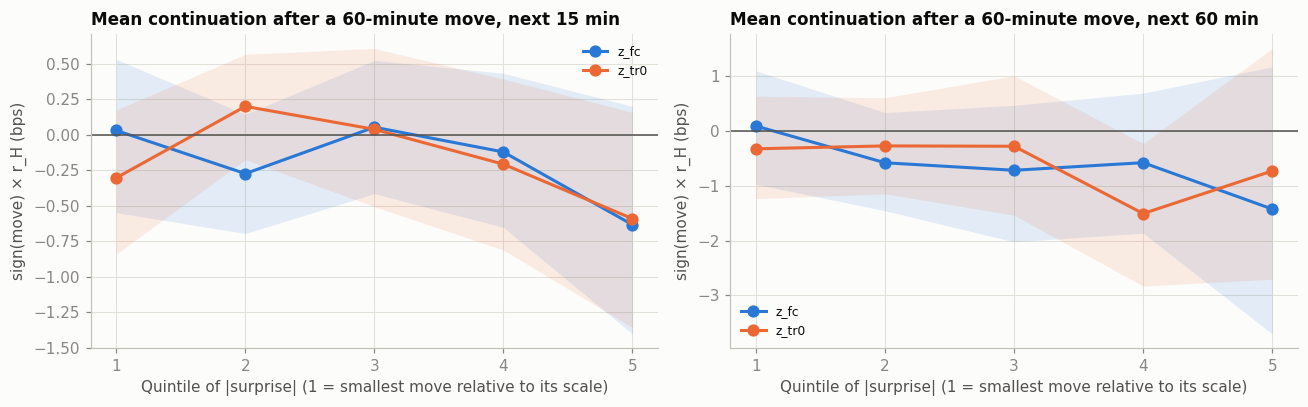

In [33]:
SURP = {"z_fc": Z_FC_RAW, "z_tr0": Z_TR0, "z_now": Z_NOW, "raw move": M_MOVE}
rows = []
for H in CFG_H:
    ics = {k: ic_boot(v, RE[H], EVM) for k, v in SURP.items()}
    for k in SURP:
        r_ = {"H": H, "measure": k, "IC with r_H/e": ics[k][0], "lo": ci(ics[k][1])[0], "hi": ci(ics[k][1])[1],
              "corr with z_tr0 (ranks)": stats.spearmanr(SURP[k][EVM], Z_TR0[EVM])[0]}
        if k != "z_fc":
            r_["IC(z_fc) − IC(this)"] = ics["z_fc"][0] - ics[k][0]
            r_["diff lo"], r_["diff hi"] = ci(ics["z_fc"][1] - ics[k][1])
        rows.append(r_)
    sa, sb = normal_scores(Z_FC_RAW, EVM), normal_scores(Z_NOW, EVM)
    resid = sa - (np.sum(sa[EVM] * sb[EVM]) / np.sum(sb[EVM] ** 2)) * sb
    icr, icrb = ic_boot(resid, RE[H], EVM)
    rows.append({"H": H, "measure": "z_fc after removing z_now", "IC with r_H/e": icr, "lo": ci(icrb)[0], "hi": ci(icrb)[1]})
SURPT = pd.DataFrame(rows).set_index(["H", "measure"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(SURPT)

# Continuation by surprise size. Quintile cut points from decisions before February 2026 (training era for the evaluation blocks).
pre2 = ROWS2 & (TN < BLOCKS[1][0].value)
rows = []
for H in CFG_H:
    cont = np.sign(M_MOVE) * G_FH[H]
    for k in ("z_fc", "z_tr0"):
        a = np.abs(SURP[k]); qs = np.quantile(a[pre2], [.2, .4, .6, .8])
        q = np.digitize(a, qs)
        for qi in range(5):
            mq = EVM & (q == qi) & np.isfinite(cont)
            mu, (lo, hi), _ = gross_stats(cont, mq)
            rows.append({"H": H, "measure": k, "|z| quintile": qi + 1, "median |z|": np.median(a[mq] / (KAPPA[("fc", 2)] if k == "z_fc" else KAPPA[("tr", 2)])),
                         "median |move| (bps)": 1e4 * np.median(np.abs(M_MOVE[mq])), "continuation (bps)": mu, "lo": lo, "hi": hi, "n": int(mq.sum())})
CONT = pd.DataFrame(rows).set_index(["H", "measure", "|z| quintile"])
display(CONT.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, H in zip(axes, CFG_H):
    for k, col in (("z_fc", C["blue"]), ("z_tr0", C["orange"])):
        d = CONT.loc[(H, k)]
        ax.plot(d.index, d["continuation (bps)"], marker="o", color=col, label=k)
        ax.fill_between(d.index, d["lo"], d["hi"], color=col, alpha=.12, lw=0)
    ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(1, 6)); ax.set_xlabel("Quintile of |surprise| (1 = smallest move relative to its scale)")
    ax.set_title(f"Mean continuation after a 60-minute move, next {H} min"); ax.set_ylabel("sign(move) × r_H (bps)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**A forecast-based surprise measure carries the same mild reversal as ordinary normalisation, and nothing more that can be detected.**

* **All four measures point to mild reversal.** ICs with the next return are −0.013 to −0.018. At 15 minutes the intervals exclude zero for `z_fc`, `z_now` and the raw move; at 60 minutes all intervals include zero.
* **Normalising by the forecast barely reorders moves.** `z_fc` and `z_tr0` have a rank correlation of 0.99. Large moves are large under any of these scales, because forecast and trailing volatility rank periods almost identically.
* **The paired differences are tiny and not significant.** `z_fc` minus `z_tr0` is −0.0025 [−0.0049, +0.0003] at 15 minutes and −0.0030 [−0.0074, +0.0010] at 60. The point estimates lean toward slightly stronger reversal for the forecast version, which is too little to separate from zero with these data. Removing `z_now` leaves `z_fc` with an IC of −0.010 [−0.023, +0.004] and −0.017 [−0.036, +0.003]. The residual has wide intervals because it is a small sliver of the score's variation.
* **By surprise size**, reversal concentrates in the largest quintile: about −0.6 bps over the next 15 minutes, for both measures, with intervals that include zero. The patterns for `z_fc` and `z_tr0` are not distinguishable.

In [34]:
rows = []
for H in CFG_H:
    ys = UP[H]; ms = EVM & np.isfinite(ys); ym = np.clip(RE[H], -4, 4); mm = EVM & np.isfinite(ym); den = np.where(mm, ym ** 2, 0)
    LLO = logloss(PRED2S[(H, "sign", "O")], ys); SEO = (PRED2S[(H, "mag", "O")] - ym) ** 2
    LLT = logloss(PRED2S[(H, "sign", "O+S_tr")], ys); SET = (PRED2S[(H, "mag", "O+S_tr")] - ym) ** 2
    icO = ic_boot(PRED2S[(H, "mag", "O")], RE[H], mm)
    for v in ("O+S_tr", "O+S_fc"):
        LL = logloss(PRED2S[(H, "sign", v)], ys); SE = (PRED2S[(H, "mag", v)] - ym) ** 2; icv = ic_boot(PRED2S[(H, "mag", v)], RE[H], mm)
        r_ = {"H": H, "variant": v, "sign gain vs O (mnats)": 1e3 * (LLO - LL)[ms].mean(), "lo": 1e3 * ci(bsum2(LLO - LL, ms) / bsum2(np.ones(N), ms))[0],
              "hi": 1e3 * ci(bsum2(LLO - LL, ms) / bsum2(np.ones(N), ms))[1], "mag gain vs O (x100)": 100 * (SEO - SE)[mm].sum() / den[mm].sum(),
              "mag lo": 100 * ci(bsum2(SEO - SE, mm) / bsum2(den, mm))[0], "mag hi": 100 * ci(bsum2(SEO - SE, mm) / bsum2(den, mm))[1], "ΔIC vs O": icv[0] - icO[0]}
        if v == "O+S_fc":
            r_["sign: fc − tr (mnats)"] = 1e3 * (LLT - LL)[ms].mean(); r_["fc−tr lo"], r_["fc−tr hi"] = (1e3 * x for x in ci(bsum2(LLT - LL, ms) / bsum2(np.ones(N), ms)))
            r_["mag: fc − tr (x100)"] = 100 * (SET - SE)[mm].sum() / den[mm].sum()
        rows.append(r_)
SURPM = pd.DataFrame(rows).set_index(["H", "variant"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(SURPM)

sign gain vs O (mnats)      lo     hi  mag gain vs O (x100)  mag lo  mag hi  ΔIC vs O  sign: fc − tr (mnats)  fc−tr lo  fc−tr hi  mag: fc − tr (x100)
H  variant                                                                                                                                                       
15 O+S_tr                  -0.1753 -0.3828 0.0205                0.0066 -0.0226  0.0369   -0.0002                    NaN       NaN       NaN                  NaN
   O+S_fc                   0.0066 -0.1753 0.1815                0.0083 -0.0267  0.0453    0.0022                 0.1819    0.0534    0.3118               0.0017
60 O+S_tr                   0.1782 -0.1663 0.5780               -0.0503 -0.1479  0.0446    0.0007                    NaN       NaN       NaN                  NaN
   O+S_fc                   0.1422 -0.1811 0.4841               -0.1172 -0.2483  0.0071   -0.0010                -0.0361   -0.2349    0.1452              -0.0669

**Inside the directional model, neither surprise column helps.** Adding `z_fc` to the original features changes the sign model by +0.01 [−0.18, +0.18] milli-nats at 15 minutes and +0.14 [−0.18, +0.48] at 60. The magnitude model is slightly worse at 60 minutes (−0.12 [−0.25, +0.01] skill points ×100). The one interval excluding zero, `z_fc` against `z_tr0` for the sign at 15 minutes (+0.18 [+0.05, +0.31]), comes from the trailing version doing slightly **worse** than `O` (−0.18), not from the forecast version doing better. It is the size of change that the placebo refits in section 14 produce by chance. The original features already contain `z_ret_60`, which is essentially `z_now`.

## 16. `CORRECTION` The expected payoff of each barrier trade, and the selection results it affects

### 16.1 The full expected payoff

For configuration `c` with barriers `+u·e` and `−l·e`, and the execution of section 9 (the target fills exactly at its barrier, the stop at the worst price of the touching second, and an untouched trade exits at the last price before expiry), the expected gross payoff of a **long** in units of `e` is

$$EV_{long,c} = P_c(U)\,u \;-\; P_c(L)\,(l + s^{L}_c) \;+\; P_c(N)\,\mu^{N}_c,$$

and of a **short**

$$EV_{short,c} = P_c(L)\,l \;-\; P_c(U)\,(u + s^{U}_c) \;-\; P_c(N)\,\mu^{N}_c,$$

where:

* `P_c(U), P_c(L), P_c(N)` come from the out-of-sample three-class first stage (section 13);
* `μ^N_c = E[r_H / e | neither]` is the **timeout payoff**, from the out-of-sample `n` first-stage regression trained only on decisions where neither barrier was reached. Part I omitted this term;
* `s^L_c`, `s^U_c` are the average stop slippage beyond the barrier, in units of `e`, measured on each block's training decisions (constants per block, horizon, configuration and side).

The result is converted to bps by multiplying by `e`. **Why components rather than a direct regression of the payoff:** it corrects the Part I rule with the smallest change, keeps every term interpretable, and makes the missing timeout term visible. Its weakness is that errors in the three probabilities and in `μ^N` can add up. Section 16.2 therefore checks its calibration directly against realised payoffs.

**Under a driftless walk, the full expected value is zero apart from slippage.** The omitted term is exactly what makes the Part I `EV` of long A and short B positive.

**The Part I `POST-HOC` geometry-relative score** (`EV_PartI − EV_PartI under G-ρ`) is recomputed below with out-of-sample inputs as a **diagnostic** only. It removes the bias that geometry predicts but does not estimate the timeout payoff. It is not an expected value.

### 16.2 Is the corrected expected value calibrated?

Average stop slippage beyond the barrier, in units of e (long stop, short stop), by horizon, configuration and block:


long   short
15 A 1  0.1204  0.0656
     2  0.1208  0.0693
     3  0.1214  0.0731
   B 1  0.0676  0.1086
     2  0.0726  0.1172
     3  0.0731  0.1282
60 A 1  0.0654  0.0452
     2  0.0724  0.0501
     3  0.0748  0.0543
   B 1  0.0473  0.0714
     2  0.0507  0.0820
     3  0.0508  0.0866

G-rho constant fitted on out-of-sample training forecasts: {'H15 Feb–Apr': np.float64(1.24), 'H15 May–Jul': np.float64(1.2), 'H15 Aug–Oct': np.float64(1.2), 'H60 Feb–Apr': np.float64(1.22), 'H60 May–Jul': np.float64(1.2), 'H60 Aug–Oct': np.float64(1.18)} (Part I, in-sample: 1.16-1.28)


mean EV (bps)  mean realised (bps)  rank corr  slope realised on EV
H  EV                                  trade                                                                       
15 full EV                             long A          -0.355               -0.166      0.029                 0.321
                                       short A         -0.131               -0.304      0.039                 0.368
                                       long B          -0.495               -0.279      0.047                 0.143
                                       short B          0.016               -0.218      0.042                 0.144
   Part I EV (no timeout, no slippage) long A           2.813               -0.166      0.033                 0.177
                                       short A         -2.813               -0.304      0.028                 0.225
                                       long B          -3.114               -0.279      0.050                 0.068
                                       short B          3.114               -0.218      0.055                 0.008
   geometry-relative diagnostic        long A          -0.960               -0.166      0.003                 0.259
                                       short A          0.960               -0.304      0.007                 0.281
                                       long B           0.659               -0.279      0.002                -0.047
                                       short B         -0.659               -0.218     -0.001                -0.098
60 full EV                             long A          -0.970               -0.624      0.011                 0.239
                                       short A          0.294               -0.108      0.016                 0.259
                                       long B          -1.069               -0.665      0.066                 0.416
                                       short B          0.379               -0.050      0.061                 0.415
   Part I EV (no timeout, no slippage) long A           4.776               -0.624      0.011                 0.119
                                       short A         -4.776               -0.108      0.008                 0.140
                                       long B          -6.465               -0.665      0.057                 0.197
                                       short B          6.465               -0.050      0.060                 0.171
   geometry-relative diagnostic        long A          -2.908               -0.624     -0.017                 0.174
                                       short A          2.908               -0.108     -0.013                 0.185
                                       long B           1.219               -0.665      0.032                 0.423
                                       short B         -1.219               -0.050      0.030                 0.381

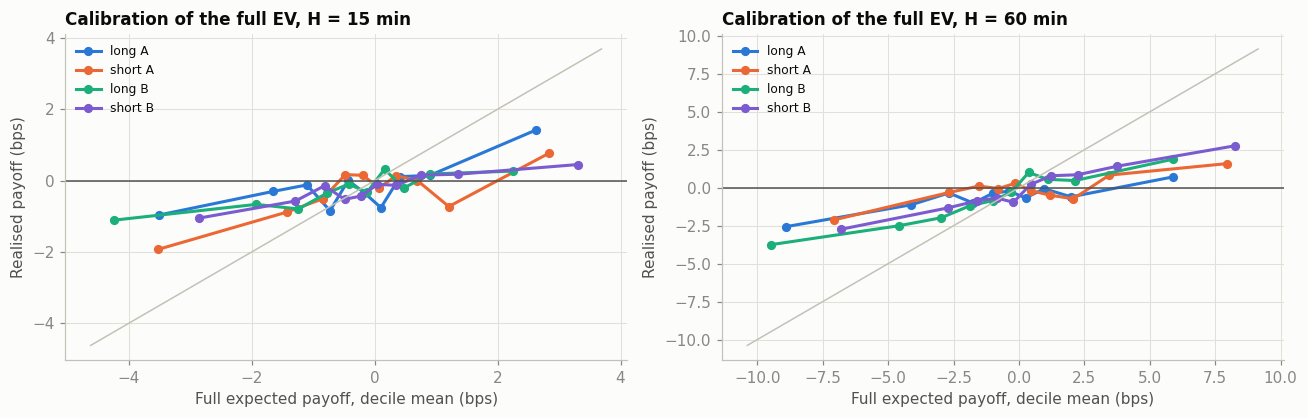

In [35]:
PAY4 = {H: np.column_stack([payoff(H, "A", 1), payoff(H, "A", -1), payoff(H, "B", 1), payoff(H, "B", -1)]) for H in CFG_H}
TRADES4 = ["long A", "short A", "long B", "short B"]

def train_mask(b):
    return ELIG & ~CRASH & (TN + H_MAX * 60 * 10**9 <= BLOCKS[b][0].value - EMBARGO_NS)
SLIP = {}
for H in CFG_H:
    e_ = E_SIG[ti] * np.sqrt(H); p0_ = OUT[H]["p0"]
    for c, (u, l) in CONFIGS.items():
        sl_ = (-l * e_ - np.log(OUT[H]["pdn"][:, l - 1] / p0_)) / e_          # long stop: extra loss beyond the lower barrier
        su_ = (np.log(OUT[H]["pu"][:, u - 1] / p0_) - u * e_) / e_            # short stop: extra loss beyond the upper barrier
        for b in EVAL_B:
            tm = train_mask(b)
            SLIP[(H, c, b)] = (np.nanmean(sl_[tm & (LAB[(H, c)] == 1)]), np.nanmean(su_[tm & (LAB[(H, c)] == 0)]))
print("Average stop slippage beyond the barrier, in units of e (long stop, short stop), by horizon, configuration and block:")
display(pd.DataFrame({k: v for k, v in SLIP.items()}, index=["long", "short"]).T.round(4))

def block_of_rows():
    bl = P["block"].to_numpy().copy(); bl[bl < 1] = 1          # training rows before February use the first evaluation block's constants
    return bl
BLK = block_of_rows()

def ev_full(H, kind="full"):
    out = np.full((N, 4), np.nan)
    for ci_, (c, (u, l)) in enumerate(CONFIGS.items()):
        Pm = FS[(f"mc{c}", H)]; mu = FS[(f"n{c}", H)]
        sL = np.array([SLIP[(H, c, b)][0] for b in EVAL_B]); sU = np.array([SLIP[(H, c, b)][1] for b in EVAL_B])
        sl_, su_ = sL[np.clip(BLK, 1, 3) - 1], sU[np.clip(BLK, 1, 3) - 1]
        if kind == "full":
            evl = Pm[:, 0] * u - Pm[:, 1] * (l + sl_) + Pm[:, 2] * mu
            evs = Pm[:, 1] * l - Pm[:, 0] * (u + su_) - Pm[:, 2] * mu
        elif kind == "part1":
            evl = Pm[:, 0] * u - Pm[:, 1] * l; evs = -evl
        out[:, 2 * ci_], out[:, 2 * ci_ + 1] = evl, evs
    return out * E_BPS[H][:, None]

# G-rho with out-of-sample volatility forecasts; the constant c is fitted on out-of-sample training forecasts.
GR_OOS, C_OOS = {}, {}
for H in CFG_H:
    g3 = {c: np.full((N, 3), np.nan) for c in CONFIGS}
    for b in EVAL_B:
        tm = train_mask(b) & FS_OK & np.isfinite(FS[("rv", H)])
        s_tr = np.exp(FS[("rv", H)][tm] / 2)
        ya, yb = (LAB[(H, "A")][tm] != 2).astype(float), (LAB[(H, "B")][tm] != 2).astype(float)
        ll = [logloss(1 - geo3(1, 2, cc * s_tr)[..., 2], ya).mean() + logloss(1 - geo3(1, 2, cc * s_tr)[..., 2], yb).mean() for cc in CGRID]
        cb = CGRID[int(np.argmin(ll))]; C_OOS[(H, b)] = cb
        rows_b = np.flatnonzero((BLK == b) & FS_OK & np.isfinite(FS[("rv", H)]))
        for c, (u, l) in CONFIGS.items():
            g3[c][rows_b] = geo3(u, l, cb * np.exp(FS[("rv", H)][rows_b] / 2))
    GR_OOS[H] = g3
print("G-rho constant fitted on out-of-sample training forecasts:", {f"H{k[0]} {BLOCK_LABELS[k[1]]}": round(v, 3) for k, v in C_OOS.items()},
      "(Part I, in-sample: 1.16-1.28)")

def ev_geodiag(H):
    out = np.full((N, 4), np.nan)
    for ci_, (c, (u, l)) in enumerate(CONFIGS.items()):
        Pm, Gm = FS[(f"mc{c}", H)], GR_OOS[H][c]
        d = (Pm[:, 0] - Gm[:, 0]) * u - (Pm[:, 1] - Gm[:, 1]) * l
        out[:, 2 * ci_], out[:, 2 * ci_ + 1] = d, -d
    return out * E_BPS[H][:, None]

EVS = {H: {"full EV": ev_full(H, "full"), "Part I EV (no timeout, no slippage)": ev_full(H, "part1"), "geometry-relative diagnostic": ev_geodiag(H)} for H in CFG_H}
EVR = EVM.copy()                     # the common Part II sample (eligible, first stage and surprise available)
rows = []
for H in CFG_H:
    for k, ev in EVS[H].items():
        for t_i, tn in enumerate(TRADES4):
            m = EVR & np.isfinite(ev[:, t_i]) & np.isfinite(PAY4[H][:, t_i])
            x, y = ev[m, t_i], PAY4[H][m, t_i]
            rows.append({"H": H, "EV": k, "trade": tn, "mean EV (bps)": x.mean(), "mean realised (bps)": y.mean(),
                         "rank corr": stats.spearmanr(x, y)[0], "slope realised on EV": np.polyfit(x, y, 1)[0] if x.std() > 0 else np.nan})
EVCAL = pd.DataFrame(rows).set_index(["H", "EV", "trade"]); display(EVCAL.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, H in zip(axes, CFG_H):
    for t_i, col in zip(range(4), (C["blue"], C["orange"], C["aqua"], C["purple"])):
        m = EVR & np.isfinite(EVS[H]["full EV"][:, t_i])
        x, y = EVS[H]["full EV"][m, t_i], PAY4[H][m, t_i]
        q = pd.qcut(x, 10, labels=False, duplicates="drop")
        g = pd.DataFrame({"x": x, "y": y, "q": q}).groupby("q").mean()
        ax.plot(g["x"], g["y"], marker="o", ms=5, color=col, label=TRADES4[t_i])
    lim = ax.get_xlim(); ax.plot(lim, lim, color=AXIS, lw=1); ax.axhline(0, color=INK2, lw=1)
    ax.set_xlabel("Full expected payoff, decile mean (bps)"); ax.set_ylabel("Realised payoff (bps)"); ax.set_title(f"Calibration of the full EV, H = {H} min"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

**The full expected value removes Part I's bias. Its ranking power is weak.**

* **Bias.** The Part I expression has means of ±2.8 to ±6.5 bps per trade against realised means between −0.05 and −0.67. It is off by an order of magnitude more than any signal, which is the omitted timeout payoff. The geometry-relative diagnostic is biased too (±0.7 to ±2.9 bps), confirming that it is not an expected value. The **full EV** has means within about 0.2–0.4 bps of the realised ones. The remaining gap leans toward shorts at 60 minutes (full EV +0.30 and +0.38 bps for the two shorts against −0.11 and −0.05 realised), consistent with the training-period drift.
* **Ranking.** The rank correlation between the full EV and the realised payoff is 0.01–0.07, and realised payoffs move 0.14–0.42 bps per predicted bp. There is some ranking information, strongest for configuration B at 60 minutes (0.06), but predicted differences are two to seven times larger than realised ones.
* **Slippage** is 0.05–0.12 `e` beyond the stop barrier, larger for the near stop and at 15 minutes. It is stable across blocks and enters the EV as a known cost.

### 16.3 Selection by expected payoff, with controls on the same opportunities

For each EV definition: choose the trade with the largest `EV` among the four, and trade only if that `EV` is in the top 30% of its values on the block's training decisions (whose first-stage inputs are out of sample). Controls on the **same selected decisions**: a random side within the chosen configuration, and a random choice among the four trades. Control on the **same trade types**: the same mix placed on 200 random sets of evaluation decisions. "All decisions" applies the best-of-four choice everywhere, without the threshold. The executable version holds one position at a time and exits at the actual barrier touch or expiry.

In [36]:
rng_e = np.random.default_rng(SEED + 123)
rows = []
for H in CFG_H:
    PAY = PAY4[H]
    for k, ev in EVS[H].items():
        okr = np.isfinite(ev).all(1)
        best = np.argmax(np.where(np.isfinite(ev), ev, -np.inf), axis=1); bev = ev[np.arange(N), best]
        thr = np.full(N, np.nan)
        for b in EVAL_B:
            tm = train_mask(b) & FS_OK & okr
            thr[BLK == b] = np.quantile(bev[tm], 1 - RETENTION)
        g = PAY[np.arange(N), best]; rs = 0.5 * (g + PAY[np.arange(N), best ^ 1]); r4 = np.nanmean(PAY, axis=1)
        for pol, m in (("all decisions", EVR & okr), ("top 30%", EVR & okr & (bev >= thr))):
            mu, (lo, hi), b_ = gross_stats(g, m)
            _, _, brs = gross_stats(rs, m); _, _, br4 = gross_stats(r4, m)
            r_ = {"H": H, "EV": k, "policy": pol, "share": m.sum() / (EVR & okr).sum(), "mix (LA, SA, LB, SB)": np.bincount(best[m], minlength=4).tolist(),
                  "mean EV (bps)": np.nanmean(bev[m]), "gross / trade": mu, "lo": lo, "hi": hi,
                  "vs random side": mu - np.nanmean(rs[m]), "rs lo": ci(b_ - brs)[0], "rs hi": ci(b_ - brs)[1],
                  "vs random trade": mu - np.nanmean(r4[m]), "r4 lo": ci(b_ - br4)[0], "r4 hi": ci(b_ - br4)[1]}
            if pol == "top 30%":
                pool = np.flatnonzero(EVR & okr); idx = np.flatnonzero(m)
                draws = np.array([np.nanmean(PAY[rng_e.choice(pool, idx.size, replace=False), best[idx]]) for _ in range(200)])
                r_["same types, random rows"] = draws.mean(); r_["pct of policy"] = 100 * np.mean(draws < mu)
                # Executable: one position at a time, exit at the first barrier touch or expiry of the chosen configuration.
                cfg = best // 2; u_ = np.where(cfg == 0, 1, 2); l_ = np.where(cfg == 0, 2, 1)
                tU = np.where(u_ == 1, OUT[H]["tu"][:, 0], OUT[H]["tu"][:, 1]); tL = np.where(l_ == 1, OUT[H]["td"][:, 0], OUT[H]["td"][:, 1])
                first = np.where((tU >= 0) & ((tL < 0) | (tU <= tL)), tU, np.where(tL >= 0, tL, H * 60))
                sq = greedy(m, TN + (first + 1) * 10**9)
                mu_s, (lo_s, hi_s), _ = gross_stats(g, sq)
                r_["exec trades"] = int(sq.sum()); r_["exec gross"] = mu_s; r_["exec lo"] = lo_s; r_["exec hi"] = hi_s
            rows.append(r_)
SEL2 = pd.DataFrame(rows).set_index(["H", "EV", "policy"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(SEL2)
print("Costs, shown separately: net per trade of the executable top-30% full-EV policy:",
      {H: {f"@{c}": round(SEL2.loc[(H, "full EV", "top 30%"), "exec gross"] - c, 2) for c in (0, 2, 4, 10)} for H in CFG_H})

share        mix (LA, SA, LB, SB)  mean EV (bps)  gross / trade     lo    hi  vs random side  rs lo  rs hi  vs random trade  r4 lo  r4 hi  same types, random rows  \
H  EV                                  policy                                                                                                                                                                              
15 full EV                             all decisions  1.000    [7223, 9689, 8761, 9374]          1.342          0.068 -0.142 0.294           0.311  0.099  0.539            0.309  0.098  0.538                      NaN   
                                       top 30%        0.243    [1748, 2303, 1524, 2946]          3.223          0.732  0.097 1.426           1.066  0.441  1.747            1.080  0.457  1.763                   -0.260   
   Part I EV (no timeout, no slippage) all decisions  1.000      [15388, 67, 26, 19566]          3.685         -0.002 -0.230 0.236           0.247  0.021  0.487            0.240  0.016  0.480                      NaN   
                                       top 30%        0.284         [4183, 34, 5, 5717]          6.605          0.238 -0.391 0.933           0.599 -0.036  1.297            0.590 -0.036  1.290                   -0.199   
   geometry-relative diagnostic        all decisions  1.000  [1800, 16899, 13614, 2734]          1.760         -0.054 -0.301 0.213           0.182 -0.066  0.450            0.187 -0.062  0.457                      NaN   
                                       top 30%        0.293      [507, 5201, 3652, 898]          3.407         -0.381 -1.032 0.291          -0.056 -0.720  0.611           -0.041 -0.704  0.635                   -0.271   
60 full EV                             all decisions  1.000   [7072, 9865, 8067, 10043]          3.436          0.252 -0.416 0.928           0.613 -0.052  1.303            0.614 -0.045  1.310                      NaN   
                                       top 30%        0.289    [1723, 3056, 1805, 3535]          7.471          1.063 -0.724 2.962           1.534 -0.250  3.433            1.548 -0.243  3.454                   -0.302   
   Part I EV (no timeout, no slippage) all decisions  1.000     [12749, 93, 106, 22099]          7.503          0.334 -0.355 1.075           0.715  0.020  1.464            0.695  0.003  1.439                      NaN   
                                       top 30%        0.282        [2688, 22, 30, 7129]         13.520          1.863  0.233 3.441           2.382  0.751  3.982            2.355  0.729  3.935                   -0.204   
   geometry-relative diagnostic        all decisions  1.000   [899, 19959, 11956, 2233]          4.271          0.379 -0.295 1.129           0.726  0.054  1.469            0.741  0.070  1.486                      NaN   
                                       top 30%        0.313     [336, 6874, 2743, 1012]          7.917          1.035 -0.582 2.710           1.480 -0.142  3.159            1.491 -0.133  3.165                   -0.268   

                                                      pct of policy  exec trades  exec gross  exec lo  exec hi  
H  EV                                  policy                                                                   
15 full EV                             all decisions            NaN          NaN         NaN      NaN      NaN  
                                       top 30%              100.000     6285.000       0.876    0.265    1.534  
   Part I EV (no timeout, no slippage) all decisions            NaN          NaN         NaN      NaN      NaN  
                                       top 30%               96.500     6412.000       0.282   -0.349    0.950  
   geometry-relative diagnostic        all decisions            NaN          NaN         NaN      NaN      NaN  
                                       top 30%               28.000     7101.000      -0.057   -0.713    0.692  
60 full EV                             all decisions            NaN  

Costs, shown separately: net per trade of the executable top-30% full-EV policy: {15: {'@0': np.float64(0.88), '@2': np.float64(-1.12), '@4': np.float64(-3.12), '@10': np.float64(-9.12)}, 60: {'@0': np.float64(1.72), '@2': np.float64(-0.28), '@4': np.float64(-2.28), '@10': np.float64(-8.28)}}


**The corrected expected value is unbiased, but it does not change the economic conclusion.**

* **Full EV, top 30%:** +0.73 bps [0.10, 1.43] per trade at 15 minutes, +1.07 [0.44, 1.75] above a random side on the same decisions, above all 200 same-type random-row draws, and +0.88 [0.27, 1.53] in the executable version. At 60 minutes: +1.06 [−0.72, 2.96], executable +1.72 [−0.29, 3.82]. Applied to every decision without the threshold, the best-of-four choice earns only +0.07 and +0.25 bps, so the value is concentrated in the most confident 30%.
* **The trade mix is now balanced** across all four trades, instead of 99% long A or short B under the Part I expression.
* **The Part I expression, re-run with out-of-sample inputs,** earns +0.24 [−0.39, 0.93] at 15 minutes and +1.86 [0.23, 3.44] at 60, which is more than the full EV at 60 minutes. Its value is the side choice within the long-A/short-B pair (+2.38 against a random side). Correcting the payoff makes the rule interpretable and unbiased, but **it does not increase selection value in this sample**. The differences between EV definitions are well inside their intervals.
* **The geometry-relative diagnostic** earns −0.38 at 15 minutes and +1.04 at 60. The Part I `POST-HOC` result at 60 minutes (+1.08) is reproduced in point estimate, but not at 15 minutes.
* **Costs, separately:** the executable full-EV policy nets −1.12 and −0.28 bps per trade at a 2 bps round trip, and about −8 to −9 at 10 bps.
* **Overlap:** the "top 30%" rows average over decisions whose barrier windows overlap. Only the executable column describes a strategy that could hold its positions, and it is still frictionless apart from stop slippage.

### 16.4 Section 9 and section 8.7 re-run with out-of-sample inputs and thresholds

The `D_hit` side rule and the attainment gate from section 9, and the implied-drift slope from section 8.7, now use the monthly-chained first stage. Centring and thresholds come from out-of-sample predictions on each block's training decisions. Evaluation is on February–October 2026 only, so the numbers are not directly comparable with section 9, which also included November–January.

In [37]:
rows = []
DH = {H: FS[("hitA", H)] - FS[("hitB", H)] for H in CFG_H}
for H in CFG_H:
    med = np.full(N, np.nan)
    for b in EVAL_B:
        med[BLK == b] = np.nanmedian(DH[H][train_mask(b) & FS_OK])
    s = DH[H] - med
    for c in CONFIGS:
        L_, S_ = payoff(H, c, +1), payoff(H, c, -1); rs = 0.5 * (L_ + S_)
        g = np.where(s > 0, L_, S_)
        thr = np.full(N, np.nan)
        for b in EVAL_B:
            thr[BLK == b] = np.nanquantile(FS[(f"hit{c}", H)][train_mask(b) & FS_OK], 1 - RETENTION)
        gate = EVR & (FS[(f"hit{c}", H)] >= thr)
        for lab, gg, m in (("side from D_hit, all", g, EVR), ("random side, all", rs, EVR), ("attainment gate, random side", rs, gate), ("attainment gate, side from D_hit", g, gate)):
            mu, (lo, hi), b_ = gross_stats(gg, m); _, _, brs = gross_stats(rs, m)
            rows.append({"H": H, "config": c, "policy": lab, "share": m.sum() / EVR.sum(), "hit rate": (LAB[(H, c)] != 2)[m].mean(), "gross / trade": mu, "lo": lo, "hi": hi,
                         "vs random side": mu - np.nanmean(rs[m]), "vs lo": ci(b_ - brs)[0], "vs hi": ci(b_ - brs)[1], "long share": np.mean(s[m] > 0)})
SEC9 = pd.DataFrame(rows).set_index(["H", "config", "policy"])
with pd.option_context("display.float_format", "{:.3f}".format):
    display(SEC9)

rows = []
for H in CFG_H:
    med = np.full(N, np.nan)
    for b in EVAL_B:
        med[BLK == b] = np.nanmedian(DH[H][train_mask(b) & FS_OK])
    mu_hat = (DH[H] - med) / K_SLOPE[1.0]; m = EVR & np.isfinite(mu_hat) & np.isfinite(RE[H]); y = np.clip(RE[H], -6, 6)
    sl = np.sum(mu_hat[m] * y[m]) / np.sum(mu_hat[m] ** 2); slb = bsum2(mu_hat * y, m) / bsum2(mu_hat ** 2, m)
    ic_, icb_ = ic_boot(DH[H], RE[H], m)
    rows.append({"H": H, "sd of implied drift (bps)": np.std(mu_hat[m] * E_BPS[H][m]), "slope realised on implied": sl, "lo": ci(slb)[0], "hi": ci(slb)[1],
                 "IC of D": ic_, "IC lo": ci(icb_)[0], "IC hi": ci(icb_)[1], "IC² (share of r/e variance ranked)": ic_ ** 2})
IMPL2 = pd.DataFrame(rows).set_index("H"); display(IMPL2.round(4))
print(f"Part II run time so far: {(time.time() - T2) / 60:.1f} min.")

share  hit rate  gross / trade     lo     hi  vs random side  vs lo  vs hi  long share
H  config policy                                                                                                                  
15 A      side from D_hit, all              1.000     0.306          0.018 -0.206  0.240           0.253  0.031  0.478       0.533
          random side, all                  1.000     0.306         -0.235 -0.254 -0.218           0.000  0.000  0.000       0.533
          attainment gate, random side      0.296     0.469         -0.360 -0.388 -0.333           0.000  0.000  0.000       0.659
          attainment gate, side from D_hit  0.296     0.469         -0.131 -0.624  0.344           0.229 -0.267  0.715       0.659
   B      side from D_hit, all              1.000     0.302          0.024 -0.198  0.248           0.273  0.057  0.503       0.533
          random side, all                  1.000     0.302         -0.248 -0.271 -0.228           0.000  0.000  0.000       0.533
          attainment gate, random side      0.287     0.469         -0.394 -0.430 -0.360           0.000  0.000  0.000       0.442
          attainment gate, side from D_hit  0.287     0.469         -0.097 -0.627  0.383           0.296 -0.233  0.782       0.442
60 A      side from D_hit, all              1.000     0.324          0.869  0.219  1.621           1.235  0.569  1.991       0.553
          random side, all                  1.000     0.324         -0.366 -0.401 -0.336           0.000  0.000  0.000       0.553
          attainment gate, random side      0.331     0.489         -0.529 -0.583 -0.478           0.000  0.000  0.000       0.644
          attainment gate, side from D_hit  0.331     0.489          0.458 -0.534  1.521           0.987 -0.021  2.040       0.644
   B      side from D_hit, all              1.000     0.330          0.897  0.217  1.648           1.254  0.574  2.007       0.553
          random side, all                  1.000     0.330         -0.357 -0.388 -0.330           0.000  0.000  0.000       0.553
          attainment gate, random side      0.325     0.508         -0.546 -0.600 -0.500           0.000  0.000  0.000       0.408
          attainment gate, side from D_hit  0.325     0.508          1.049 -0.028  2.204           1.595  0.514  2.772       0.408

,sd of implied drift (bps),slope realised on implied,lo,hi,IC of D,IC lo,IC hi,IC² (share of r/e variance ranked)
H,,,,,,,,
15,3.3989,0.2035,0.0991,0.3047,0.0311,0.0167,0.0452,0.0010
60,8.4521,0.1330,0.0081,0.2574,0.0233,0.0041,0.0433,0.0005


Part II run time so far: 15.5 min.


**With out-of-sample inputs and thresholds, the `D_hit` side rule looks somewhat stronger at 60 minutes. Nothing else from section 9 changes.**

* **Side from `D_hit` at 60 minutes:** +0.87 [0.22, 1.62] and +0.90 [0.22, 1.65] bps gross per decision for A and B, and +1.24 [0.57, 1.99] above a random side. Part I reported +0.55 and +0.36 (+0.71 to +0.90 above a random side) on a window that also included November–January, with in-sample centring. At 15 minutes: about zero gross, +0.25 to +0.27 above a random side, with intervals above zero.
* **The out-of-sample centring leaves a 55% long share.** The training-period median of `D` sits slightly below the test-period one. Always long lost money in the test year (section 9), so the lean did not create the gain.
* **The attainment gate** reaches a barrier 47–51% of the time against 30–33% overall. With a random side it loses more (stop slippage scales with the move). With the `D_hit` side it is not better than without the gate. Section 9's conclusion, that attainment selects size and not direction, holds.
* **Implied drift with out-of-sample centring:** slope 0.20 [0.10, 0.30] at 15 minutes and 0.13 [0.01, 0.26] at 60, essentially as in Part I. The IC of `D` is 0.031 and 0.023, so its rank relation explains about 0.05–0.1% of the variance of `r_H/e`. That small number, not the calibration slope, measures how little of the variation in `D` is useful.

## 17. Final answer after the revision

All findings below come from data that was explored before (`EXPLORATORY`). Statistical evidence, effect size and economic relevance are given separately.

| # | Question | Answer | Statistical evidence | Effect size | Economic relevance |
|---|---|---|---|---|---|
| 1 | Does predicted volatility improve direction or signed-return prediction beyond the original features? | **No** | `O+V` sign gain −0.01 (15 min) and +0.25 milli-nats (60 min), inside the placebo range (+0.19 to +0.46); magnitude gain −0.02 and −0.03 | ΔAUC 0.000 and +0.0015 | None |
| 2 | Do mirrored-barrier forecasts add incremental information? | **Not reliably; one weak candidate** | `O+M` alone: not consistent (15 min gain vanishes in `O+V+M`; 60 min inside placebo range). `O+V+M` sign at 60 min: +0.56 milli-nats [0.12, 1.00], above all 5 placebos, positive in 3/3 blocks, but placebos average +0.29 | About +0.002 AUC attributable; magnitude models worse than zero in every variant | None. On its own, the out-of-sample `D_hit` side rule adds +1.2 bps over a random side at 60 min (gross, overlapping) |
| 3 | Does forecast-based surprise help predict continuation or reversal? | **No beyond ordinary normalisation** | All measures show mild reversal (IC −0.013 to −0.018); `z_fc − z_tr0` −0.003 [−0.005, +0.000] and −0.003 [−0.007, +0.001]; no model gain | Reversal about −0.6 bps over 15 min in the largest-surprise quintile, intervals include zero | None |
| 4 | Does combining these inputs improve gross trade selection? | **No** | 2 of 24 paired differences against `O` exclude zero (both `O+V`, 15 min), about chance | Executable gross +0.35 to +2.2 bps per trade | Negative at a 4 bps round trip for every variant |
| 5 | Which earlier conclusions change? | See below | | | |
| 6 | What deserves confirmation on new data? | See below | | | |

### 5. What changes after correcting the payoff and the validation

| Part I statement | After correction |
|---|---|
| Configuration choice by `EV` (9.1) | The Part I expression is biased by 3–6 bps per trade (it omits the timeout payoff and slippage). The full EV is unbiased to within 0.2–0.4 bps and spreads choices over all four trades. **Selection value does not improve** (+0.73 at 15 min, +1.06 at 60 min, against +0.24 and +1.86 for the Part I expression on the same inputs). The conclusion "no economic value" stands |
| `POST-HOC` "corrected" choice (9.1) | Relabelled a **geometry-relative diagnostic**. It is not an expected value (its means are biased by ±0.7 to ±2.9 bps). Its 60-minute result reproduces in point estimate (+1.04); its 15-minute result is negative |
| Side from `D_hit` (9) | With out-of-sample inputs and centring, on February–October: +0.87 to +0.90 bps gross at 60 min, +1.24 above a random side (Part I: +0.36 to +0.55). Still far below costs |
| `Stage-2` and volatility-implied mappings (6.4, 8.5) | The boundary overlap was real (1–5 rows per boundary) but changes no score by more than 0.0002 |
| "80–90% of `D` is noise" (8.7) | Withdrawn. The calibration slope (0.13–0.20 out of sample) shows the geometric scaling is too large; it does not by itself give a noise share. The direct measure of usefulness is the IC (0.02–0.03) |
| "Microstructure adds nothing" (6.1) | Restated: **no consistent** incremental benefit, with a few isolated small gains (`rv` at 5 min, `eff` at 5 and 15 min) |
| "Partly independent signal" (8.6) | A motivation that section 14 tested. Combining did **not** reliably improve prediction |
| "Oracle ceiling" (6.1) | A diagnostic benchmark, not a proven upper bound |
| Unchanged | Volatility is predictable (skill about 0.4 against persistence); magnitude targets are predictable mainly through volatility; attainment is mostly geometry plus volatility; no policy survives realistic costs |

**New negative finding.** Models of the expected signed return in units of `e` have **negative** squared-error skill against a zero forecast at both horizons, despite a positive IC. Their predicted sizes are two to three times too large. Any use of these models should rely on ranks, not predicted magnitudes.

**Method lesson.** Paired day-block intervals for model-versus-model differences capture only test-sample noise. Refitting with permuted columns produced gains whose intervals excluded zero. For incremental-feature tests, a placebo set is necessary, not optional.

### 6. What deserves confirmation on data after 31 October 2026

Nothing here is economically relevant at taker costs. These three items are worth a pre-registered **scientific** check, in this order:

1. **`D_hit` direction at 60 minutes** (chained first stage, out-of-sample centring): IC with `r_60/e` above zero, and the side rule's gross above a random side on the same decisions. This is the most stable item here: positive IC in every quarter of Part I and +1.2 bps above a random side in Part II.
2. **`O+V+M` versus `O` for the 60-minute sign model**: a log-loss gain above a pre-specified placebo set (for example 20 permuted refits). This is the only second-stage gain above all placebos, but only about half of it is attributable to the forecasts.
3. **Full-EV top-30% selection at 15 minutes**: gross above same-type random rows. The interval excluded zero here, but the 60-minute result did not, and the Part I expression did better at 60 minutes, so this is the weakest of the three.

The surprise measure, predicted volatility as a direction input, and the magnitude regressions do not merit further testing in this form.

### Limitations of Part II

* **Exploratory, nine months.** Part II evaluates February–October 2026 only, which earlier notebooks and Part I had already seen.
* **Second-stage training is short.** The first block's model trains on September 2025 to January 2026 (about 20,000 decisions), because out-of-sample first-stage forecasts begin in September 2025.
* **Placebo sets are small** (five draws), so "above all placebos" is a weak statement.
* **Frictionless apart from stop slippage.** No latency, fees, funding or impact; the delayed-entry pilot measured about 1 bp of drag at one-second latency.
* **Overlap.** Per-decision results overlap in time; only the executable columns hold one position at a time.

### Process record for Part II

* The Part II design (sections 11, 13, 14.1, 15.1 and 16.1) was written before any Part II outcome was computed.
* **Changes after a debugging run:** a masking bug in section 16 (rows outside the common sample) was fixed. After seeing that placebo refits can produce positive gains, the second-stage placebo set was raised from two to five draws and a real-against-placebo summary was added. No other design element was changed after seeing results.
* Part I code and numbers are unchanged. Interpretation wording marked *(revised wording)* was tightened as listed in the table above.

In [38]:
assert source_fingerprint() == FINGERPRINT_START, "Source data changed during the run."
print(f"Source data unchanged. Run time {(time.time() - T0) / 60:.1f} min; peak memory of the main process {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB. "
      f"Decisions {len(P):,}, test decisions {TEST.sum():,}, seed {SEED}.")

Source data unchanged. Run time 32.4 min; peak memory of the main process 3.0 GB. Decisions 67,242, test decisions 47,773, seed 20261108.
